<a href="https://colab.research.google.com/github/sbernacul/Clasificacion-Espaciotemporal-de-Siniestralidad-Vial-en-Madrid-mediante-XGBoost-2023-2025-/blob/main/TFM_Siniestralidad_Madrid_XGBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ENTORNO TECNOLÓGICO Y VERSIONES (ANEXO C - REPRODUCIBILIDAD)
Sistema operativo : Linux 6.6.159+
Python            : 3.13.18
pandas            : 2.2.3
numpy             : 2.4.6
scikit-learn      : 1.6.1
xgboost           : 3.4.1
seaborn           : 0.13.2
Semilla global    : 42

Archivos CSV a cargar (3):
Descargando: 300228-1-accidentes-trafico-detalle-csv.csv...
  - 300228-1-accidentes-trafico-detalle-csv.csv    | Filas:  51,067 | Cols: 19 | 2025-01-01 a 2025-12-31 | Años: [2025]
Descargando: 300228-2-accidentes-trafico-detalle-csv.csv...
  - 300228-2-accidentes-trafico-detalle-csv.csv    | Filas:  49,340 | Cols: 19 | 2024-01-01 a 2024-12-31 | Años: [2024]
Descargando: 300228-3-accidentes-trafico-detalle-csv.csv...
  - 300228-3-accidentes-trafico-detalle-csv.csv    | Filas:  48,830 | Cols: 19 | 2023-01-01 a 2023-12-31 | Años: [2023]

DIAGNÓSTICO INICIAL DE CARGA Y CONSOLIDACIÓN DE DATOS
Total registros cargados :   149,237
Total variables nativas  :        19

Desglose por año (regist

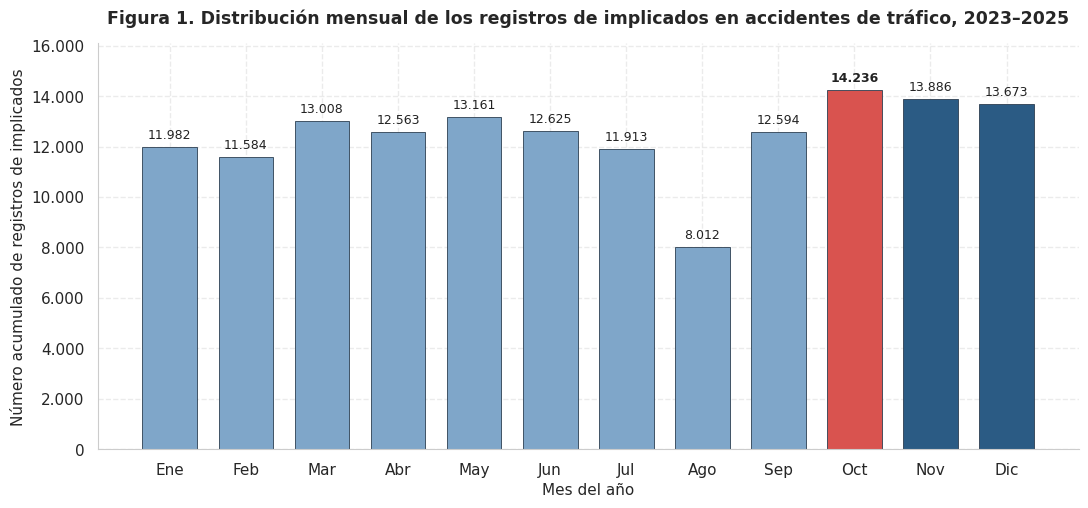


4.2.2.2 DISTRIBUCIÓN INTRADIARIA / PATRÓN BIMODAL (FIGURA 2)
 hora_int franja  registros_implicados  porcentaje
        0  00:00                  3656      2.4498
        1  01:00                  2813      1.8849
        2  02:00                  2124      1.4232
        3  03:00                  1720      1.1525
        4  04:00                  1440      0.9649
        5  05:00                  1827      1.2242
        6  06:00                  2816      1.8869
        7  07:00                  4254      2.8505
        8  08:00                  6415      4.2985
        9  09:00                  7749      5.1924
       10  10:00                  6249      4.1873
       11  11:00                  6764      4.5324
       12  12:00                  7685      5.1495
       13  13:00                  8797      5.8947
       14  14:00                 10073      6.7497
       15  15:00                  9524      6.3818
       16  16:00                  8767      5.8745
       17  17:00    

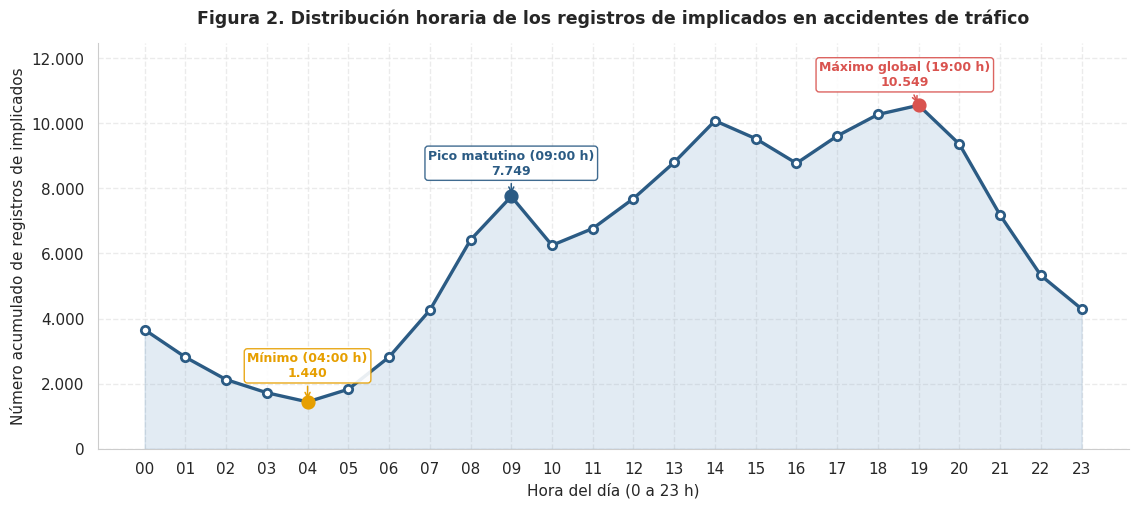


4.2.3 DISTRIBUCIÓN ESPACIAL POR DISTRITOS - TOP 10 (FIGURA 3)
           distrito  registros_implicados  porcentaje
 PUENTE DE VALLECAS                 11587      7.7642
        CARABANCHEL                 10550      7.0693
          CHAMARTÍN                 10460      7.0090
          SALAMANCA                  9995      6.6974
      CIUDAD LINEAL                  9497      6.3637
             CENTRO                  8326      5.5790
FUENCARRAL-EL PARDO                  8066      5.4048
             RETIRO                  7647      5.1241
         ARGANZUELA                  7478      5.0108
    MONCLOA-ARAVACA                  7434      4.9813


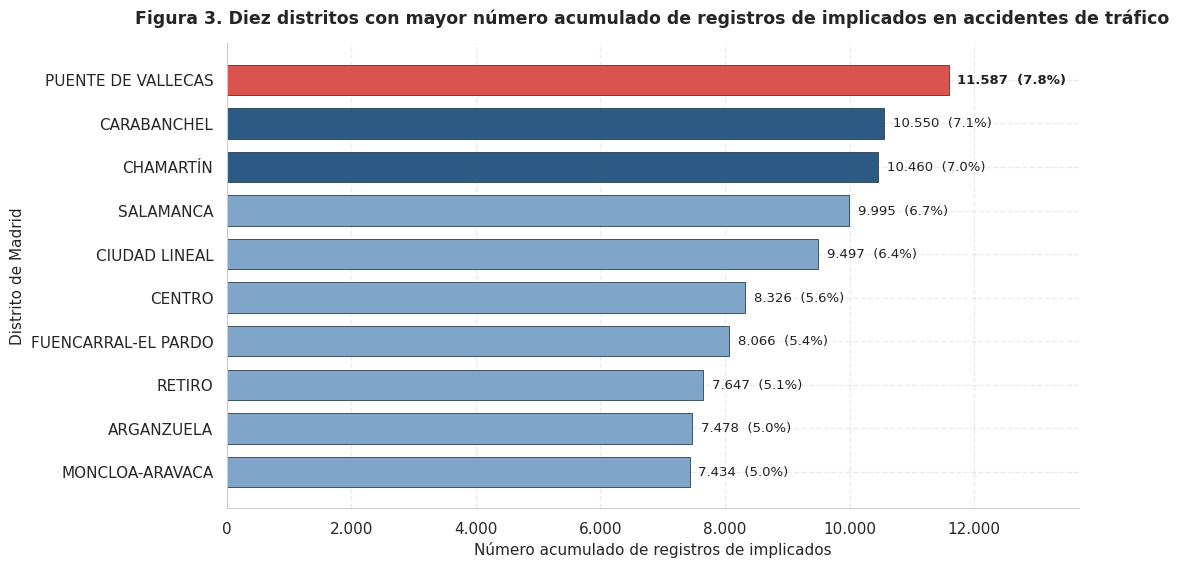


4.2.3.1 TIPOLOGÍA DEL PARQUE MÓVIL IMPLICADO - TOP 7 (FIGURA 4)
          tipo_vehiculo  implicaciones  porcentaje
                Turismo         102726     68.8341
              Furgoneta           9728      6.5185
Motocicleta hasta 125cc           9718      6.5118
    Motocicleta > 125cc           5538      3.7109
                Autobús           4545      3.0455
          Camión rígido           3541      2.3727
              Bicicleta           2424      1.6243


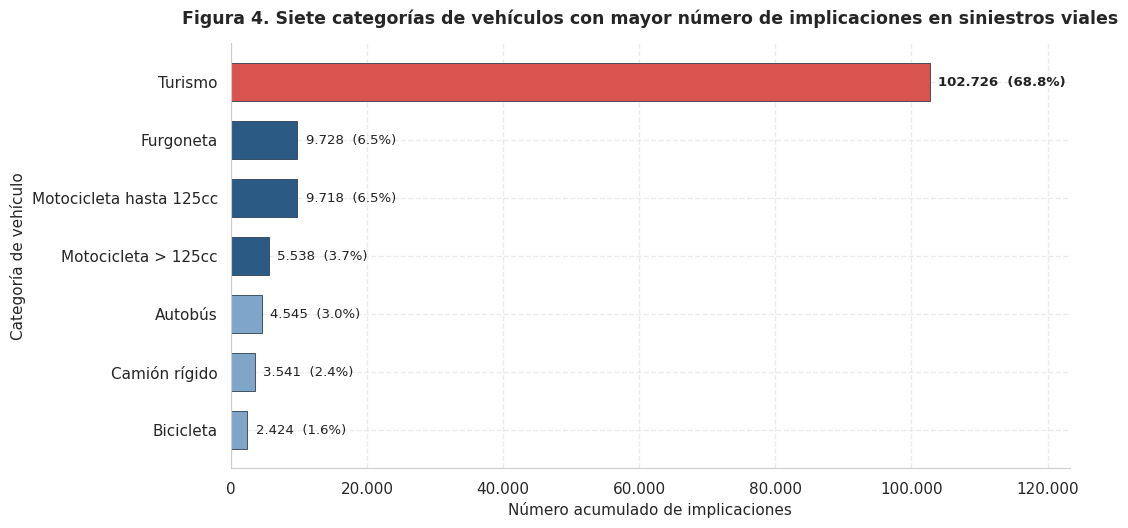


4.2.4 EVALUACIÓN DE CALIDAD, COMPLETITUD Y CONSISTENCIA

1) Resumen de completitud y rol de las 19 variables:
            variable   dtype  ausentes  pct_ausentes  valores_unicos                  rol_modelado
      positiva_droga float64    148685       99.6300               1 Excluida (Leakage / Atestado)
           lesividad  object     67506       45.2340               9 Excluida (Leakage / Atestado)
       cod_lesividad float64     67506       45.2340               9 Excluida (Leakage / Atestado)
estado_meteorológico  object     17669       11.8400               7 Excluida (Leakage / Atestado)
       tipo_vehiculo  object      1201        0.8050              37      Disponible / Descriptiva
    positiva_alcohol  object       553        0.3710               2 Excluida (Leakage / Atestado)
    coordenada_x_utm float64        30        0.0200           15360      Disponible / Descriptiva
    coordenada_y_utm float64        30        0.0200           16295      Disponible / Descriptiv

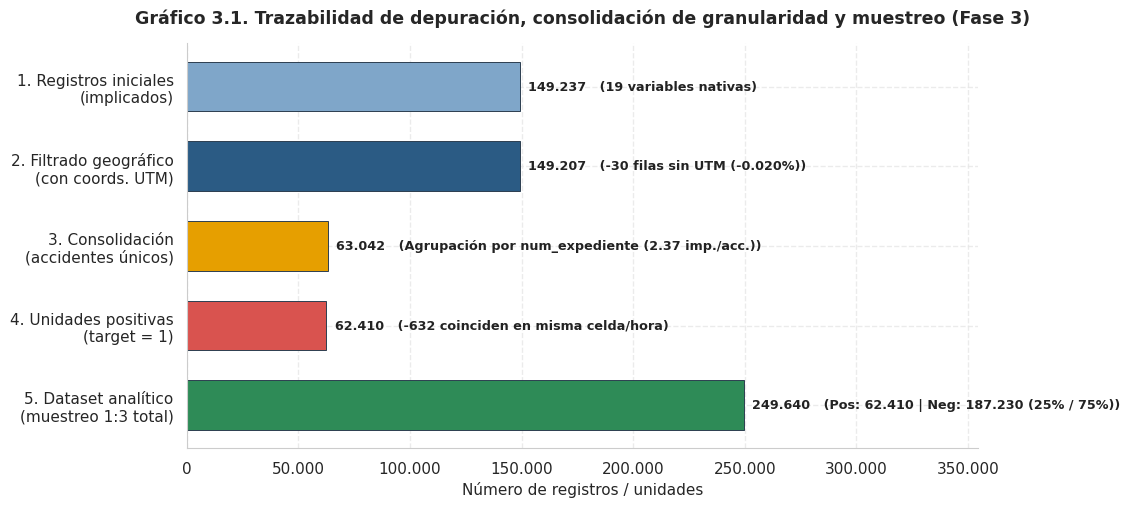

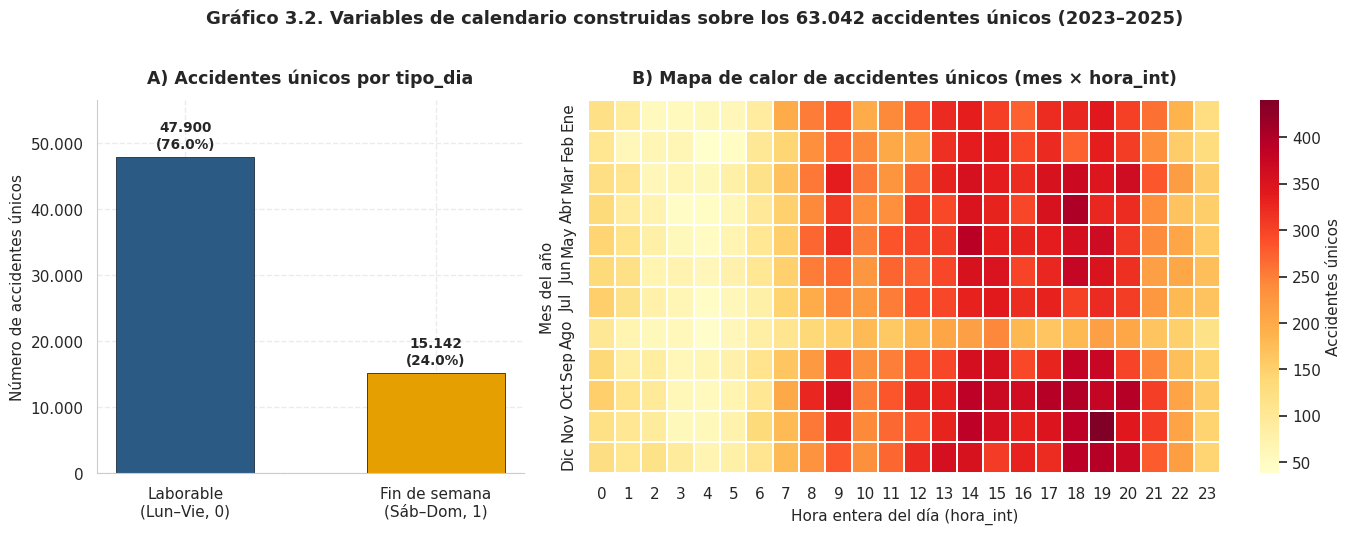

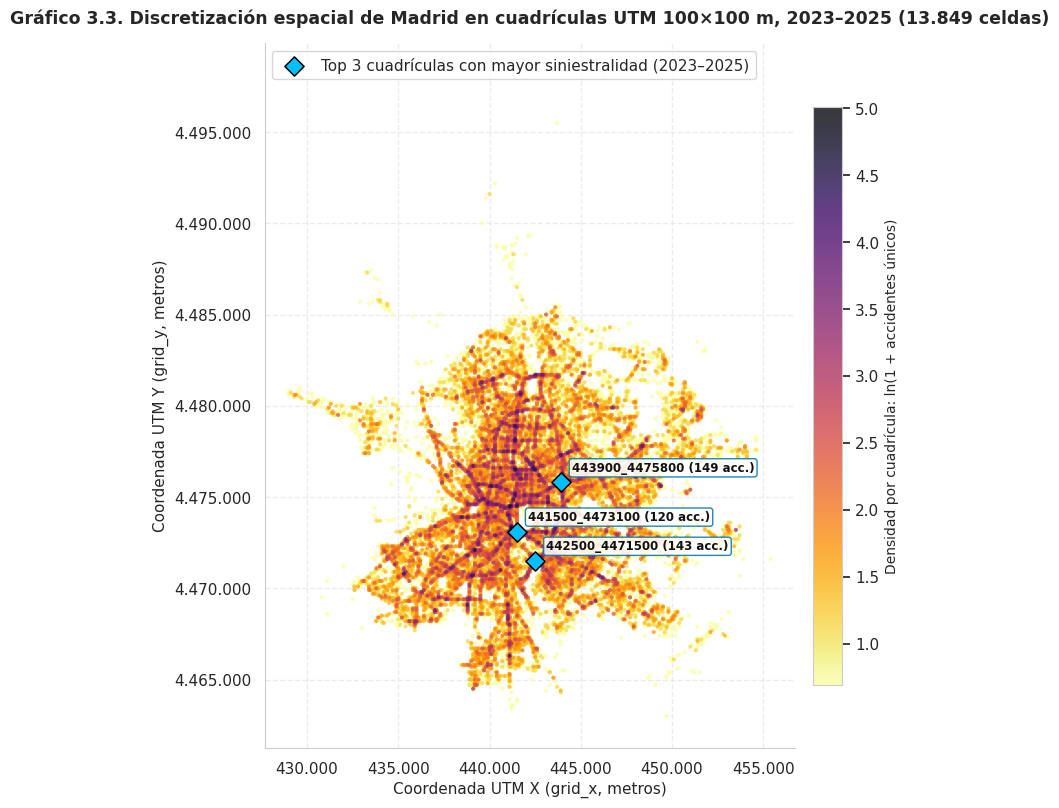

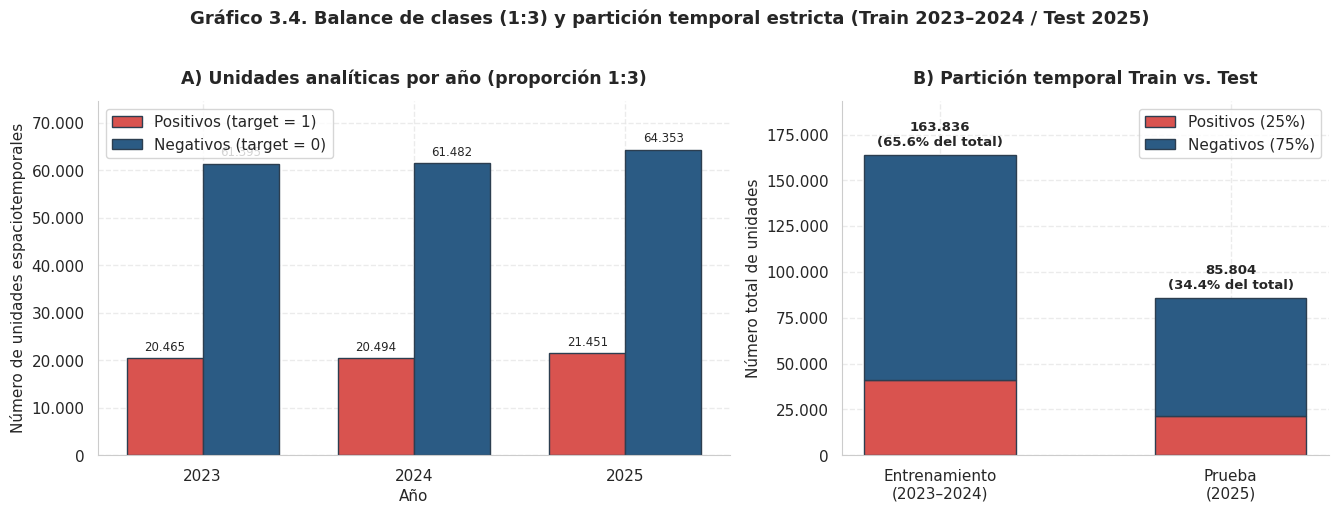


VALIDACIÓN DE INTEGRIDAD DEL CONJUNTO ANALÍTICO — FASE 3
  [OK]      Control geográfico UTM aplicado                  | Válidos: 149.207 | Excluidos: 30
  [OK]      Variables de Data Leakage excluidas (5)          | Excluidas: ['cod_lesividad', 'lesividad', 'positiva_alcohol', 'positiva_droga', 'estado_meteorológico']
  [OK]      Consolidación por expediente completada          | Accidentes únicos: 63.042
  [OK]      Exactamente 5 predictores finales                | Cols: ['grid_x', 'grid_y', 'mes', 'tipo_dia', 'hora_int']
  [OK]      Proporción exacta 1:3 en Train (2023–2024)       | Ratio: 3.0000
  [OK]      Proporción exacta 1:3 en Test (2025)             | Ratio: 3.0000
  [OK]      Cero solapamiento entre Positivos y Negativos    | Solapamientos: 0
  [OK]      Partición temporal estricta sin fuga             | Train: [2023, 2024] | Test: [2025]

Objetos listos en memoria para la Fase 4 (Modelado):
  -> df_clean, df_accidentes, df_unidades, df_train, df_test
  -> X_train, y_train,

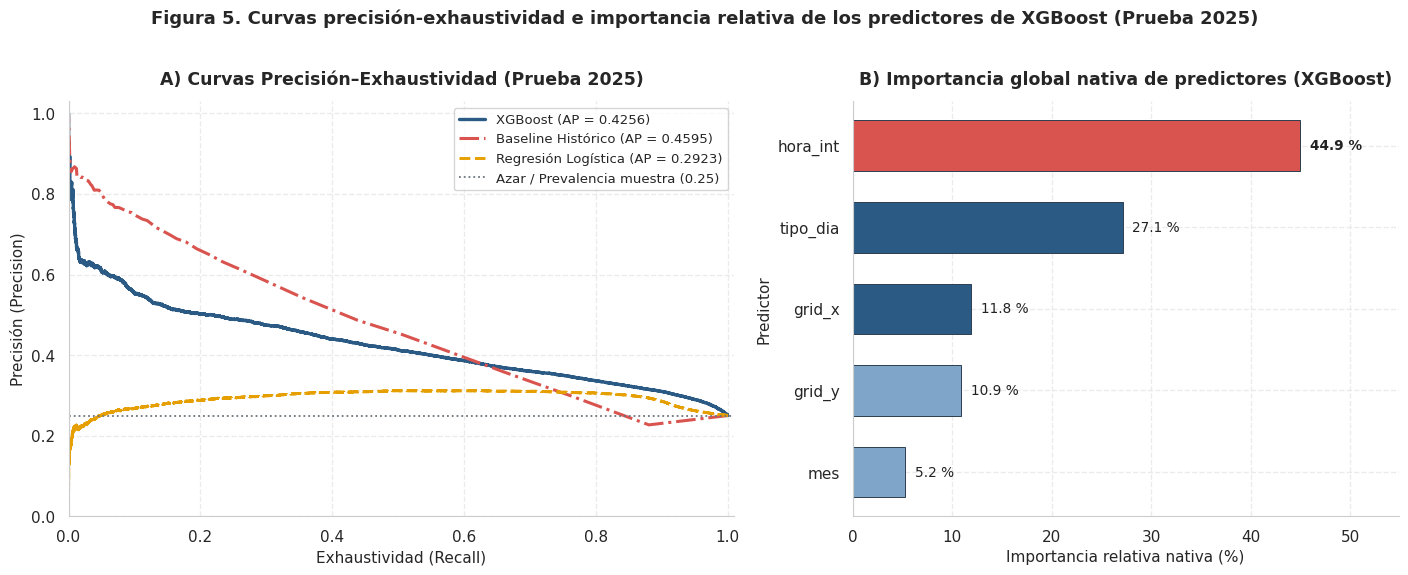

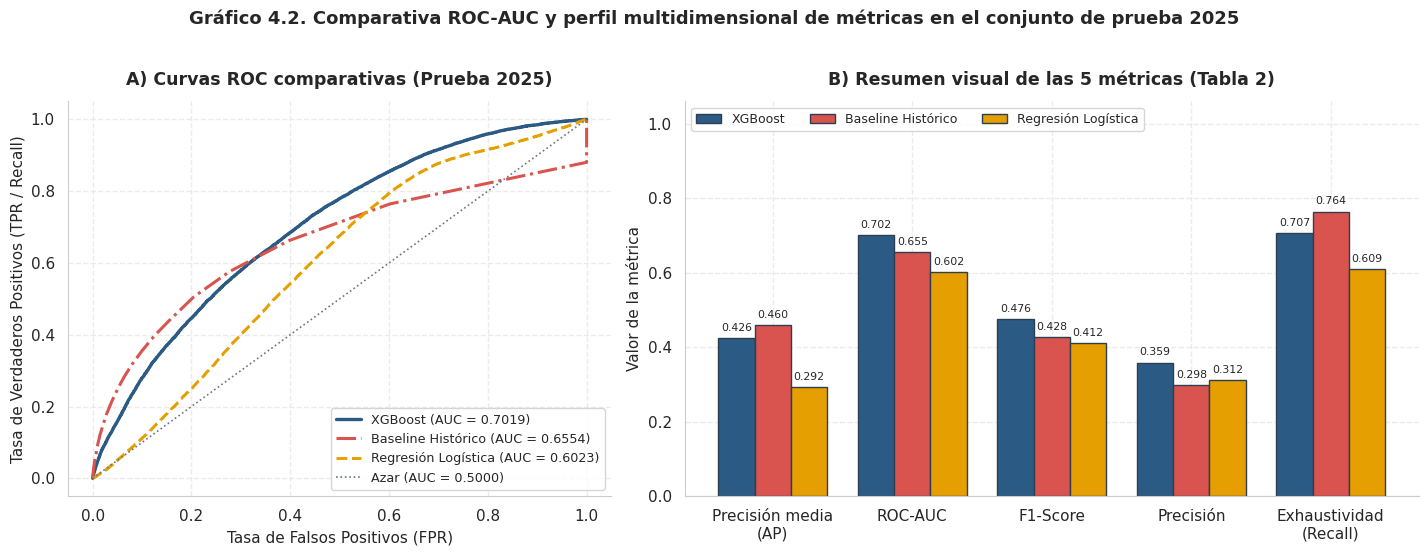

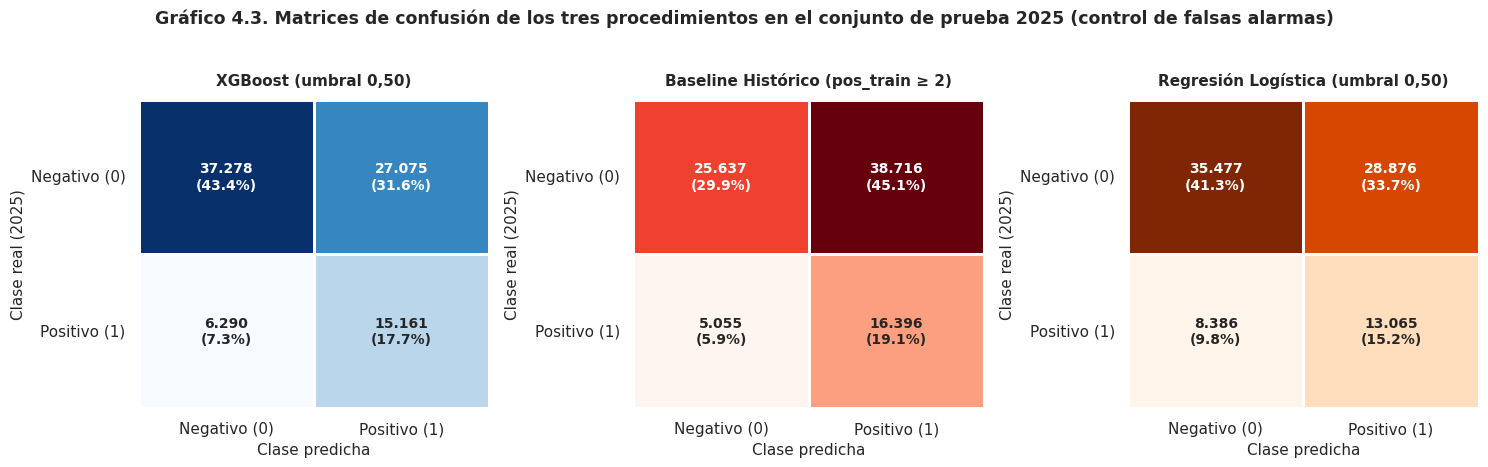


FASE 4.1 (CRISP-DM): MODELO HÍBRIDO (XGBOOST + RECURRENCIA HISTÓRICA)
Nuevos predictores del Modelo Híbrido (6): ['grid_x', 'grid_y', 'mes', 'tipo_dia', 'hora_int', 'pos_train_hist']
Fitting 3 folds for each of 8 candidates, totalling 24 fits

GridSearchCV (Modelo Híbrido) finalizado en 24.90 s.
Mejores hiperparámetros Híbrido (CV AP)        : {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}
Mejor Average Precision medio en CV (Híbrido)  : 0.5792

=== RESULTADOS COMPARATIVOS OFICIALES EN TEST 2025 (INCLUYENDO MODELO HÍBRIDO) ===


,Procedimiento,Precisión media (AP),ROC-AUC,F1-Score,Precisión,Exhaustividad (Recall)
0,XGBoost (Sin histórico),0.4256,0.7019,0.4761,0.3590,0.7068
1,Baseline Histórico,0.4595,0.6554,0.4283,0.2975,0.7643
2,Regresión Logística,0.2923,0.6023,0.4122,0.3115,0.6091
3,XGBoost HÍBRIDO (Con histórico),0.5259,0.7345,0.5060,0.4287,0.6175



Ganancia en Average Precision (AP) del Modelo Híbrido:
  - Frente a XGBoost (Sin histórico) : +0.1004 (0.4256 -> 0.5259)
  - Frente a Baseline Histórico      : +0.0664 (0.4595 -> 0.5259)
  - Frente a Regresión Logística     : +0.2336 (0.2923 -> 0.5259)

=== IMPORTANCIA DE VARIABLES DEL MODELO HÍBRIDO ===


,variable,importancia_pct
0,pos_train_hist,81.6372
1,hora_int,9.8918
2,tipo_dia,4.7807
3,mes,1.4696
4,grid_x,1.1181
5,grid_y,1.1027


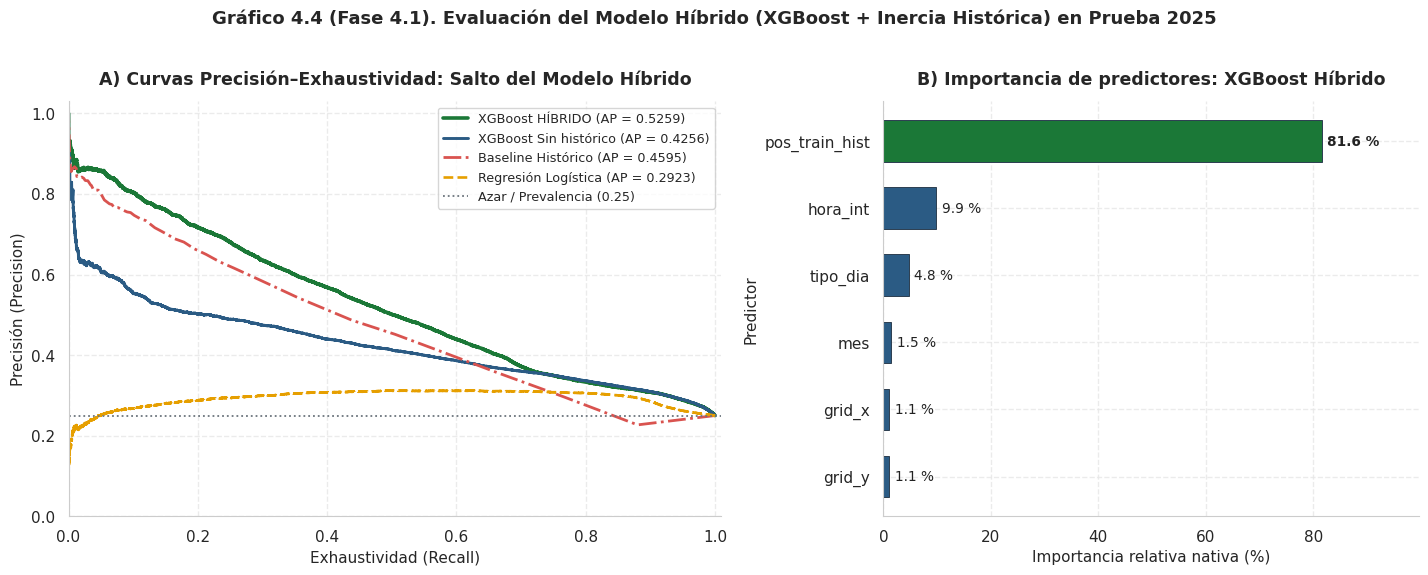


   VALIDACIÓN OUT-OF-FOLD TEMPORAL ESTRICTA PARA EL MODELO HÍBRIDO

Fitting 3 folds for each of 8 candidates, totalling 24 fits

GridSearchCV (Modelo Híbrido OOF) finalizado en 21.14 s.
Mejores hiperparámetros Híbrido OOF (CV AP)    : {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}
Mejor Average Precision medio en CV (OOF)      : 0.5248

=== TABLA COMPARATIVA DE RESULTADOS FINALES DE ROBUSTEZ ===


,Procedimiento,AP (Test 2025)
0,XGBoost (5 variables),0.4256
1,Baseline Histórico,0.4595
2,XGBoost Híbrido Estándar,0.5259
3,XGBoost Híbrido Out-of-Fold (Test Definitivo),0.5362



=== IMPORTANCIA DE VARIABLES DEL MODELO HÍBRIDO OUT-OF-FOLD ===


,variable,importancia_pct
0,pos_train_hist,62.3417
1,hora_int,18.8188
2,tipo_dia,9.8201
3,grid_x,3.3817
4,grid_y,3.1413
5,mes,2.4965



Análisis del Veredicto:
  -> SÍ SE SOSTIENE LA CONCLUSIÓN: El AP del Híbrido OOF (0.5362) sigue superando al Baseline (0.4595).
     Esto certifica matemáticamente que la superioridad del modelo no se debía a look-ahead leakage o sesgos
     de sobreajuste espacial durante el entrenamiento del algoritmo.

RESUMEN DE HALLAZGOS DE LA EVALUACIÓN COMPARATIVA — FASE 4 Y FASE 4.1 (TEST 2025)
  - Mejor modelo en Average Precision (AP) : XGBoost HÍBRIDO (Con histórico) (0.5259)
  - AP Modelo Híbrido Out-of-Fold (OOF)    : 0.5362 (Baseline: 0.4595)
  - Mejor modelo en ROC-AUC                : XGBoost HÍBRIDO (Con histórico) (0.7345)
  - Mejor modelo en F1-Score               : XGBoost HÍBRIDO (Con histórico) (0.5060)
  - Mejor modelo en Precisión              : XGBoost HÍBRIDO (Con histórico) (0.4287)
  - Mejor modelo en Exhaustividad (Recall) : Baseline Histórico (0.7643)
  - Predictor dominante XGBoost Base       : hora_int (44.95 %) | Orden: ['hora_int', 'tipo_dia', 'grid_x', 'grid_y', 'mes

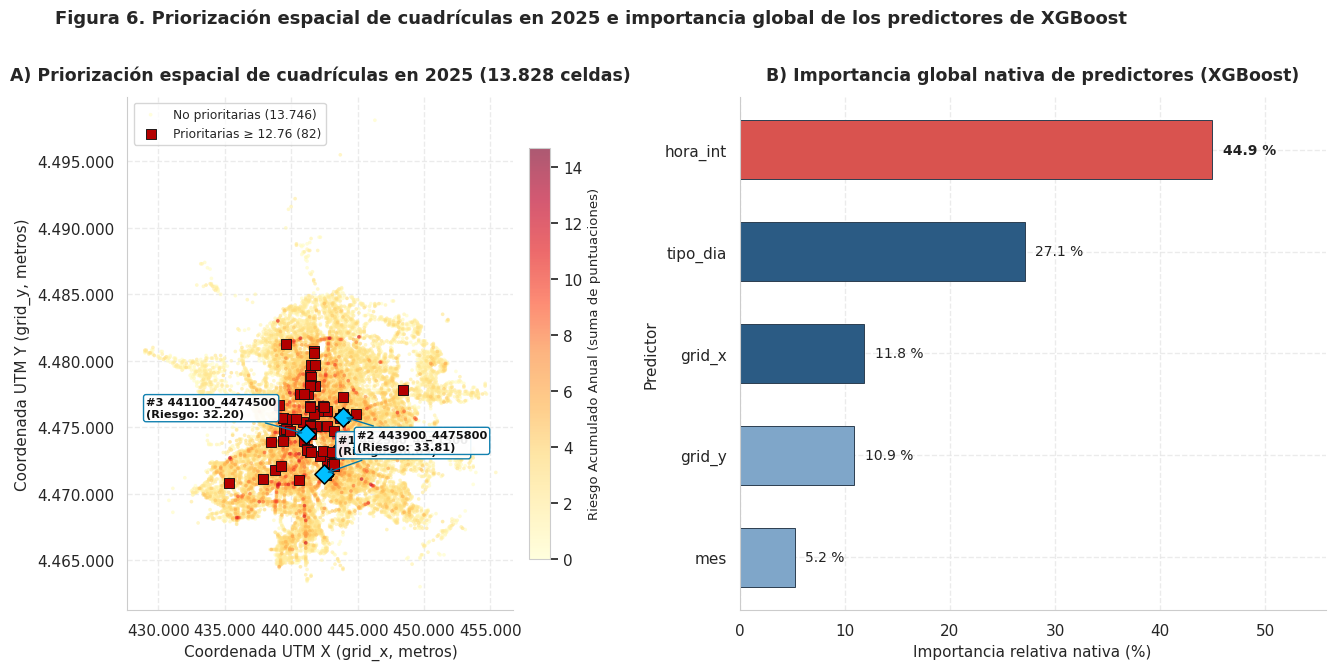

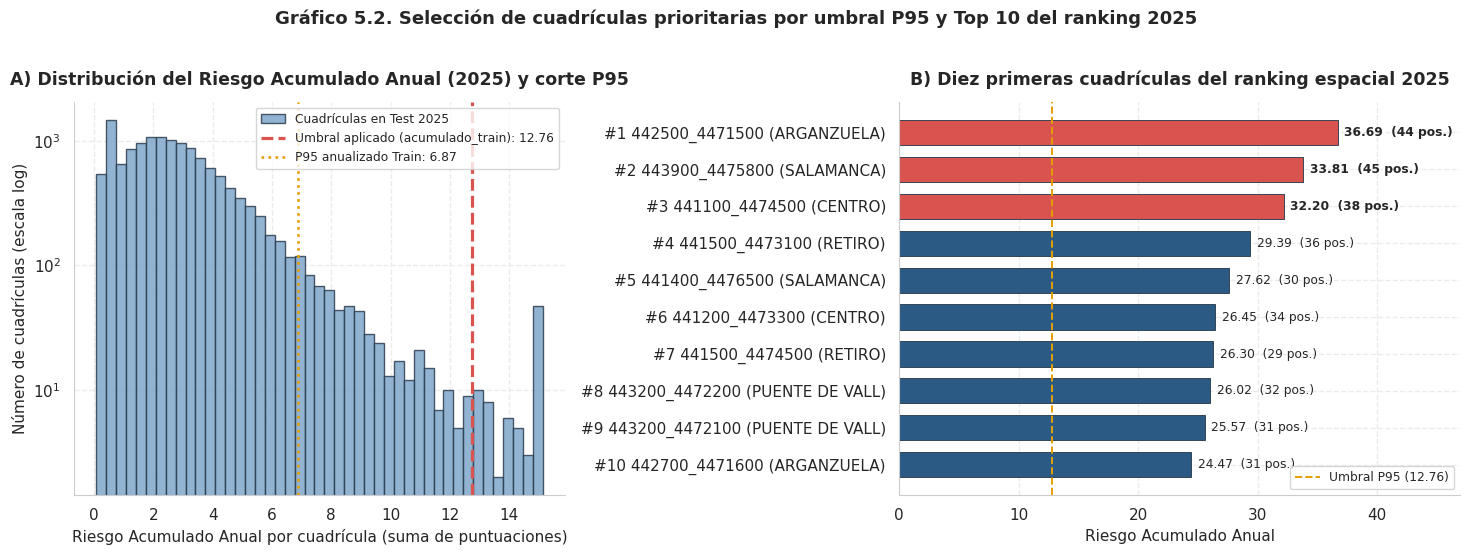

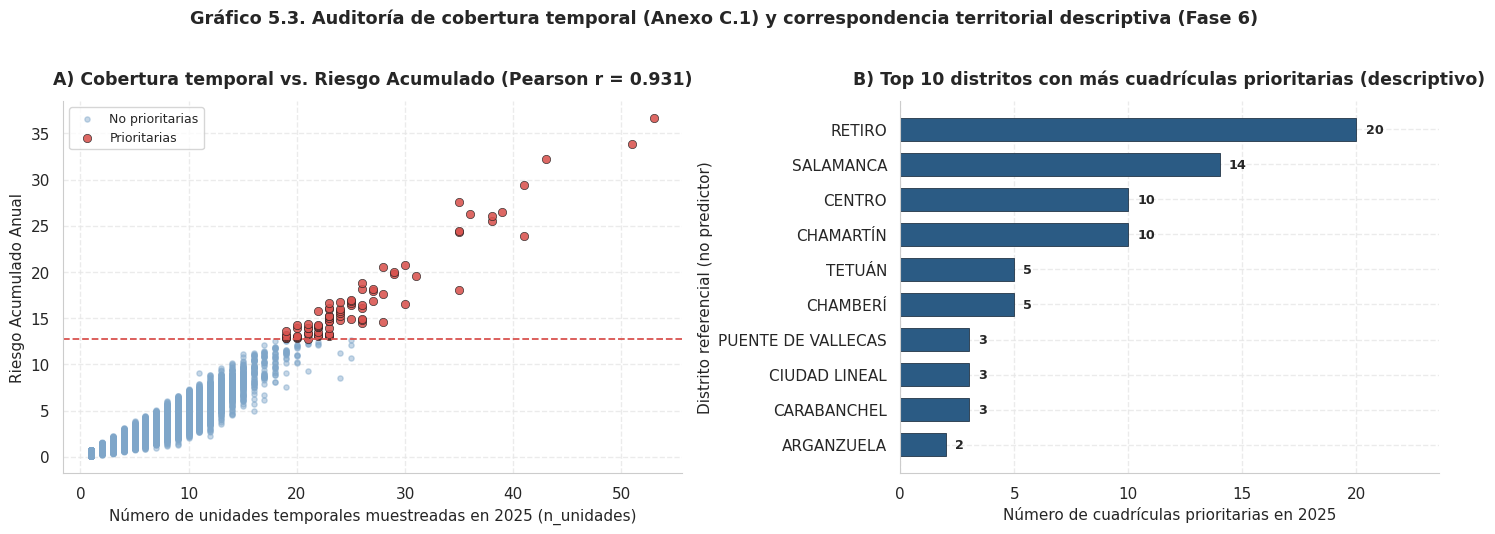


VALIDACIÓN DE TRAZABILIDAD — FASE 5 (AGREGACIÓN ESPACIAL Y XAI)
  [OK]      Ranking completo de cuadrículas 2025 generado    | 13.828 celdas evaluadas
  [OK]      Umbral P95 calculado estrictamente en Train      | 12.76 (regla: acumulado_train)
  [OK]      Cuadrículas prioritarias identificadas en 2025   | 82 celdas (0.59%)
  [OK]      Cobertura temporal por cuadrícula auditada       | Pearson r = 0.9310 | Spearman rho = 0.9229
  [OK]      Importancia global nativa (XAI) extraída         | Líder: hora_int (44.95 %) | Orden: ['hora_int', 'tipo_dia', 'grid_x', 'grid_y', 'mes']

KPIs listos en memoria y disco para la Fase 6 (Propuesta de Cuadro de Mando BI):
  - cuadriculas_evaluadas_2025          : 13828
  - cuadriculas_prioritarias_2025       : 82
  - umbral_p95_aplicado                 : 12.7584
  - regla_umbral                        : acumulado_train
  - puntuacion_agregada_promedio_2025   : 2.9055
  - puntuacion_agregada_maxima_2025     : 36.6886
  - exhaustividad_xgb_2025         

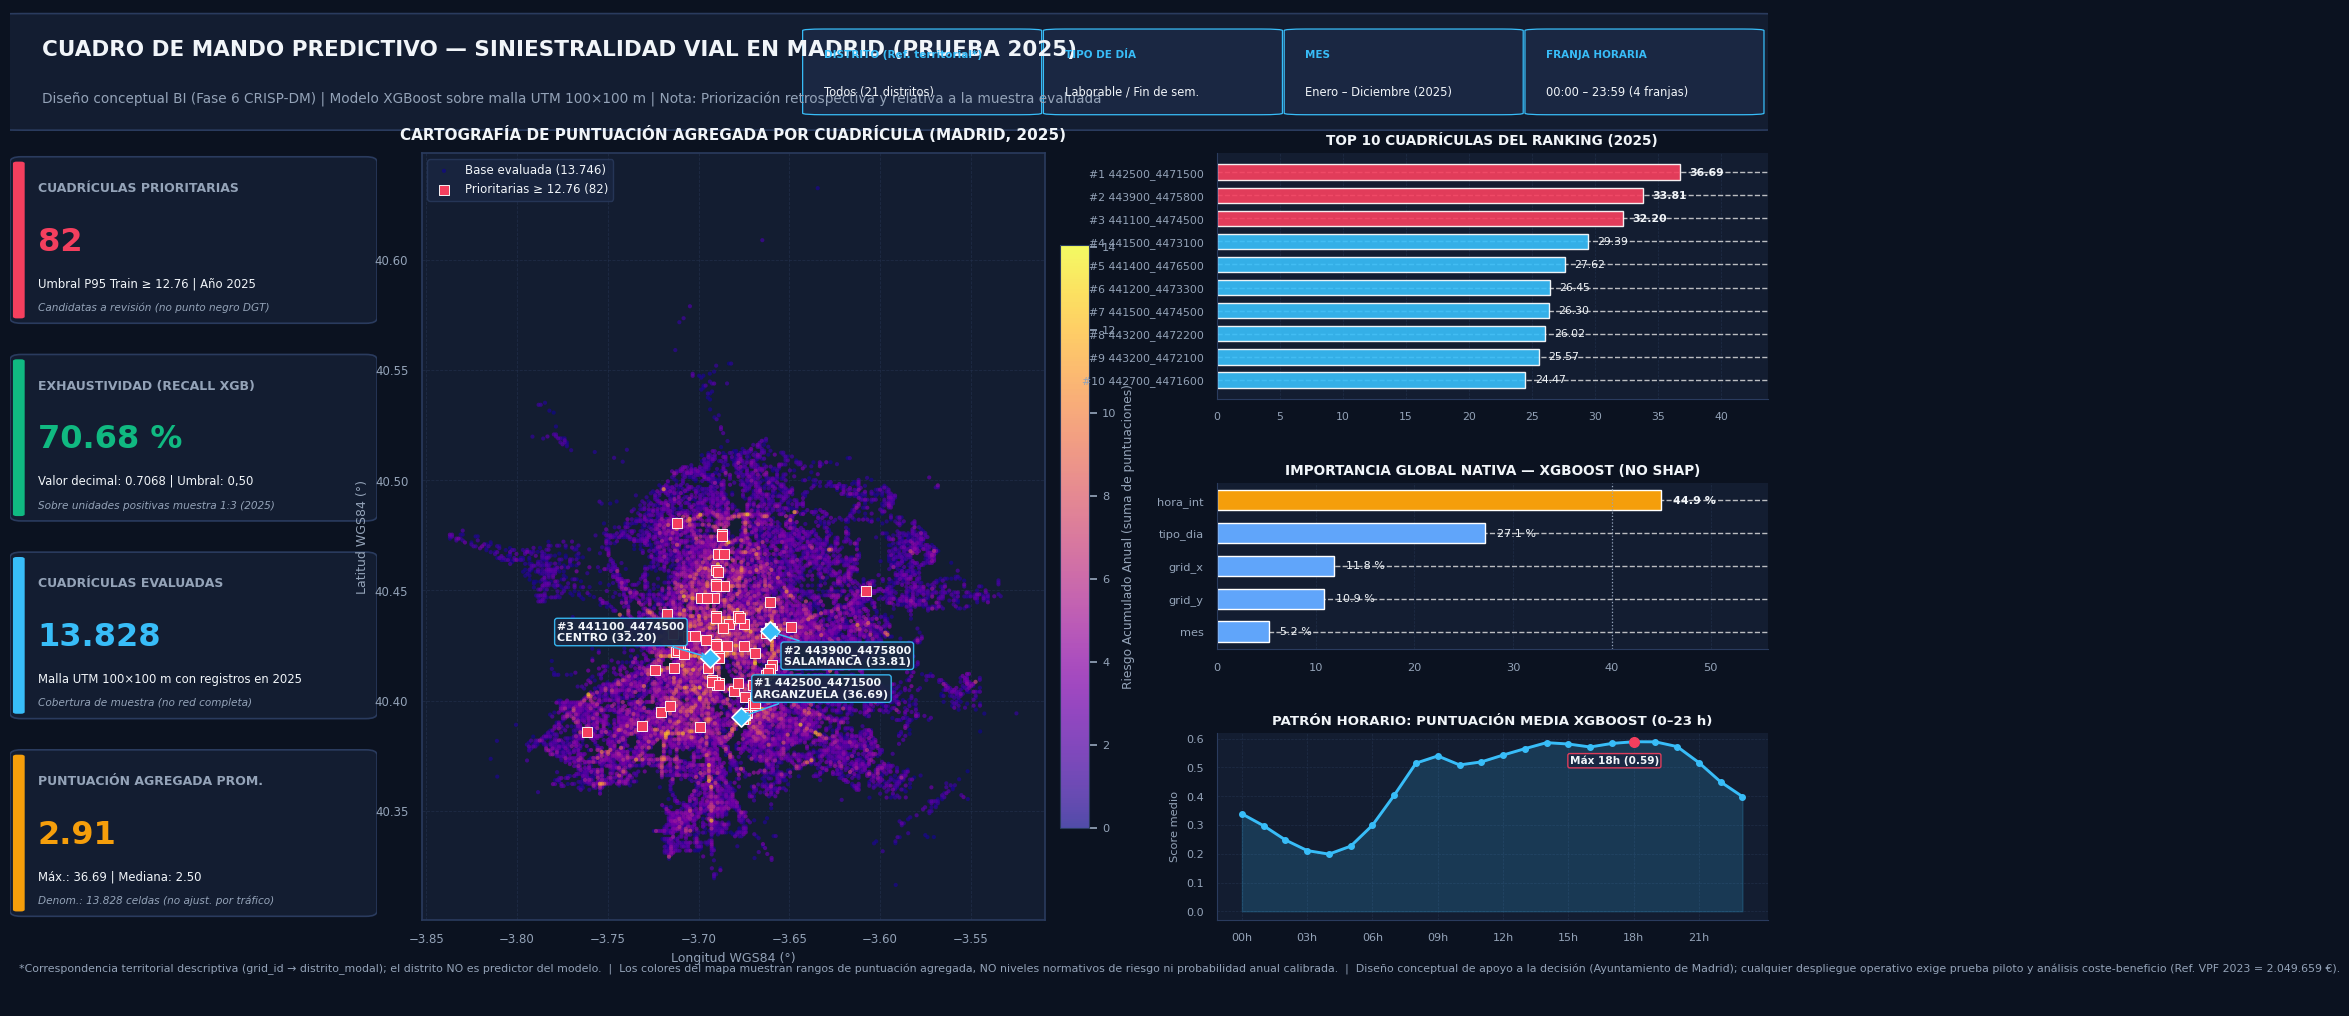

Recreación en modo oscuro guardada (300 dpi) en: /content/figuras_fase6/figura_cuadro_mando_predictivo_modo_oscuro.png

3) GENERANDO MAPA INTERACTIVO HTML Y EXPLORADOR DE FILTROS CONTEXTUALES
----------------------------------------------------------------------------------------
Mapa interactivo HTML guardado en: /content/export_bi_fase6/mapa_interactivo_madrid_2025.html



Explorador interactivo de los 4 filtros contextuales (Sección 4.6.1):


interactive(children=(Dropdown(description='Distrito:', options=('Todos', 'ARGANZUELA', 'BARAJAS', 'CARABANCHE…


4) EMPAQUETADO FINAL DE ENTREGABLES (POWER BI + FIGURAS + ANEXO C.1)
Paquete ZIP consolidado creado : /content/TFM_Madrid_Entregables_BI_Fase6.zip
Total archivos empaquetados    : 37 archivos (13.47 MB)
Para descargarlo directamente desde Google Colab, ejecuta:
  from google.colab import files
  files.download('/content/TFM_Madrid_Entregables_BI_Fase6.zip')

VALIDACIÓN FINAL DE ENTREGABLES — FASE 6 (DESPLIEGUE BI Y ANEXO C.1)
  [OK]      Modelo estrella exportado para Power BI (6 CSVs)       | Carpeta: /content/export_bi_fase6
  [OK]      Proyección UTM 30N -> WGS84 (Lat/Lon) verificada       | Coordenadas válidas en Madrid
  [OK]      Guía de medidas DAX para Power BI generada             | guia_medidas_dax_powerbi.txt
  [OK]      Recreación del Cuadro de Mando Modo Oscuro (300 dpi)   | 4 secciones de la Sección 4.6.1
  [OK]      Paquete ZIP integral de reproducibilidad (Anexo C)     | 37 archivos (13.47 MB)
FASE 7 (CRISP-DM): COMPARATIVA GLOBAL DE ROBUSTEZ DEL MODELO HÍBRIDO (TEST 2

,Ranking_AP,Procedimiento,Categoría,Predictores,Precisión media (AP),ROC-AUC,F1-Score,Precisión,Exhaustividad (Recall)
0,1,XGBoost Híbrido Out-of-Fold (OOF),Fase 4.1 (Inercia Espacial OOF),6 (5 base + pos_train_hist OOF),0.5362,0.7621,0.5258,0.4002,0.7660
1,2,XGBoost Híbrido Estándar,Fase 4.1 (Inercia Espacial),6 (5 base + pos_train_hist),0.5259,0.7345,0.5060,0.4287,0.6175
2,3,Baseline Histórico,Fase 4 (Referencia Espacial),1 (recurrencia histórica grid_id),0.4595,0.6554,0.4283,0.2975,0.7643
3,4,XGBoost Base (5 variables),Fase 4 (Modelo Base),"5 (grid_x, grid_y, mes, tipo_dia, hora_int)",0.4256,0.7019,0.4761,0.3590,0.7068
4,5,Regresión Logística,Fase 4 (Referencia Paramétrica),5 (estandarizadas),0.2923,0.6023,0.4122,0.3115,0.6091



2) DESGLOSE DE MATRICES DE CONFUSIÓN EN TEST 2025 (5 PROCEDIMIENTOS):


,Procedimiento,TN (Verdaderos Neg.),FP (Falsas Alarmas),FN (Siniestros Omitidos),TP (Aciertos Positivos),Alertas Positivas Totales,Tasa Falsos Positivos (%)
0,XGBoost Híbrido Out-of-Fold (OOF),39729,24624,5019,16432,41056,38.2600
1,XGBoost Híbrido Estándar,46699,17654,8206,13245,30899,27.4300
2,Baseline Histórico,25637,38716,5055,16396,55112,60.1600
3,XGBoost Base (5 variables),37278,27075,6290,15161,42236,42.0700
4,Regresión Logística,35477,28876,8386,13065,41941,44.8700



3) TABLA DE DIFERENCIALES DE ROBUSTEZ (GANANCIA NETA EN TEST 2025):


,Contraste Metodológico,Δ Precisión media (AP),Δ ROC-AUC,Δ F1-Score,Δ Precisión,Δ Exhaustividad (Recall)
0,Híbrido OOF vs. XGBoost Base (5 vars),0.1107,0.0602,0.0497,0.0413,0.0593
1,Híbrido OOF vs. Baseline Histórico,0.0767,0.1068,0.0975,0.1027,0.0017
2,Híbrido OOF vs. Regresión Logística,0.2439,0.1599,0.1136,0.0887,0.1570
3,Híbrido Estándar vs. XGBoost Base (5 vars),0.1004,0.0326,0.0299,0.0697,-0.0893
4,Híbrido Estándar vs. Baseline Histórico,0.0664,0.0792,0.0777,0.1312,-0.1469
5,Híbrido OOF vs. Híbrido Estándar (Estabilidad),0.0103,0.0276,0.0197,-0.0284,0.1486



SÍNTESIS EJECUTIVA DE ROBUSTEZ METODOLÓGICA — FASE 7 (TEST 2025)
  - AP XGBoost Híbrido Out-of-Fold (OOF) : 0.5362
  - AP XGBoost Híbrido Estándar          : 0.5259
  - Tasa de retención OOF vs. Estándar   : 101.95 % (ausencia de sobreajuste espacial)
  - Ganancia AP OOF vs. Baseline Hist.   : +0.0767
  - Ganancia AP OOF vs. XGBoost Base     : +0.1107
  - Ganancia AP OOF vs. Reg. Logística   : +0.2439
  - Dominancia simultánea en AP (Test 25): CONFIRMADA (supera a los 3 modelos base)


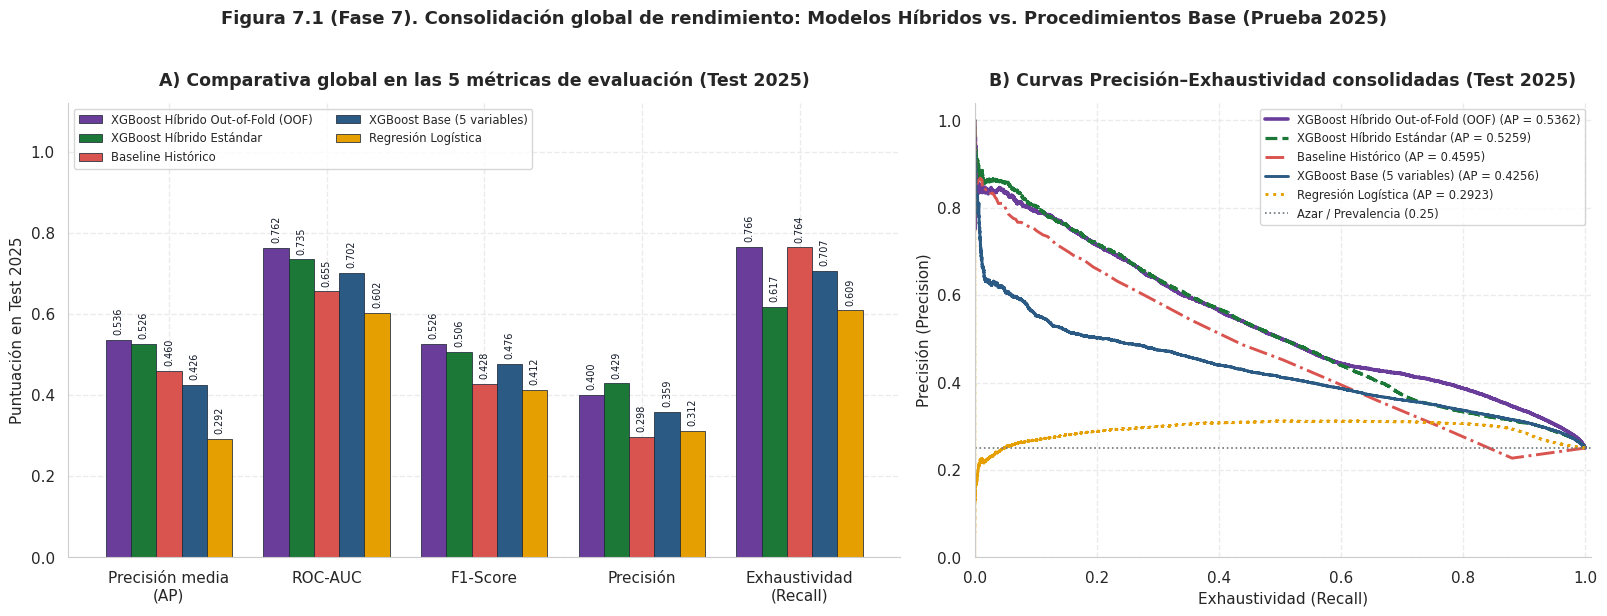

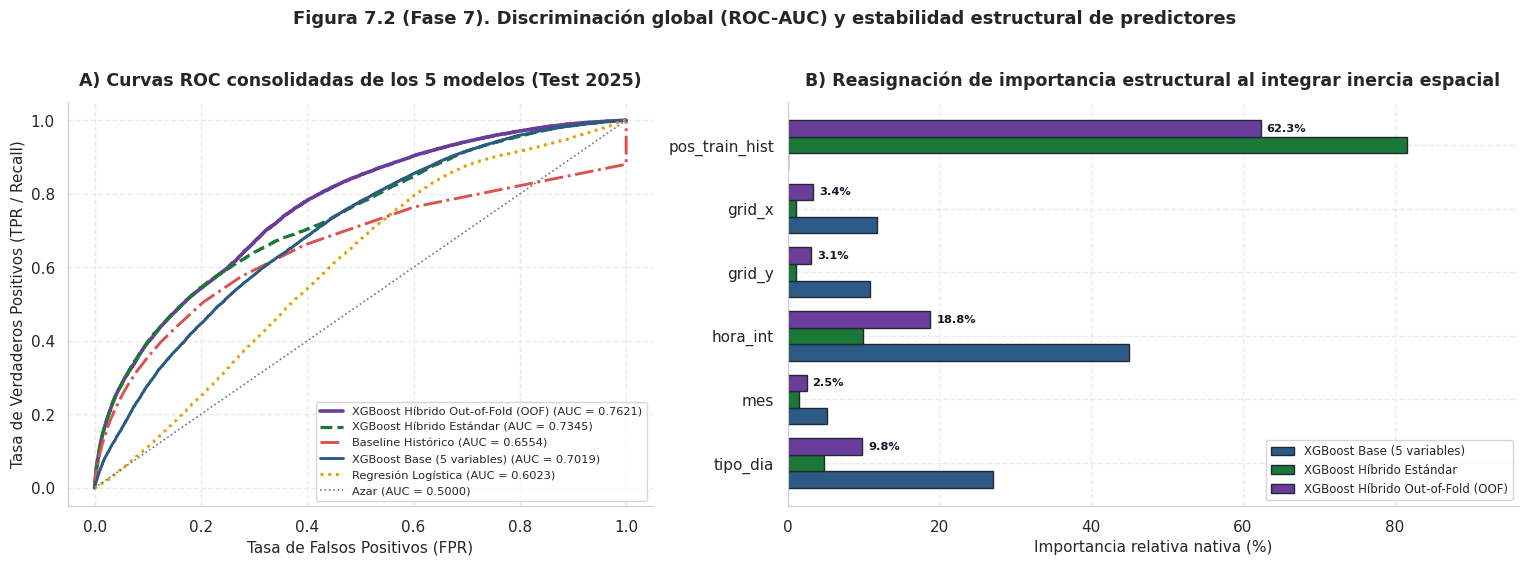


Figuras de Fase 7 guardadas (300 dpi) en : /content/figuras_fase7
Tablas CSV de Fase 7 guardadas en      : /content/resultados_fase7


In [1]:
# ==============================================================================
# --- CELDA DE CÓDIGO NÚMERO 1: FASE 0 (CONFIGURACIÓN Y CARGA DE DATOS) ---
# ==============================================================================
# ==============================================================================
# TFM: Desarrollo y evaluación comparativa de un modelo XGBoost para la
#      clasificación espaciotemporal de accidentes en Madrid
# FASE 0: Configuración del entorno, carga de librerías y consolidación de CSVs
# Entorno objetivo: Google Colab
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. IMPORTACIÓN DE LIBRERÍAS DEL PROYECTO (TODAS LAS FASES CRISP-DM)
# ------------------------------------------------------------------------------
import os
import sys
import warnings
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías de Machine Learning y métricas (para fases 4 y 5)
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
)

# Verificación e importación de XGBoost (preinstalado en Google Colab)
try:
    import xgboost as xgb
    from xgboost import XGBClassifier
except ImportError:
    print("XGBoost no está instalado. Ejecuta en una celda: !pip install xgboost")
    xgb = None
    XGBClassifier = None

# Configuración general de visualización y reproducibilidad
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")


def imprimir_versiones_entorno() -> None:
    """
    Registra las versiones de Python y bibliotecas principales para cumplir
    con los requisitos de reproducibilidad del Anexo C.1 del TFM.
    """
    print("=" * 75)
    print("ENTORNO TECNOLÓGICO Y VERSIONES (ANEXO C - REPRODUCIBILIDAD)")
    print("=" * 75)
    print(f"Sistema operativo : {platform.system()} {platform.release()}")
    print(f"Python            : {sys.version.split()[0]}")
    print(f"pandas            : {pd.__version__}")
    print(f"numpy             : {np.__version__}")
    print(f"scikit-learn      : {sklearn.__version__}")
    print(f"xgboost           : {xgb.__version__ if xgb is not None else 'No instalado'}")
    print(f"seaborn           : {sns.__version__}")
    print(f"Semilla global    : {RANDOM_STATE}")
    print("=" * 75)


# ------------------------------------------------------------------------------
# 2. CONFIGURACIÓN DE RUTAS Y CARGA ROBUSTA DE LOS CSV DESDE GITHUB
# ------------------------------------------------------------------------------
# Enlaces directos (Raw) a los ficheros oficiales de siniestralidad de Madrid (2023–2025)
URLS_GITHUB = [
    "https://raw.githubusercontent.com/fspiritu/Ciencia-de-datos/refs/heads/main/300228-1-accidentes-trafico-detalle-csv.csv",
    "https://raw.githubusercontent.com/fspiritu/Ciencia-de-datos/refs/heads/main/300228-2-accidentes-trafico-detalle-csv.csv",
    "https://raw.githubusercontent.com/fspiritu/Ciencia-de-datos/refs/heads/main/300228-3-accidentes-trafico-detalle-csv.csv"
]


def leer_csv_madrid(ruta_archivo: str) -> pd.DataFrame:
    """
    Lee un archivo CSV de siniestralidad manejando posibles diferencias de
    codificación (UTF-8 / Latin-1) y separador (';' / ',').
    """
    codificaciones = ["utf-8-sig", "utf-8", "latin-1", "cp1252"]
    separadores = [";", ","]

    ultimo_error = None
    for enc in codificaciones:
        for sep in separadores:
            try:
                df_temp = pd.read_csv(
                    ruta_archivo,
                    sep=sep,
                    encoding=enc,
                    low_memory=False,
                )
                if df_temp.shape[1] > 1:
                    df_temp.columns = [col.strip() for col in df_temp.columns]
                    return df_temp
            except Exception as err:
                ultimo_error = err

    raise RuntimeError(
        f"No se pudo leer el archivo '{ruta_archivo}'. Último error: {ultimo_error}"
    )


def cargar_y_consolidar_csvs(urls: list) -> pd.DataFrame:
    """
    Carga individualmente los CSV desde una lista de URLs mostrando un resumen
    por fichero y los concatena en un único DataFrame.
    """
    if not urls:
        raise ValueError("La lista de URLs de GitHub está vacía. Por favor, añade los enlaces.")

    print(f"\nArchivos CSV a cargar ({len(urls)}):")
    lista_dfs = []

    for ruta in urls:
        nombre = ruta.split('/')[-1]
        print(f"Descargando: {nombre}...")
        df_i = leer_csv_madrid(ruta)

        rango_fechas = "No disponible"
        if "fecha" in df_i.columns:
            fechas_tmp = pd.to_datetime(
                df_i["fecha"], dayfirst=True, errors="coerce"
            )
            if fechas_tmp.notna().any():
                f_min = fechas_tmp.min().strftime("%Y-%m-%d")
                f_max = fechas_tmp.max().strftime("%Y-%m-%d")
                anios = sorted(fechas_tmp.dt.year.dropna().astype(int).unique().tolist())
                rango_fechas = f"{f_min} a {f_max} | Años: {anios}"

        print(
            f"  - {nombre:<46} | Filas: {df_i.shape[0]:>7,} | "
            f"Cols: {df_i.shape[1]:>2} | {rango_fechas}"
        )
        df_i["_archivo_origen"] = nombre
        lista_dfs.append(df_i)

    cols_base = list(lista_dfs[0].columns)
    for idx, df_i in enumerate(lista_dfs[1:], start=1):
        if list(df_i.columns) != cols_base:
            print(
                f"  [AVISO] El archivo #{idx + 1} presenta nombres u orden de columnas distinto."
            )

    df_consolidado = pd.concat(lista_dfs, ignore_index=True)
    return df_consolidado


# ------------------------------------------------------------------------------
# 3. EJECUCIÓN DE CARGA Y DIAGNÓSTICO INICIAL DEL CONJUNTO DE DATOS
# ------------------------------------------------------------------------------
imprimir_versiones_entorno()

try:
    df_raw = cargar_y_consolidar_csvs(URLS_GITHUB)

    # Columnas originales (excluyendo la columna auxiliar de trazabilidad)
    cols_originales = [c for c in df_raw.columns if c != "_archivo_origen"]

    print("\n" + "=" * 75)
    print("DIAGNÓSTICO INICIAL DE CARGA Y CONSOLIDACIÓN DE DATOS")
    print("=" * 75)
    print(f"Total registros cargados : {len(df_raw):>9,}")
    print(f"Total variables nativas  : {len(cols_originales):>9}")

    # Diagnóstico por año (sin modificar df_raw permanentemente)
    fechas_eval = pd.to_datetime(df_raw["fecha"], dayfirst=True, errors="coerce")
    anios_eval = fechas_eval.dt.year

    print("\nDesglose por año (registros de implicados vs. expedientes únicos):")
    resumen_anual = (
        df_raw.assign(_anio=anios_eval)
        .groupby("_anio", dropna=False)
        .agg(
            registros_implicados=("num_expediente", "size"),
            accidentes_unicos=("num_expediente", "nunique"),
        )
    )
    print(resumen_anual)

    # Diagnóstico preliminar de integridad geográfica (coordenadas UTM)
    if {"coordenada_x_utm", "coordenada_y_utm"}.issubset(df_raw.columns):
        x_num = pd.to_numeric(
            df_raw["coordenada_x_utm"].astype(str).str.replace(",", ".", regex=False).str.strip(),
            errors="coerce",
        )
        y_num = pd.to_numeric(
            df_raw["coordenada_y_utm"].astype(str).str.replace(",", ".", regex=False).str.strip(),
            errors="coerce",
        )
        sin_coords = (x_num.isna() | y_num.isna()).sum()
        con_coords = len(df_raw) - sin_coords
        exp_con_coords = df_raw.loc[~(x_num.isna() | y_num.isna()), "num_expediente"].nunique()

        print("\nChequeo preliminar de integridad geográfica (coordenadas UTM):")
        print(f"  - Filas sin coordenadas UTM : {sin_coords:>9,}")
        print(f"  - Filas con coordenadas UTM : {con_coords:>9,}")
        print(f"  - Accidentes únicos válidos : {exp_con_coords:>9,}")

    print("\nListado de las variables cargadas:")
    for i, col in enumerate(cols_originales, start=1):
        print(f"  {i:>2}. {col:<25} | dtype: {str(df_raw[col].dtype):<10} | nulos: {df_raw[col].isna().sum():>7,}")

    print("\nPrimeras 5 filas del conjunto consolidado:")
    display(df_raw[cols_originales].head(5)) if "display" in globals() else print(df_raw[cols_originales].head(5))

except Exception as e:
    print(f"\n[ERROR EN LA CARGA] {e}")


# ==============================================================================
# --- CELDA DE CÓDIGO NÚMERO 2: FASE 2 (COMPRENSIÓN DE DATOS Y EDA) ---
# ==============================================================================
# ==============================================================================
# TFM: Desarrollo y evaluación comparativa de un modelo XGBoost para la
#      clasificación espaciotemporal de accidentes en Madrid
# FASE 2 (CRISP-DM): Comprensión de los datos y Análisis Exploratorio (EDA)
# Análisis exploratorio de datos (EDA): dimensiones temporal, espacial, tipológica y calidad
# ==============================================================================

import os
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ------------------------------------------------------------------------------
# 0. VERIFICACIÓN PREVIA Y CONFIGURACIÓN ESTÉTICA DE LAS GRÁFICAS
# ------------------------------------------------------------------------------
if "df_raw" not in globals():
    raise NameError(
        "No se encontró 'df_raw' en memoria. Ejecuta primero la celda de Fase 0 "
        "para cargar y consolidar los archivos CSV."
    )

# Directorio opcional donde se guardarán las figuras en alta resolución (300 dpi)
FIG_DIR = "/content/figuras_fase2"
os.makedirs(FIG_DIR, exist_ok=True)

# Estilo visual limpio y uniforme acorde a un documento académico
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.8,
    "grid.color": "#E6E6E6",
    "grid.linestyle": "--",
    "grid.alpha": 0.8,
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

# Paleta corporativa sobria (azul marino / acero + acento coral/ámbar para picos)
COLOR_BASE = "#2B5B84"
COLOR_SUAVE = "#7FA6C9"
COLOR_ACENTO = "#D9534F"
COLOR_SECUNDARIO = "#E69F00"


def normalizar_texto_col(texto: str) -> str:
    """Elimina tildes y pasa a minúsculas para localizar columnas de forma robusta."""
    nfkd = unicodedata.normalize("NFKD", str(texto))
    return "".join(c for c in nfkd if not unicodedata.combining(c)).lower().strip()


def buscar_columna(df: pd.DataFrame, posibles_nombres: list) -> str:
    """
    Busca una columna en el DataFrame tolerando diferencias de acentos o mayúsculas
    entre descargas del portal de datos abiertos del Ayuntamiento de Madrid.
    """
    mapa = {normalizar_texto_col(col): col for col in df.columns}
    for candidato in posibles_nombres:
        clave = normalizar_texto_col(candidato)
        if clave in mapa:
            return mapa[clave]
    return None


def formatear_miles(valor: float) -> str:
    """Formatea enteros con separador de miles estilo español (punto)."""
    return f"{int(round(valor)):,}".replace(",", ".")


# Trabajamos sobre una copia para preservar intacto 'df_raw' para la Fase 3
df_eda = df_raw.copy()
cols_nativas = [c for c in df_eda.columns if c != "_archivo_origen"]

# Resolución segura de nombres de columnas clave
col_exp = buscar_columna(df_eda, ["num_expediente"])
col_fecha = buscar_columna(df_eda, ["fecha"])
col_hora = buscar_columna(df_eda, ["hora"])
col_loc = buscar_columna(df_eda, ["localizacion", "localización"])
col_dist = buscar_columna(df_eda, ["distrito"])
col_x = buscar_columna(df_eda, ["coordenada_x_utm"])
col_y = buscar_columna(df_eda, ["coordenada_y_utm"])
col_tipo_acc = buscar_columna(df_eda, ["tipo_accidente"])
col_tipo_veh = buscar_columna(df_eda, ["tipo_vehiculo", "tipo_vehículo"])
col_edad = buscar_columna(df_eda, ["rango_edad"])
col_cod_les = buscar_columna(df_eda, ["cod_lesividad"])
col_les = buscar_columna(df_eda, ["lesividad"])
col_alc = buscar_columna(df_eda, ["positiva_alcohol"])
col_drog = buscar_columna(df_eda, ["positiva_droga"])
col_meteo = buscar_columna(df_eda, ["estado_meteorológico", "estado_meteorologico"])

# Parseo auxiliar temporal (solo para el EDA de Fase 2)
df_eda["_fecha_dt"] = pd.to_datetime(df_eda[col_fecha], dayfirst=True, errors="coerce")
df_eda["_anio"] = df_eda["_fecha_dt"].dt.year
df_eda["_mes"] = df_eda["_fecha_dt"].dt.month

# Extracción robusta de la hora entera (0 a 23), compatible con formatos 'H:MM:SS' y 'HH:MM:SS'
hora_str = df_eda[col_hora].astype(str).str.strip()
df_eda["_hora_int"] = pd.to_numeric(hora_str.str.split(":").str[0], errors="coerce")

# Limpieza visual temporal de texto en distrito y vehículo (sin alterar nulos reales)
df_eda["_distrito_clean"] = df_eda[col_dist].where(
    df_eda[col_dist].isna(), df_eda[col_dist].astype(str).str.strip()
)
df_eda["_vehiculo_clean"] = df_eda[col_tipo_veh].where(
    df_eda[col_tipo_veh].isna(), df_eda[col_tipo_veh].astype(str).str.strip()
)

# Periodo real cubierto por el DataFrame cargado
anios_validos = sorted(df_eda["_anio"].dropna().astype(int).unique().tolist())
etiqueta_periodo = (
    f"{min(anios_validos)}–{max(anios_validos)}" if anios_validos else "Periodo N/D"
)


# ==============================================================================
# 4.2.1 ESTRUCTURA DEL CONJUNTO DE DATOS
# ==============================================================================
print("=" * 80)
print("4.2.1 ESTRUCTURA DEL CONJUNTO DE DATOS")
print("=" * 80)

n_filas = len(df_eda)
n_cols = len(cols_nativas)
n_expedientes_total = df_eda[col_exp].nunique(dropna=True)
media_implicados = n_filas / n_expedientes_total if n_expedientes_total > 0 else np.nan

print(f"Total registros de implicados : {formatear_miles(n_filas)}")
print(f"Total variables nativas       : {n_cols}")
print(f"Expedientes únicos (totales)  : {formatear_miles(n_expedientes_total)}")
print(f"Promedio implicados/accidente : {media_implicados:.2f}")
print(f"Cobertura temporal detectada  : {etiqueta_periodo} | Años: {anios_validos}")

print("\nClasificación temática de variables (Sección 4.2.1):")
dim_espacial = [c for c in [col_loc, col_dist, col_x, col_y] if c]
dim_temporal = [c for c in [col_fecha, col_hora] if c]
dim_tipologica = [
    c for c in [col_tipo_acc, col_tipo_veh, col_cod_les, col_les, col_alc, col_drog, col_meteo]
    if c
]
print(f"  - Dimensión Espacial               : {dim_espacial}")
print(f"  - Dimensión Temporal               : {dim_temporal}")
print(f"  - Dimensión Tipológica / Desenlace : {dim_tipologica}")


# ==============================================================================
# 4.2.2 ANÁLISIS EXPLORATORIO (EDA): DIMENSIÓN TEMPORAL
# ==============================================================================
print("\n" + "=" * 80)
print("4.2.2.1 DISTRIBUCIÓN MENSUAL DE REGISTROS DE IMPLICADOS (FIGURA 1)")
print("=" * 80)

nombres_meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]
conteo_mensual = (
    df_eda["_mes"]
    .value_counts()
    .reindex(range(1, 13), fill_value=0)
)
tabla_mensual = pd.DataFrame({
    "mes_num": range(1, 13),
    "mes": nombres_meses,
    "registros_implicados": conteo_mensual.values,
    "porcentaje": (conteo_mensual.values / n_filas) * 100,
})
print(tabla_mensual.to_string(index=False))

top3_meses = tabla_mensual.sort_values("registros_implicados", ascending=False).head(3)
print("\nTop 3 meses con mayor volumen de registros de implicados:")
for _, fila in top3_meses.iterrows():
    print(f"  - {fila['mes']}: {formatear_miles(fila['registros_implicados'])} ({fila['porcentaje']:.2f}%)")

# --- FIGURA 1: Distribución mensual ---
fig, ax = plt.subplots(figsize=(11, 5.2))
top3_idx = set(top3_meses["mes_num"].tolist())
colores_mes = [
    COLOR_ACENTO if m == top3_meses.iloc[0]["mes_num"]
    else (COLOR_BASE if m in top3_idx else COLOR_SUAVE)
    for m in range(1, 13)
]

barras = ax.bar(
    tabla_mensual["mes"],
    tabla_mensual["registros_implicados"],
    color=colores_mes,
    edgecolor="#2C3E50",
    linewidth=0.6,
    width=0.72,
)

for barra in barras:
    altura = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        altura + (conteo_mensual.max() * 0.015),
        formatear_miles(altura),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold" if altura == conteo_mensual.max() else "normal",
        color="#222222",
    )

ax.set_title(
    f"Figura 1. Distribución mensual de los registros de implicados en accidentes de tráfico, {etiqueta_periodo}",
    pad=14,
)
ax.set_xlabel("Mes del año")
ax.set_ylabel("Número acumulado de registros de implicados")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: formatear_miles(x)))
ax.set_ylim(0, conteo_mensual.max() * 1.13)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "figura_1_distribucion_mensual.png"), dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# 4.2.2.2 DISTRIBUCIÓN INTRADIARIA (PATRÓN BIMODAL - FIGURA 2)
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("4.2.2.2 DISTRIBUCIÓN INTRADIARIA / PATRÓN BIMODAL (FIGURA 2)")
print("=" * 80)

conteo_horario = (
    df_eda["_hora_int"]
    .value_counts()
    .reindex(range(0, 24), fill_value=0)
)
tabla_horaria = pd.DataFrame({
    "hora_int": range(0, 24),
    "franja": [f"{h:02d}:00" for h in range(24)],
    "registros_implicados": conteo_horario.values,
    "porcentaje": (conteo_horario.values / n_filas) * 100,
})
print(tabla_horaria.to_string(index=False))

hora_min = int(conteo_horario.idxmin())
hora_max = int(conteo_horario.idxmax())
pico_matutino = int(conteo_horario.loc[6:12].idxmax())

print("\nPuntos críticos intradiarios detectados:")
print(f"  - Mínimo nocturno : {hora_min:02d}:00 h -> {formatear_miles(conteo_horario.loc[hora_min])} registros")
print(f"  - Pico matutino   : {pico_matutino:02d}:00 h -> {formatear_miles(conteo_horario.loc[pico_matutino])} registros")
print(f"  - Máximo global   : {hora_max:02d}:00 h -> {formatear_miles(conteo_horario.loc[hora_max])} registros")

# --- FIGURA 2: Distribución horaria (línea de 0 a 23 h) ---
fig, ax = plt.subplots(figsize=(11.5, 5.2))
ax.plot(
    tabla_horaria["hora_int"],
    tabla_horaria["registros_implicados"],
    color=COLOR_BASE,
    linewidth=2.4,
    marker="o",
    markersize=6,
    markerfacecolor="white",
    markeredgewidth=2,
    zorder=3,
)
ax.fill_between(
    tabla_horaria["hora_int"],
    tabla_horaria["registros_implicados"],
    color=COLOR_SUAVE,
    alpha=0.22,
    zorder=2,
)

# Resaltar mínimo nocturno, pico matutino y máximo vespertino
puntos_clave = [
    (hora_min, "Mínimo", COLOR_SECUNDARIO, (0, 18)),
    (pico_matutino, "Pico matutino", COLOR_BASE, (0, 16)),
    (hora_max, "Máximo global", COLOR_ACENTO, (-10, 14)),
]
for h_pt, etiqueta, color_pt, offset in puntos_clave:
    val_pt = conteo_horario.loc[h_pt]
    ax.scatter([h_pt], [val_pt], color=color_pt, s=85, zorder=5)
    ax.annotate(
        f"{etiqueta} ({h_pt:02d}:00 h)\n{formatear_miles(val_pt)}",
        xy=(h_pt, val_pt),
        xytext=offset,
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=color_pt,
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=color_pt, alpha=0.9),
        arrowprops=dict(arrowstyle="->", color=color_pt, lw=1.1),
    )

ax.set_title(
    "Figura 2. Distribución horaria de los registros de implicados en accidentes de tráfico",
    pad=14,
)
ax.set_xlabel("Hora del día (0 a 23 h)")
ax.set_ylabel("Número acumulado de registros de implicados")
ax.set_xticks(range(0, 24))
ax.set_xticklabels([f"{h:02d}" for h in range(24)])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: formatear_miles(x)))
ax.set_ylim(0, conteo_horario.max() * 1.18)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "figura_2_distribucion_horaria.png"), dpi=300, bbox_inches="tight")
plt.show()


# ==============================================================================
# 4.2.3 ANÁLISIS EXPLORATORIO (EDA): DIMENSIÓN ESPACIAL Y TIPOLÓGICA
# ==============================================================================
print("\n" + "=" * 80)
print("4.2.3 DISTRIBUCIÓN ESPACIAL POR DISTRITOS - TOP 10 (FIGURA 3)")
print("=" * 80)

top10_distritos = (
    df_eda["_distrito_clean"]
    .value_counts(dropna=True)
    .head(10)
    .reset_index()
)
top10_distritos.columns = ["distrito", "registros_implicados"]
top10_distritos["porcentaje"] = (top10_distritos["registros_implicados"] / n_filas) * 100
print(top10_distritos.to_string(index=False))

# --- FIGURA 3: Top 10 distritos ---
fig, ax = plt.subplots(figsize=(11, 5.8))
df_plot_dist = top10_distritos.iloc[::-1].reset_index(drop=True)  # Mayor arriba
colores_dist = [
    COLOR_ACENTO if i == len(df_plot_dist) - 1
    else (COLOR_BASE if i >= len(df_plot_dist) - 3 else COLOR_SUAVE)
    for i in range(len(df_plot_dist))
]

barras_d = ax.barh(
    df_plot_dist["distrito"],
    df_plot_dist["registros_implicados"],
    color=colores_dist,
    edgecolor="#2C3E50",
    linewidth=0.6,
    height=0.7,
)

max_dist = df_plot_dist["registros_implicados"].max()
for barra, pct in zip(barras_d, df_plot_dist["porcentaje"]):
    ancho = barra.get_width()
    ax.text(
        ancho + (max_dist * 0.012),
        barra.get_y() + barra.get_height() / 2,
        f"{formatear_miles(ancho)}  ({pct:.1f}%)",
        va="center",
        ha="left",
        fontsize=9.5,
        fontweight="bold" if ancho == max_dist else "normal",
        color="#222222",
    )

ax.set_title(
    "Figura 3. Diez distritos con mayor número acumulado de registros de implicados en accidentes de tráfico",
    pad=14,
)
ax.set_xlabel("Número acumulado de registros de implicados")
ax.set_ylabel("Distrito de Madrid")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: formatear_miles(x)))
ax.set_xlim(0, max_dist * 1.18)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "figura_3_top10_distritos.png"), dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# 4.2.3.1 TIPOLOGÍA DEL PARQUE MÓVIL IMPLICADO - TOP 7 (FIGURA 4)
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("4.2.3.1 TIPOLOGÍA DEL PARQUE MÓVIL IMPLICADO - TOP 7 (FIGURA 4)")
print("=" * 80)

top7_vehiculos = (
    df_eda["_vehiculo_clean"]
    .value_counts(dropna=True)
    .head(7)
    .reset_index()
)
top7_vehiculos.columns = ["tipo_vehiculo", "implicaciones"]
top7_vehiculos["porcentaje"] = (top7_vehiculos["implicaciones"] / n_filas) * 100
print(top7_vehiculos.to_string(index=False))

# --- FIGURA 4: Top 7 categorías de vehículos ---
fig, ax = plt.subplots(figsize=(11, 5.4))
df_plot_veh = top7_vehiculos.iloc[::-1].reset_index(drop=True)
colores_veh = [
    COLOR_ACENTO if i == len(df_plot_veh) - 1
    else (COLOR_BASE if i >= len(df_plot_veh) - 4 else COLOR_SUAVE)
    for i in range(len(df_plot_veh))
]

barras_v = ax.barh(
    df_plot_veh["tipo_vehiculo"],
    df_plot_veh["implicaciones"],
    color=colores_veh,
    edgecolor="#2C3E50",
    linewidth=0.6,
    height=0.66,
)

max_veh = df_plot_veh["implicaciones"].max()
for barra, pct in zip(barras_v, df_plot_veh["porcentaje"]):
    ancho = barra.get_width()
    ax.text(
        ancho + (max_veh * 0.012),
        barra.get_y() + barra.get_height() / 2,
        f"{formatear_miles(ancho)}  ({pct:.1f}%)",
        va="center",
        ha="left",
        fontsize=9.5,
        fontweight="bold" if ancho == max_veh else "normal",
        color="#222222",
    )

ax.set_title(
    "Figura 4. Siete categorías de vehículos con mayor número de implicaciones en siniestros viales",
    pad=14,
)
ax.set_xlabel("Número acumulado de implicaciones")
ax.set_ylabel("Categoría de vehículo")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: formatear_miles(x)))
ax.set_xlim(0, max_veh * 1.20)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "figura_4_top7_vehiculos.png"), dpi=300, bbox_inches="tight")
plt.show()


# ==============================================================================
# 4.2.4 EVALUACIÓN DE CALIDAD Y CONSISTENCIA
# ==============================================================================
print("\n" + "=" * 80)
print("4.2.4 EVALUACIÓN DE CALIDAD, COMPLETITUD Y CONSISTENCIA")
print("=" * 80)

# 1. Tabla integral de calidad de las 19 variables
filas_calidad = []
vars_leakage = {col_cod_les, col_les, col_alc, col_drog, col_meteo}

for col in cols_nativas:
    serie = df_eda[col]
    # Contar tanto NaN reales como cadenas vacías o literales 'NULL'
    nulos_std = serie.isna().sum()
    if serie.dtype == "object":
        cadenas_vacias = serie.dropna().astype(str).str.strip().isin(["", "NULL", "null", "None"]).sum()
    else:
        cadenas_vacias = 0
    total_ausentes = nulos_std + cadenas_vacias
    pct_ausentes = (total_ausentes / n_filas) * 100

    rol = "Excluida (Leakage / Atestado)" if col in vars_leakage else "Disponible / Descriptiva"
    filas_calidad.append({
        "variable": col,
        "dtype": str(serie.dtype),
        "ausentes": total_ausentes,
        "pct_ausentes": round(pct_ausentes, 3),
        "valores_unicos": serie.nunique(dropna=True),
        "rol_modelado": rol,
    })

tabla_calidad = pd.DataFrame(filas_calidad).sort_values("ausentes", ascending=False)
print("\n1) Resumen de completitud y rol de las 19 variables:")
print(tabla_calidad.to_string(index=False))

# 2. Auditoría específica de coordenadas UTM (base para el filtrado de Fase 3)
x_utm = pd.to_numeric(
    df_eda[col_x].astype(str).str.replace(",", ".", regex=False).str.strip(),
    errors="coerce",
)
y_utm = pd.to_numeric(
    df_eda[col_y].astype(str).str.replace(",", ".", regex=False).str.strip(),
    errors="coerce",
)
mask_coords_validas = x_utm.notna() & y_utm.notna()
n_sin_coords = int((~mask_coords_validas).sum())
n_con_coords = int(mask_coords_validas.sum())
n_acc_unicos_validos = int(df_eda.loc[mask_coords_validas, col_exp].nunique())

print("\n2) Diagnóstico de integridad geográfica (Coordenadas UTM):")
print(f"  - Registros sin coordenadas UTM : {formatear_miles(n_sin_coords):>7} ({(n_sin_coords / n_filas) * 100:.4f}%)")
print(f"  - Registros con coordenadas UTM : {formatear_miles(n_con_coords):>7} ({(n_con_coords / n_filas) * 100:.4f}%)")
print(f"  - Rango X UTM válido            : [{x_utm.min():,.2f}, {x_utm.max():,.2f}]")
print(f"  - Rango Y UTM válido            : [{y_utm.min():,.2f}, {y_utm.max():,.2f}]")

# 3. Diagnóstico de granularidad (implicados por expediente)
implicados_por_exp = df_eda.loc[mask_coords_validas].groupby(col_exp).size()
print("\n3) Diagnóstico de granularidad (Implicados vs. Accidentes únicos):")
print(f"  - Filas válidas (implicados)    : {formatear_miles(n_con_coords)}")
print(f"  - Accidentes únicos (expediente): {formatear_miles(n_acc_unicos_validos)}")
print(f"  - Implicados por accidente      : media={implicados_por_exp.mean():.2f}, mediana={implicados_por_exp.median():.0f}, máx={implicados_por_exp.max()}")

# 4. Síntesis de hallazgos clave del EDA (Fase 2)
print("\n" + "=" * 80)
print("RESUMEN EJECUTIVO DE HALLAZGOS — FASE 2 (EDA)")
print("=" * 80)
print(f"  - Cobertura temporal analizada : {etiqueta_periodo} ({formatear_miles(n_filas)} implicados | {formatear_miles(n_acc_unicos_validos)} accidentes únicos válidos)")
print(f"  - Mes con mayor siniestralidad : {top3_meses.iloc[0]['mes']} ({formatear_miles(top3_meses.iloc[0]['registros_implicados'])} registros, {top3_meses.iloc[0]['porcentaje']:.2f}%)")
print(f"  - Patrón intradiario bimodal   : mínimo {hora_min:02d}:00 h | pico matutino {pico_matutino:02d}:00 h | máximo global {hora_max:02d}:00 h")
print(f"  - Distrito con mayor volumen   : {top10_distritos.iloc[0]['distrito']} ({formatear_miles(top10_distritos.iloc[0]['registros_implicados'])} registros)")
print(f"  - Categoría vehicular líder    : {top7_vehiculos.iloc[0]['tipo_vehiculo']} ({formatear_miles(top7_vehiculos.iloc[0]['implicaciones'])} implicaciones, {top7_vehiculos.iloc[0]['porcentaje']:.1f}%)")
print(f"  - Integridad geográfica UTM    : {formatear_miles(n_con_coords)} válidos | {formatear_miles(n_sin_coords)} excluidos por ausencia de coordenadas")
print(f"\nGráficas guardadas en alta resolución (300 dpi) en: {FIG_DIR}")


# ==============================================================================
# --- CELDA DE CÓDIGO NÚMERO 3: FASE 3 (PREPARACIÓN E INGENIERÍA) ---
# ==============================================================================
# ==============================================================================
# TFM: Desarrollo y evaluación comparativa de un modelo XGBoost para la
#      clasificación espaciotemporal de accidentes en Madrid
# FASE 3 (CRISP-DM): Preparación de los datos e Ingeniería Espaciotemporal
# Correspondencia con la memoria: Secciones 4.3 (4.3.1–4.3.4), 4.4.1 y Anexo A
# ==============================================================================

import os
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ------------------------------------------------------------------------------
# 0. VERIFICACIÓN PREVIA, SEMILLA Y CONFIGURACIÓN DE GRÁFICAS
# ------------------------------------------------------------------------------
if "df_raw" not in globals():
    raise NameError(
        "No se encontró 'df_raw' en memoria. Ejecuta primero la celda de Fase 0 "
        "para cargar y consolidar los archivos CSV."
    )

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Parámetros metodológicos exactos definidos en el TFM (Secciones 3.3, 4.3 y 4.4.1)
GRID_SIZE_M = 100                  # Malla UTM de 100 x 100 metros
RATIO_NEGATIVOS_POR_POSITIVO = 3   # Proporción 1 positivo : 3 negativos
ANIOS_TRAIN = [2023, 2024]         # Partición de entrenamiento (CSVs 2023 y 2024)
ANIO_TEST = 2025                   # Partición de prueba (CSV 2025)
ANIOS_EXPERIMENTO = ANIOS_TRAIN + [ANIO_TEST]
FEATURES = ["grid_x", "grid_y", "mes", "tipo_dia", "hora_int"]
TARGET = "target"

# Pool de cuadrículas elegibles para muestrear negativos:
# - "train": solo cuadrículas con historial en 2023–2024 (estricto sin fuga temporal)
# - "global": todas las cuadrículas con historial en 2023–2025
POOL_CUADRICULAS = "train"

FIG_DIR_F3 = "/content/figuras_fase3"
os.makedirs(FIG_DIR_F3, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.8,
    "grid.color": "#E6E6E6",
    "grid.linestyle": "--",
    "grid.alpha": 0.8,
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

COLOR_BASE = "#2B5B84"
COLOR_SUAVE = "#7FA6C9"
COLOR_ACENTO = "#D9534F"
COLOR_SECUNDARIO = "#E69F00"
COLOR_VERDE = "#2E8B57"


def normalizar_texto_col(texto: str) -> str:
    """Elimina tildes y pasa a minúsculas para localizar columnas de forma segura."""
    nfkd = unicodedata.normalize("NFKD", str(texto))
    return "".join(c for c in nfkd if not unicodedata.combining(c)).lower().strip()


def buscar_columna(df: pd.DataFrame, posibles_nombres: list) -> str:
    """Localiza el nombre real de una columna tolerando acentos y mayúsculas."""
    mapa = {normalizar_texto_col(col): col for col in df.columns}
    for candidato in posibles_nombres:
        clave = normalizar_texto_col(candidato)
        if clave in mapa:
            return mapa[clave]
    return None


def formatear_miles(valor: float) -> str:
    """Formatea enteros con separador de miles estilo español (punto)."""
    return f"{int(round(valor)):,}".replace(",", ".")


# Copia de trabajo para no alterar df_raw
df_work = df_raw.copy()
cols_nativas = [c for c in df_work.columns if c != "_archivo_origen"]
n_inicial = len(df_work)

# Resolución de nombres de columnas
col_exp = buscar_columna(df_work, ["num_expediente"])
col_fecha = buscar_columna(df_work, ["fecha"])
col_hora = buscar_columna(df_work, ["hora"])
col_dist = buscar_columna(df_work, ["distrito"])
col_x = buscar_columna(df_work, ["coordenada_x_utm"])
col_y = buscar_columna(df_work, ["coordenada_y_utm"])
col_tipo_veh = buscar_columna(df_work, ["tipo_vehiculo", "tipo_vehículo"])
col_edad = buscar_columna(df_work, ["rango_edad"])

# Columnas a excluir explícitamente por Data Leakage (Sección 4.3.2)
cols_leakage_busqueda = [
    ["cod_lesividad"],
    ["lesividad"],
    ["positiva_alcohol"],
    ["positiva_droga"],
    ["estado_meteorológico", "estado_meteorologico"],
]
cols_leakage = [
    c for candidatos in cols_leakage_busqueda
    if (c := buscar_columna(df_work, candidatos)) is not None
]


# ==============================================================================
# 4.3.1 FILTRADO DE INCONSISTENCIAS Y CONTROL GEOGRÁFICO
# ==============================================================================
print("=" * 82)
print("4.3.1 FILTRADO DE INCONSISTENCIAS Y CONTROL GEOGRÁFICO")
print("=" * 82)

# Conversión segura de coordenadas UTM (soporta coma decimal y cadenas vacías/NULL)
df_work["x_utm_num"] = pd.to_numeric(
    df_work[col_x].astype(str).str.replace(",", ".", regex=False).str.strip(),
    errors="coerce",
)
df_work["y_utm_num"] = pd.to_numeric(
    df_work[col_y].astype(str).str.replace(",", ".", regex=False).str.strip(),
    errors="coerce",
)

mask_coords_validas = df_work["x_utm_num"].notna() & df_work["y_utm_num"].notna()
n_excluidas_coords = int((~mask_coords_validas).sum())

df_geo = df_work.loc[mask_coords_validas].copy()
n_tras_coords = len(df_geo)

# Imputación descriptiva de ausentes en tipo_vehiculo y rango_edad como 'Desconocido'
for col_imp in [col_tipo_veh, col_edad]:
    if col_imp is not None:
        vacios = df_geo[col_imp].isna() | df_geo[col_imp].astype(str).str.strip().isin(
            ["", "NULL", "null", "None", "nan"]
        )
        n_imp = int(vacios.sum())
        df_geo.loc[vacios, col_imp] = "Desconocido"
        print(f"Imputación descriptiva '{col_imp}' -> 'Desconocido': {formatear_miles(n_imp)} registros")

print(f"\nRegistros iniciales integrados        : {formatear_miles(n_inicial)}")
print(f"Filas excluidas sin coordenadas UTM   : {formatear_miles(n_excluidas_coords):>7}")
print(f"Registros válidos con coordenadas UTM : {formatear_miles(n_tras_coords)}")


# ==============================================================================
# 4.3.2 CONTROL DE LA FUGA DE INFORMACIÓN (DATA LEAKAGE)
# ==============================================================================
print("\n" + "=" * 82)
print("4.3.2 CONTROL DE LA FUGA DE INFORMACIÓN (DATA LEAKAGE)")
print("=" * 82)

print("Variables eliminadas sistemáticamente del conjunto de modelado:")
for c in cols_leakage:
    motivo = (
        "Meteorología de atestado (ausente en negativos)"
        if "meteor" in normalizar_texto_col(c)
        else "Atributo post-siniestro / desenlace médico-legal"
    )
    print(f"  - {c:<24} | Motivo: {motivo}")

df_clean = df_geo.drop(columns=cols_leakage, errors="ignore").copy()
print(f"\nColumnas restantes tras control de leakage (incl. auxiliares): {df_clean.shape[1]}")


# ==============================================================================
# 4.3.3 AJUSTE DE LA GRANULARIDAD (CONSOLIDACIÓN POR EXPEDIENTE)
# ==============================================================================
print("\n" + "=" * 82)
print("4.3.3 AJUSTE DE LA GRANULARIDAD: IMPLICADOS -> ACCIDENTES ÚNICOS")
print("=" * 82)

# Parseo de fecha y hora previo a la consolidación
df_clean["fecha_dt"] = pd.to_datetime(df_clean[col_fecha], dayfirst=True, errors="coerce")
df_clean["year"] = df_clean["fecha_dt"].dt.year
df_clean["mes"] = df_clean["fecha_dt"].dt.month

# Extracción de hora entera (0–23), ej. '14:32:00' -> 14
df_clean["hora_int"] = pd.to_numeric(
    df_clean[col_hora].astype(str).str.strip().str.split(":").str[0],
    errors="coerce",
)

# Consolidación por num_expediente: 1 fila = 1 accidente único
df_accidentes = df_clean.drop_duplicates(subset=[col_exp], keep="first").copy()

# Verificación de integridad de fecha y hora tras consolidación
mask_temporal_ok = (
    df_accidentes["fecha_dt"].notna()
    & df_accidentes["hora_int"].between(0, 23, inclusive="both")
)
n_inconsistencias_temp = int((~mask_temporal_ok).sum())
if n_inconsistencias_temp > 0:
    print(f"[AVISO] Se detectaron {n_inconsistencias_temp} expedientes con fecha/hora inválida y se filtran.")
    df_accidentes = df_accidentes.loc[mask_temporal_ok].copy()

df_accidentes["year"] = df_accidentes["year"].astype(int)
df_accidentes["mes"] = df_accidentes["mes"].astype(int)
df_accidentes["hora_int"] = df_accidentes["hora_int"].astype(int)

n_accidentes_unicos = len(df_accidentes)
print(f"Filas válidas de implicados   : {formatear_miles(n_tras_coords)}")
print(f"Accidentes únicos consolidados: {formatear_miles(n_accidentes_unicos)}")
print(f"Ratio implicados / accidente  : {n_tras_coords / n_accidentes_unicos:.2f}")

print("\nDesglose anual de accidentes únicos consolidados:")
resumen_acc_anual = (
    df_accidentes.groupby("year")
    .agg(accidentes_unicos=(col_exp, "size"))
    .reset_index()
)
resumen_acc_anual["pct"] = (resumen_acc_anual["accidentes_unicos"] / n_accidentes_unicos) * 100
print(resumen_acc_anual.to_string(index=False))


# ==============================================================================
# 4.3.4 INGENIERÍA DE CARACTERÍSTICAS ESPACIOTEMPORALES
# ==============================================================================
print("\n" + "=" * 82)
print("4.3.4 INGENIERÍA DE CARACTERÍSTICAS ESPACIOTEMPORALES")
print("=" * 82)

# 1. Variable dicotómica tipo_dia: 0 = Lunes a Viernes (laborable), 1 = Sábado y Domingo (fin de semana)
df_accidentes["dayofweek"] = df_accidentes["fecha_dt"].dt.dayofweek
df_accidentes["tipo_dia"] = (df_accidentes["dayofweek"] >= 5).astype(int)

# 2. Discretización espacial en malla regular UTM de 100 x 100 metros
#    Asignación a múltiplos exactos de 100 m (formato grid_id: '<grid_x>_<grid_y>')
df_accidentes["grid_x"] = (np.floor(df_accidentes["x_utm_num"] / GRID_SIZE_M) * GRID_SIZE_M).astype(int)
df_accidentes["grid_y"] = (np.floor(df_accidentes["y_utm_num"] / GRID_SIZE_M) * GRID_SIZE_M).astype(int)
df_accidentes["grid_id"] = df_accidentes["grid_x"].astype(str) + "_" + df_accidentes["grid_y"].astype(str)

# Tabla auxiliar de correspondencia territorial grid_id -> distrito modal
# (Uso exclusivamente descriptivo / propuesta BI de Fase 6; NUNCA predictor)
if col_dist is not None:
    mapa_grid_distrito = (
        df_accidentes.assign(_dist_clean=df_accidentes[col_dist].astype(str).str.strip())
        .groupby("grid_id")["_dist_clean"]
        .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else "Desconocido")
        .reset_index()
        .rename(columns={"_dist_clean": "distrito_modal"})
    )
else:
    mapa_grid_distrito = pd.DataFrame(columns=["grid_id", "distrito_modal"])

# Top 3 cuadrículas con mayor siniestralidad acumulada en el periodo 2023–2025
conteo_grid_total = df_accidentes["grid_id"].value_counts()
top3_siniestralidad_ids = conteo_grid_total.head(3).index.tolist()

print("Resumen de cuadrículas UTM 100 x 100 m:")
n_grids_global = df_accidentes["grid_id"].nunique()
n_grids_train_pos = df_accidentes.loc[df_accidentes["year"].isin(ANIOS_TRAIN), "grid_id"].nunique()
n_grids_test_pos = df_accidentes.loc[df_accidentes["year"] == ANIO_TEST, "grid_id"].nunique()
print(f"  - Cuadrículas únicas totales (2023–2025)        : {formatear_miles(n_grids_global)}")
print(f"  - Cuadrículas únicas en Train Positivos (23–24) : {formatear_miles(n_grids_train_pos)}")
print(f"  - Cuadrículas únicas en Test Positivos (2025)   : {formatear_miles(n_grids_test_pos)}")

print("\nTop 3 cuadrículas con mayor acumulación histórica de accidentes (2023–2025):")
for gid in top3_siniestralidad_ids:
    acc_tot = int(conteo_grid_total.get(gid, 0))
    acc_2025 = int(df_accidentes.loc[(df_accidentes["grid_id"] == gid) & (df_accidentes["year"] == ANIO_TEST)].shape[0])
    dist_txt = (
        mapa_grid_distrito.loc[mapa_grid_distrito["grid_id"] == gid, "distrito_modal"].values[0]
        if gid in set(mapa_grid_distrito["grid_id"])
        else "N/D"
    )
    print(f"  - {gid} | Accidentes 23–25: {acc_tot:>3} | Accidentes 2025: {acc_2025:>2} | Distrito: {dist_txt}")


# ==============================================================================
# 4.3.5 CONSTRUCCIÓN DE UNIDADES ESPACIOTEMPORALES (POSITIVOS + NEGATIVOS 1:3)
#       Y PARTICIÓN TEMPORAL (TRAIN 2023–2024 / TEST 2025)
# ==============================================================================
print("\n" + "=" * 82)
print("4.3.5 CONSTRUCCIÓN DE UNIDADES ANALÍTICAS (1 POSITIVO : 3 NEGATIVOS)")
print("=" * 82)

# Control explícito de cobertura anual (2023–2024 Train | 2025 Test)
anios_fuera_rango = sorted(set(df_accidentes["year"].unique()) - set(ANIOS_EXPERIMENTO))
if anios_fuera_rango:
    n_fuera = int((~df_accidentes["year"].isin(ANIOS_EXPERIMENTO)).sum())
    print(f"[AVISO] Se filtran {formatear_miles(n_fuera)} accidentes fuera de {ANIOS_EXPERIMENTO}: años {anios_fuera_rango}")
    df_accidentes_exp = df_accidentes.loc[df_accidentes["year"].isin(ANIOS_EXPERIMENTO)].copy()
else:
    df_accidentes_exp = df_accidentes.copy()

CLAVE_UNIDAD = ["grid_id", "grid_x", "grid_y", "year", "mes", "tipo_dia", "hora_int"]

# 1. Unidades positivas (Target = 1): combinaciones únicas con >= 1 accidente
df_positivos = (
    df_accidentes_exp.groupby(CLAVE_UNIDAD, as_index=False)
    .agg(num_accidentes_en_unidad=(col_exp, "size"))
)
df_positivos[TARGET] = 1

n_pos_total = len(df_positivos)
n_colisiones_misma_unidad = len(df_accidentes_exp) - n_pos_total
print(f"Accidentes únicos consolidados (23–25) : {formatear_miles(len(df_accidentes_exp))}")
print(f"Unidades espaciotemporales positivas   : {formatear_miles(n_pos_total)}")
print(f"Accidentes coincidentes en misma unidad: {formatear_miles(n_colisiones_misma_unidad)} "
      f"({(n_colisiones_misma_unidad / len(df_accidentes_exp)) * 100:.2f}%)")

# 2. Selección del pool de cuadrículas elegibles con historial
if POOL_CUADRICULAS == "train":
    df_pool_grids = (
        df_accidentes_exp.loc[df_accidentes_exp["year"].isin(ANIOS_TRAIN), ["grid_id", "grid_x", "grid_y"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )
else:
    df_pool_grids = (
        df_accidentes_exp[["grid_id", "grid_x", "grid_y"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )

print(f"\nPool de cuadrículas elegibles ('{POOL_CUADRICULAS}') : {formatear_miles(len(df_pool_grids))} cuadrículas")


def generar_negativos_por_anio(
    df_pos_anio: pd.DataFrame,
    anio: int,
    df_grids: pd.DataFrame,
    ratio: int,
    generador_aleatorio: np.random.Generator,
) -> pd.DataFrame:
    """
    Genera exactamente `ratio * len(df_pos_anio)` combinaciones espaciotemporales
    negativas (target = 0) para un año dado, garantizando:
      1) Ausencia total de solapamiento con las unidades positivas de ese año.
      2) Ausencia de duplicados entre los propios negativos generados.
      3) Muestreo reproducible controlado por semilla fija.
    """
    n_objetivo = len(df_pos_anio) * ratio

    # Conjunto de tuplas positivas existentes en este año para exclusión O(1)
    set_pos = set(
        zip(
            df_pos_anio["grid_id"].values,
            df_pos_anio["mes"].values,
            df_pos_anio["tipo_dia"].values,
            df_pos_anio["hora_int"].values,
        )
    )

    grid_ids = df_grids["grid_id"].values
    grid_xs = df_grids["grid_x"].values
    grid_ys = df_grids["grid_y"].values
    n_grids = len(grid_ids)

    # Pesos naturales de calendario para tipo_dia: 5/7 laborables (0), 2/7 fin de semana (1)
    probs_tipo_dia = np.array([5.0 / 7.0, 2.0 / 7.0])

    # Acumuladores vectorizados por lotes hasta completar exactamente n_objetivo negativos únicos
    set_neg_vistos = set()
    filas_neg = []

    while len(filas_neg) < n_objetivo:
        faltantes = n_objetivo - len(filas_neg)
        lote = int(faltantes * 1.15) + 500  # Sobremuestreo del lote para absorber colisiones

        idx_g = generador_aleatorio.integers(0, n_grids, size=lote)
        meses_rand = generador_aleatorio.integers(1, 13, size=lote)
        tdia_rand = generador_aleatorio.choice([0, 1], size=lote, p=probs_tipo_dia)
        horas_rand = generador_aleatorio.integers(0, 24, size=lote)

        for i in range(lote):
            gid = grid_ids[idx_g[i]]
            clave = (gid, int(meses_rand[i]), int(tdia_rand[i]), int(horas_rand[i]))
            if clave not in set_pos and clave not in set_neg_vistos:
                set_neg_vistos.add(clave)
                filas_neg.append((
                    gid,
                    int(grid_xs[idx_g[i]]),
                    int(grid_ys[idx_g[i]]),
                    anio,
                    int(meses_rand[i]),
                    int(tdia_rand[i]),
                    int(horas_rand[i]),
                    0,
                    0,
                ))
                if len(filas_neg) == n_objetivo:
                    break

    return pd.DataFrame(
        filas_neg,
        columns=CLAVE_UNIDAD + ["num_accidentes_en_unidad", TARGET],
    )


# Generación controlada año por año (mantiene proporción exacta 1:3 en Train y en Test)
anios_presentes = sorted(df_positivos["year"].unique().tolist())
bloques_negativos = []

for anio in anios_presentes:
    df_pos_y = df_positivos.loc[df_positivos["year"] == anio]
    df_neg_y = generar_negativos_por_anio(
        df_pos_anio=df_pos_y,
        anio=anio,
        df_grids=df_pool_grids,
        ratio=RATIO_NEGATIVOS_POR_POSITIVO,
        generador_aleatorio=rng,
    )
    bloques_negativos.append(df_neg_y)

df_negativos = pd.concat(bloques_negativos, ignore_index=True)

# Consolidación del dataset analítico completo de unidades espaciotemporales
df_unidades = (
    pd.concat([df_positivos, df_negativos], ignore_index=True)
    .sample(frac=1.0, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

# Partición temporal estricta (Train: 2023–2024 | Test: 2025)
df_train = df_unidades.loc[df_unidades["year"].isin(ANIOS_TRAIN)].reset_index(drop=True)
df_test = df_unidades.loc[df_unidades["year"] == ANIO_TEST].reset_index(drop=True)

X_train = df_train[FEATURES].copy()
y_train = df_train[TARGET].copy()
X_test = df_test[FEATURES].copy()
y_test = df_test[TARGET].copy()

# Auditoría detallada de tamaños y proporciones (requisito del Anexo C.1)
print("\nResumen de unidades espaciotemporales por año y clase:")
resumen_unidades = (
    df_unidades.groupby(["year", TARGET])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "negativos_0", 1: "positivos_1"})
)
resumen_unidades["total"] = resumen_unidades["negativos_0"] + resumen_unidades["positivos_1"]
resumen_unidades["ratio_neg_pos"] = resumen_unidades["negativos_0"] / resumen_unidades["positivos_1"]
resumen_unidades["cuadriculas_unicas"] = (
    df_unidades.groupby("year")["grid_id"].nunique()
)
print(resumen_unidades)

n_grids_test_final = int(df_test["grid_id"].nunique())
print("\nParticiones finales listas para Fase 4 (Modelado):")
print(f"  - TRAIN (2023–2024): {formatear_miles(len(df_train)):>9} unidades | "
      f"Pos: {formatear_miles(int(y_train.sum())):>7} ({y_train.mean()*100:.2f}%) | "
      f"Neg: {formatear_miles(int((y_train == 0).sum())):>7} | "
      f"Cuadrículas: {formatear_miles(df_train['grid_id'].nunique())}")
print(f"  - TEST  (2025)     : {formatear_miles(len(df_test)):>9} unidades | "
      f"Pos: {formatear_miles(int(y_test.sum())):>7} ({y_test.mean()*100:.2f}%) | "
      f"Neg: {formatear_miles(int((y_test == 0).sum())):>7} | "
      f"Cuadrículas: {formatear_miles(n_grids_test_final)}")


# ==============================================================================
# GRÁFICAS DIAGNÓSTICAS DE LA FASE 3 (GUARDADAS EN 300 DPI)
# ==============================================================================

# ------------------------------------------------------------------------------
# GRÁFICO 3.1: Flujo de depuración y transformación de granularidad
# ------------------------------------------------------------------------------
etapas = [
    "1. Registros iniciales\n(implicados)",
    "2. Filtrado geográfico\n(con coords. UTM)",
    "3. Consolidación\n(accidentes únicos)",
    "4. Unidades positivas\n(target = 1)",
    "5. Dataset analítico\n(muestreo 1:3 total)",
]
valores_etapas = [
    n_inicial,
    n_tras_coords,
    n_accidentes_unicos,
    n_pos_total,
    len(df_unidades),
]
colores_etapas = [COLOR_SUAVE, COLOR_BASE, COLOR_SECUNDARIO, COLOR_ACENTO, COLOR_VERDE]

fig, ax = plt.subplots(figsize=(11.2, 5.2))
y_pos = np.arange(len(etapas))[::-1]
barras_f3 = ax.barh(
    y_pos,
    valores_etapas,
    color=colores_etapas,
    edgecolor="#2C3E50",
    linewidth=0.7,
    height=0.62,
)
ax.set_yticks(y_pos)
ax.set_yticklabels(etapas)

max_val_f3 = max(valores_etapas)
notas_etapas = [
    "19 variables nativas",
    f"-{n_excluidas_coords} filas sin UTM (-{(n_excluidas_coords/n_inicial)*100:.3f}%)",
    f"Agrupación por num_expediente ({n_tras_coords/n_accidentes_unicos:.2f} imp./acc.)",
    f"-{formatear_miles(n_colisiones_misma_unidad)} coinciden en misma celda/hora",
    f"Pos: {formatear_miles(n_pos_total)} | Neg: {formatear_miles(len(df_negativos))} (25% / 75%)",
]

for barra, nota in zip(barras_f3, notas_etapas):
    ancho = barra.get_width()
    ax.text(
        ancho + (max_val_f3 * 0.015),
        barra.get_y() + barra.get_height() / 2,
        f"{formatear_miles(ancho)}   ({nota})",
        va="center",
        ha="left",
        fontsize=9.2,
        fontweight="bold",
        color="#222222",
    )

ax.set_title(
    "Gráfico 3.1. Trazabilidad de depuración, consolidación de granularidad y muestreo (Fase 3)",
    pad=14,
)
ax.set_xlabel("Número de registros / unidades")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: formatear_miles(x)))
ax.set_xlim(0, max_val_f3 * 1.42)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_F3, "grafico_3_1_flujo_preparacion.png"), dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# GRÁFICO 3.2: Ingeniería temporal (tipo_dia y mapa de calor mes x hora_int)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.85]})

# Panel izquierdo: Distribución de accidentes únicos por tipo_dia (volumen y media diaria)
conteo_tdia = df_accidentes["tipo_dia"].value_counts().reindex([0, 1], fill_value=0)
etiquetas_tdia = ["Laborable\n(Lun–Vie, 0)", "Fin de semana\n(Sáb–Dom, 1)"]
barras_td = axes[0].bar(
    etiquetas_tdia,
    conteo_tdia.values,
    color=[COLOR_BASE, COLOR_SECUNDARIO],
    edgecolor="#2C3E50",
    linewidth=0.7,
    width=0.55,
)
for barra, val in zip(barras_td, conteo_tdia.values):
    pct = (val / n_accidentes_unicos) * 100
    axes[0].text(
        barra.get_x() + barra.get_width() / 2,
        val + (conteo_tdia.max() * 0.02),
        f"{formatear_miles(val)}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9.8,
        fontweight="bold",
    )
axes[0].set_title("A) Accidentes únicos por tipo_dia", pad=12)
axes[0].set_ylabel("Número de accidentes únicos")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: formatear_miles(x)))
axes[0].set_ylim(0, conteo_tdia.max() * 1.18)
sns.despine(ax=axes[0])

# Panel derecho: Mapa de calor mes x hora_int de accidentes únicos
pivot_mh = (
    df_accidentes.pivot_table(
        index="mes",
        columns="hora_int",
        values=col_exp,
        aggfunc="count",
        fill_value=0,
    )
    .reindex(index=range(1, 13), columns=range(0, 24), fill_value=0)
)
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
pivot_mh.index = nombres_meses

sns.heatmap(
    pivot_mh,
    cmap="YlOrRd",
    ax=axes[1],
    cbar_kws={"label": "Accidentes únicos"},
    linewidths=0.15,
    linecolor="#FFFFFF",
)
axes[1].set_title("B) Mapa de calor de accidentes únicos (mes × hora_int)", pad=12)
axes[1].set_xlabel("Hora entera del día (hora_int)")
axes[1].set_ylabel("Mes del año")

plt.suptitle(
    f"Gráfico 3.2. Variables de calendario construidas sobre los {formatear_miles(n_accidentes_unicos)} accidentes únicos (2023–2025)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_F3, "grafico_3_2_ingenieria_temporal.png"), dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# GRÁFICO 3.3: Discretización espacial en malla UTM de 100 x 100 metros
# ------------------------------------------------------------------------------
resumen_espacial = (
    df_accidentes.groupby(["grid_id", "grid_x", "grid_y"], as_index=False)
    .agg(total_accidentes=(col_exp, "size"))
    .sort_values("total_accidentes", ascending=True)
)

fig, ax = plt.subplots(figsize=(9.5, 8.2))
sc = ax.scatter(
    resumen_espacial["grid_x"],
    resumen_espacial["grid_y"],
    c=np.log1p(resumen_espacial["total_accidentes"]),
    cmap="inferno_r",
    s=9,
    alpha=0.78,
    edgecolors="none",
)

# Destacar las 3 cuadrículas con mayor volumen histórico acumulado (2023–2025)
df_top3_hist = resumen_espacial.loc[resumen_espacial["grid_id"].isin(top3_siniestralidad_ids)]
if not df_top3_hist.empty:
    ax.scatter(
        df_top3_hist["grid_x"],
        df_top3_hist["grid_y"],
        color="#00BFFF",
        edgecolor="#000000",
        linewidth=1.1,
        s=95,
        marker="D",
        zorder=5,
        label="Top 3 cuadrículas con mayor siniestralidad (2023–2025)",
    )
    for _, row in df_top3_hist.iterrows():
        ax.annotate(
            f"{row['grid_id']} ({int(row['total_accidentes'])} acc.)",
            xy=(row["grid_x"], row["grid_y"]),
            xytext=(8, 8),
            textcoords="offset points",
            fontsize=8.5,
            fontweight="bold",
            color="#111111",
            bbox=dict(boxstyle="round,pad=0.22", fc="white", ec="#0077AA", alpha=0.88),
        )
    ax.legend(loc="upper left", frameon=True)

cbar = plt.colorbar(sc, ax=ax, shrink=0.82, pad=0.02)
cbar.set_label("Densidad por cuadrícula: ln(1 + accidentes únicos)", fontsize=10)

ax.set_title(
    f"Gráfico 3.3. Discretización espacial de Madrid en cuadrículas UTM 100×100 m, 2023–2025 ({formatear_miles(n_grids_global)} celdas)",
    pad=14,
)
ax.set_xlabel("Coordenada UTM X (grid_x, metros)")
ax.set_ylabel("Coordenada UTM Y (grid_y, metros)")
ax.set_aspect("equal", adjustable="box")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: formatear_miles(x)))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda y, pos: formatear_miles(y)))
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_F3, "grafico_3_3_malla_utm_100m.png"), dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# GRÁFICO 3.4: Distribución de clases (1:3) y partición temporal Train vs. Test
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0), gridspec_kw={"width_ratios": [1.3, 1]})

# Panel izquierdo: Unidades positivas vs. negativas por año
anios_lbl = [str(a) for a in resumen_unidades.index]
x_idx = np.arange(len(anios_lbl))
ancho_b = 0.36

b_pos = axes[0].bar(
    x_idx - ancho_b / 2,
    resumen_unidades["positivos_1"].values,
    width=ancho_b,
    color=COLOR_ACENTO,
    edgecolor="#2C3E50",
    label="Positivos (target = 1)",
)
b_neg = axes[0].bar(
    x_idx + ancho_b / 2,
    resumen_unidades["negativos_0"].values,
    width=ancho_b,
    color=COLOR_BASE,
    edgecolor="#2C3E50",
    label="Negativos (target = 0)",
)

for barra in list(b_pos) + list(b_neg):
    h = barra.get_height()
    axes[0].text(
        barra.get_x() + barra.get_width() / 2,
        h + (resumen_unidades["negativos_0"].max() * 0.015),
        formatear_miles(h),
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(anios_lbl)
axes[0].set_title("A) Unidades analíticas por año (proporción 1:3)", pad=12)
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Número de unidades espaciotemporales")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: formatear_miles(x)))
axes[0].set_ylim(0, resumen_unidades["negativos_0"].max() * 1.16)
axes[0].legend(frameon=True)
sns.despine(ax=axes[0])

# Panel derecho: Partición temporal Train (2023–2024) vs. Test (2025)
part_labels = ["Entrenamiento\n(2023–2024)", "Prueba\n(2025)"]
part_pos = [int(y_train.sum()), int(y_test.sum())]
part_neg = [int((y_train == 0).sum()), int((y_test == 0).sum())]

axes[1].bar(part_labels, part_pos, color=COLOR_ACENTO, edgecolor="#2C3E50", width=0.52, label="Positivos (25%)")
axes[1].bar(
    part_labels,
    part_neg,
    bottom=part_pos,
    color=COLOR_BASE,
    edgecolor="#2C3E50",
    width=0.52,
    label="Negativos (75%)",
)

totales_part = [p + n for p, n in zip(part_pos, part_neg)]
for i, tot in enumerate(totales_part):
    pct_tot = (tot / len(df_unidades)) * 100
    axes[1].text(
        i,
        tot + (max(totales_part) * 0.02),
        f"{formatear_miles(tot)}\n({pct_tot:.1f}% del total)",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )

axes[1].set_title("B) Partición temporal Train vs. Test", pad=12)
axes[1].set_ylabel("Número total de unidades")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: formatear_miles(x)))
axes[1].set_ylim(0, max(totales_part) * 1.18)
axes[1].legend(frameon=True)
sns.despine(ax=axes[1])

plt.suptitle(
    "Gráfico 3.4. Balance de clases (1:3) y partición temporal estricta (Train 2023–2024 / Test 2025)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_F3, "grafico_3_4_particion_y_balance.png"), dpi=300, bbox_inches="tight")
plt.show()


# ==============================================================================
# VALIDACIÓN DE INTEGRIDAD METODOLÓGICA DE LA FASE 3
# ==============================================================================
print("\n" + "=" * 82)
print("VALIDACIÓN DE INTEGRIDAD DEL CONJUNTO ANALÍTICO — FASE 3")
print("=" * 82)

solapamiento_check = len(
    set(zip(df_positivos["grid_id"], df_positivos["year"], df_positivos["mes"], df_positivos["tipo_dia"], df_positivos["hora_int"]))
    & set(zip(df_negativos["grid_id"], df_negativos["year"], df_negativos["mes"], df_negativos["tipo_dia"], df_negativos["hora_int"]))
)

checks_f3 = [
    ("Control geográfico UTM aplicado", n_tras_coords > 0, f"Válidos: {formatear_miles(n_tras_coords)} | Excluidos: {n_excluidas_coords}"),
    ("Variables de Data Leakage excluidas (5)", len(cols_leakage) == 5, f"Excluidas: {cols_leakage}"),
    ("Consolidación por expediente completada", n_accidentes_unicos > 0, f"Accidentes únicos: {formatear_miles(n_accidentes_unicos)}"),
    ("Exactamente 5 predictores finales", list(X_train.columns) == FEATURES, f"Cols: {list(X_train.columns)}"),
    ("Proporción exacta 1:3 en Train (2023–2024)", np.isclose((y_train == 0).sum() / y_train.sum(), 3.0),
     f"Ratio: {(y_train == 0).sum() / y_train.sum():.4f}"),
    ("Proporción exacta 1:3 en Test (2025)", np.isclose((y_test == 0).sum() / y_test.sum(), 3.0),
     f"Ratio: {(y_test == 0).sum() / y_test.sum():.4f}"),
    ("Cero solapamiento entre Positivos y Negativos", solapamiento_check == 0, f"Solapamientos: {solapamiento_check}"),
    ("Partición temporal estricta sin fuga",
     set(df_train["year"].unique()) == set(ANIOS_TRAIN) and set(df_test["year"].unique()) == {ANIO_TEST},
     f"Train: {sorted(df_train['year'].unique().tolist())} | Test: {sorted(df_test['year'].unique().tolist())}"),
]

for desc, ok, detalle in checks_f3:
    estado = "[OK]     " if ok else "[ALERTA] "
    print(f"  {estado} {desc:<48} | {detalle}")

print("\nObjetos listos en memoria para la Fase 4 (Modelado):")
print("  -> df_clean, df_accidentes, df_unidades, df_train, df_test")
print("  -> X_train, y_train, X_test, y_test, FEATURES, mapa_grid_distrito")
print(f"Gráficas de Fase 3 guardadas en alta resolución (300 dpi) en: {FIG_DIR_F3}")


# ==============================================================================
# --- CELDA DE CÓDIGO NÚMERO 4: FASE 4 Y 4.1 (MODELADO Y MODELO HÍBRIDO) ---
# ==============================================================================
# ==============================================================================
# TFM: Desarrollo y evaluación comparativa de un modelo XGBoost para la
#      clasificación espaciotemporal de accidentes en Madrid
# FASE 4 Y FASE 4.1 (CRISP-DM): Modelado, evaluación comparativa y Modelo Híbrido
# Correspondencia con la memoria: Secciones 3.4, 4.4 (4.4.1–4.4.3.1), 4.7,
#                                 Figura 5, Tablas 2–3 y Anexo C
# Partición aplicada sobre CSVs reales: Train 2023–2024 | Test 2025
# ==============================================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
)
from xgboost import XGBClassifier

# Compatibilidad de visualización tanto en Jupyter/Colab como en consola estándar
try:
    from IPython.display import display as _ipy_display
except ImportError:
    _ipy_display = None


def mostrar_tabla(df: pd.DataFrame) -> None:
    """Muestra un DataFrame enriquecido en notebooks o en texto plano en consola."""
    if _ipy_display is not None:
        _ipy_display(df)
    else:
        print(df.to_string(index=False))


# ------------------------------------------------------------------------------
# 0. VERIFICACIÓN PREVIA, CONFIGURACIÓN Y PARÁMETROS REPRODUCIBLES
# ------------------------------------------------------------------------------
objetos_requeridos = ["df_train", "df_test", "X_train", "y_train", "X_test", "y_test", "FEATURES", "TARGET"]
faltantes = [obj for obj in objetos_requeridos if obj not in globals()]
if faltantes:
    raise NameError(
        f"Faltan objetos de la Fase 3 en memoria: {faltantes}. "
        "Ejecuta primero las celdas de Fase 0 y Fase 3."
    )

RANDOM_STATE = 42
UMBRAL_CLASIFICACION_BINARIA = 0.50

# Directorios de salida (figuras 300 dpi + tablas de trazabilidad del Anexo C)
FIG_DIR_F4 = "/content/figuras_fase4"
OUT_DIR_F4 = "/content/resultados_fase4"
os.makedirs(FIG_DIR_F4, exist_ok=True)
os.makedirs(OUT_DIR_F4, exist_ok=True)

# Configuración estética uniforme acorde al documento del TFM
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.8,
    "grid.color": "#E6E6E6",
    "grid.linestyle": "--",
    "grid.alpha": 0.8,
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

COLOR_XGB = "#2B5B84"      # Azul marino corporativo (XGBoost base)
COLOR_BASE = "#D9534F"     # Rojo coral (Baseline Histórico)
COLOR_LOGREG = "#E69F00"   # Ámbar (Regresión Logística Múltiple)
COLOR_HYBRID = "#1B7837"   # Verde bosque (XGBoost Híbrido con inercia histórica)
COLOR_OOF = "#6A3D9A"      # Púrpura académico (XGBoost Híbrido Out-of-Fold estricto)
COLOR_NEUTRO = "#6C757D"


def formatear_miles(valor: float) -> str:
    """Formatea enteros con separador de miles estilo español (punto)."""
    return f"{int(round(valor)):,}".replace(",", ".")


def calcular_metricas_modelo(y_true: np.ndarray, y_score: np.ndarray, y_pred: np.ndarray) -> dict:
    """Calcula las cinco métricas de evaluación del estudio (AP, ROC-AUC, F1, Precisión y Recall)."""
    return {
        "Precisión media (AP)": float(average_precision_score(y_true, y_score)),
        "ROC-AUC":              float(roc_auc_score(y_true, y_score)),
        "F1-Score":             float(f1_score(y_true, y_pred, zero_division=0)),
        "Precisión":            float(precision_score(y_true, y_pred, zero_division=0)),
        "Exhaustividad (Recall)": float(recall_score(y_true, y_pred, zero_division=0)),
    }


anios_train_reales = sorted(df_train["year"].unique().tolist())
anios_test_reales = sorted(df_test["year"].unique().tolist())

print("=" * 84)
print("FASE 4 (CRISP-DM): MODELADO Y EVALUACIÓN COMPARATIVA")
print("=" * 84)
print(f"Predictores ({len(FEATURES)})       : {FEATURES}")
print(f"Train ({anios_train_reales})   : {formatear_miles(len(X_train))} unidades | Pos: {formatear_miles(int(y_train.sum()))} ({y_train.mean()*100:.2f}%)")
print(f"Test  ({anios_test_reales})        : {formatear_miles(len(X_test))} unidades | Pos: {formatear_miles(int(y_test.sum()))} ({y_test.mean()*100:.2f}%)")


# ==============================================================================
# 4.4.2 PROCEDIMIENTO 1: MODELO DE ENSAMBLE XGBOOST (sample_weight + GridSearchCV)
# ==============================================================================
print("\n" + "=" * 84)
print("1) ENTRENAMIENTO Y AJUSTE DE XGBOOST (sample_weight + GridSearchCV)")
print("=" * 84)

# Ponderación por muestra (sample_weight) para compensar el desbalance 1:3
sample_weight_train = compute_sample_weight(class_weight="balanced", y=y_train)
peso_clase_0 = float(sample_weight_train[y_train == 0][0])
peso_clase_1 = float(sample_weight_train[y_train == 1][0])
print(f"Ponderación sample_weight ('balanced') -> Clase 0: {peso_clase_0:.4f} | Clase 1: {peso_clase_1:.4f} "
      f"(Ratio: {peso_clase_1 / peso_clase_0:.2f}x)")

# Malla de hiperparámetros para ajuste mediante GridSearchCV sobre Average Precision
param_grid_xgb = {
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "n_estimators": [50, 100],
}

cv_estratificado = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

xgb_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

grid_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid_xgb,
    scoring="average_precision",  # Criterio principal definido en el TFM
    cv=cv_estratificado,
    refit=True,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)

t0 = time.time()
grid_xgb.fit(X_train, y_train, sample_weight=sample_weight_train)
t_xgb = time.time() - t0

xgb_best = grid_xgb.best_estimator_

print(f"\nGridSearchCV finalizado en {t_xgb:.2f} s.")
print(f"Mejores hiperparámetros (CV Average Precision) : {grid_xgb.best_params_}")
print(f"Mejor Average Precision medio en CV (Train)    : {grid_xgb.best_score_:.4f}")

# Registro de resultados completos de GridSearchCV (Anexo C.1)
df_cv_xgb = pd.DataFrame(grid_xgb.cv_results_)[
    ["params", "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score")
print("\nTop 5 combinaciones en GridSearchCV (ordenadas por Average Precision en CV):")
print(df_cv_xgb.head(5).to_string(index=False))

# Puntuaciones y predicciones de XGBoost en Train (para umbral de Fase 5) y en Test 2025
score_xgb_train = xgb_best.predict_proba(X_train)[:, 1]
score_xgb_test = xgb_best.predict_proba(X_test)[:, 1]
pred_xgb_test = (score_xgb_test >= UMBRAL_CLASIFICACION_BINARIA).astype(int)

# Importancia global nativa (gain normalizado por defecto en XGBClassifier)
df_importancias_xgb = (
    pd.DataFrame({
        "variable": FEATURES,
        "importancia_nativa": xgb_best.feature_importances_,
    })
    .sort_values("importancia_nativa", ascending=False)
    .reset_index(drop=True)
)
df_importancias_xgb["importancia_pct"] = df_importancias_xgb["importancia_nativa"] * 100

print("\nImportancia global nativa de los predictores en XGBoost (Sección 4.5.3):")
print(df_importancias_xgb.to_string(index=False))


# ==============================================================================
# 4.4.3 PROCEDIMIENTO 2: REGRESIÓN LOGÍSTICA MÚLTIPLE (REFERENCIA PARAMÉTRICA)
# ==============================================================================
print("\n" + "=" * 84)
print("2) ENTRENAMIENTO DE REGRESIÓN LOGÍSTICA MÚLTIPLE (REFERENCIA LINEAL)")
print("=" * 84)

# Se aplica StandardScaler exclusivamente ajustado en Train para evitar fuga de datos
# y estabilizar la optimización ante escalas dispares (UTM ~4.47e6 vs tipo_dia {0,1})
logreg_pipe = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        solver="lbfgs",
        random_state=RANDOM_STATE,
    )),
])

t0 = time.time()
logreg_pipe.fit(X_train, y_train)
t_lr = time.time() - t0

score_logreg_test = logreg_pipe.predict_proba(X_test)[:, 1]
pred_logreg_test = (score_logreg_test >= UMBRAL_CLASIFICACION_BINARIA).astype(int)

coefs_lr = pd.DataFrame({
    "variable": FEATURES,
    "coef_estandarizado": logreg_pipe.named_steps["clf"].coef_[0],
})
print(f"Regresión Logística entrenada en {t_lr:.2f} s | Intercepto: {logreg_pipe.named_steps['clf'].intercept_[0]:.4f}")
print("Coeficientes estandarizados (escala logit):")
print(coefs_lr.to_string(index=False))


# ==============================================================================
# 4.4.3 PROCEDIMIENTO 3: BASELINE HISTÓRICO (RECURRENCIA PREVIA POR CUADRÍCULA)
# ==============================================================================
print("\n" + "=" * 84)
print("3) CONSTRUCCIÓN DEL BASELINE HISTÓRICO (RECURRENCIA POR CUADRÍCULA EN TRAIN)")
print("=" * 84)

# Cálculo estricto sobre Train (2023–2024): recuento histórico de unidades positivas
# por cuadrícula (grid_id). La puntuación es puramente espacial y constante en el tiempo.
hist_grid_train = (
    df_train.groupby("grid_id", as_index=False)
    .agg(
        pos_train=(TARGET, "sum"),
        total_train=(TARGET, "size"),
    )
)
hist_grid_train["tasa_hist_train"] = hist_grid_train["pos_train"] / hist_grid_train["total_train"]
max_pos_train = float(hist_grid_train["pos_train"].max())
hist_grid_train["score_base_norm"] = hist_grid_train["pos_train"] / max_pos_train

# Unión por grid_id sobre Test 2025; cuadrículas sin historial previo en Train reciben 0
test_con_base = df_test[["grid_id"]].merge(
    hist_grid_train[["grid_id", "pos_train", "tasa_hist_train", "score_base_norm"]],
    on="grid_id",
    how="left",
)
test_con_base["pos_train"] = test_con_base["pos_train"].fillna(0).astype(int)
test_con_base["tasa_hist_train"] = test_con_base["tasa_hist_train"].fillna(0.0)
test_con_base["score_base_norm"] = test_con_base["score_base_norm"].fillna(0.0)

# Puntuación continua para AP y ROC-AUC: recurrencia histórica normalizada [0, 1]
# (Mantiene exactamente el mismo orden que el recuento bruto pos_train)
score_base_test = test_con_base["score_base_norm"].values

# Regla binaria de clasificación del Baseline Histórico (documentada para Anexo C.1):
# Clasifica como positiva toda cuadrícula recurrente con >= 2 unidades positivas en Train.
UMBRAL_RECURRENCIA_BASELINE = 2
pred_base_test = (test_con_base["pos_train"].values >= UMBRAL_RECURRENCIA_BASELINE).astype(int)

n_sin_historial_test = int((test_con_base["pos_train"] == 0).sum())
print(f"Cuadrículas con historial en Train       : {formatear_miles(len(hist_grid_train))}")
print(f"Máximo de unidades positivas por celda   : {int(max_pos_train)}")
print(f"Unidades de Test 2025 sin historial      : {formatear_miles(n_sin_historial_test)} "
      f"({(n_sin_historial_test / len(df_test))*100:.2f}%)")
print(f"Regla de clasificación binaria aplicada  : pos_train >= {UMBRAL_RECURRENCIA_BASELINE}")

print("\nSensibilidad de la regla binaria del Baseline Histórico (F1, Precisión, Recall):")
for u_rec in [1, 2, 3]:
    y_p_tmp = (test_con_base["pos_train"].values >= u_rec).astype(int)
    print(
        f"  - pos_train >= {u_rec} -> "
        f"F1: {f1_score(y_test, y_p_tmp):.4f} | "
        f"Prec: {precision_score(y_test, y_p_tmp):.4f} | "
        f"Rec: {recall_score(y_test, y_p_tmp):.4f}"
    )
y_p_tasa = (test_con_base["tasa_hist_train"].values >= y_train.mean()).astype(int)
print(
    f"  - tasa_hist >= {y_train.mean():.2f} -> "
    f"F1: {f1_score(y_test, y_p_tasa):.4f} | "
    f"Prec: {precision_score(y_test, y_p_tasa):.4f} | "
    f"Rec: {recall_score(y_test, y_p_tasa):.4f}"
)


# ==============================================================================
# 4.4.3 TABLA 2 / TABLA 3: EVALUACIÓN COMPARATIVA EN EL CONJUNTO DE PRUEBA 2025
# ==============================================================================
print("\n" + "=" * 84)
print("TABLA 2 / TABLA 3. EVALUACIÓN COMPARATIVA EN EL CONJUNTO DE PRUEBA (2025)")
print("=" * 84)

metricas_xgb = calcular_metricas_modelo(y_test.values, score_xgb_test, pred_xgb_test)
metricas_base = calcular_metricas_modelo(y_test.values, score_base_test, pred_base_test)
metricas_lr = calcular_metricas_modelo(y_test.values, score_logreg_test, pred_logreg_test)

tabla_metricas_f4 = pd.DataFrame([
    {"Procedimiento": "XGBoost", **metricas_xgb},
    {"Procedimiento": "Baseline Histórico", **metricas_base},
    {"Procedimiento": "Regresión Logística", **metricas_lr},
])

print(tabla_metricas_f4.to_string(index=False))


# ==============================================================================
# 4.4.3.1 & 4.7 CONTRASTE DESCRIPTIVO DE HIPÓTESIS (H0 vs. H1)
# ==============================================================================
print("\n" + "=" * 84)
print("4.7 RESOLUCIÓN DESCRIPTIVA DEL CONTRASTE DE HIPÓTESIS (CRITERIO: AVERAGE PRECISION)")
print("=" * 84)

ap_xgb = metricas_xgb["Precisión media (AP)"]
ap_lr = metricas_lr["Precisión media (AP)"]
ap_base = metricas_base["Precisión media (AP)"]

supera_lr = ap_xgb > ap_lr
supera_base = ap_xgb > ap_base
cumple_h1_completa = supera_lr and supera_base

print(f"  - XGBoost vs. Regresión Logística : {ap_xgb:.4f} vs. {ap_lr:.4f}  -> "
      f"{'XGBoost supera a Reg. Logística' if supera_lr else 'XGBoost NO supera a Reg. Logística'}")
print(f"  - XGBoost vs. Baseline Histórico  : {ap_xgb:.4f} vs. {ap_base:.4f}  -> "
      f"{'XGBoost supera al Baseline' if supera_base else 'XGBoost NO supera al Baseline'}")

if cumple_h1_completa:
    veredicto_h1 = (
        "Las cifras descriptivas favorecen H1 (superioridad simultánea en Average Precision). "
        "Sin pruebas de significación ni intervalos de incertidumbre, no se afirma rechazo estadístico de H0."
    )
else:
    veredicto_h1 = (
        "Las cifras descriptivas NO favorecen H1 en su formulación completa "
        "(no se cumple superioridad simultánea en Average Precision frente a ambas referencias). "
        "No se afirma rechazo estadístico de H0."
    )
print(f"\nVeredicto descriptivo (Sección 4.7.2):\n  -> {veredicto_h1}")
if not supera_base:
    print(
        "  -> Explicación metodológica: el Baseline Histórico explota directamente el recuento\n"
        "     histórico de siniestros por cuadrícula (pos_train), variable que NO forma parte de los\n"
        "     cinco predictores geográficos y de calendario (grid_x, grid_y, mes, tipo_dia, hora_int)\n"
        "     suministrados a XGBoost. Aun así, XGBoost supera al Baseline en discriminación global\n"
        "     (ROC-AUC) y equilibrio clasificación/falsas alarmas (F1-Score y Precisión)."
    )


# ==============================================================================
# GRÁFICAS DE LA FASE 4 (FIGURA 5 OFICIAL DEL TFM + DIAGNÓSTICOS 4.2 Y 4.3)
# ==============================================================================

# ------------------------------------------------------------------------------
# FIGURA 5 (OFICIAL DEL TFM - Sección 4.4.3):
# Panel izquierdo: Curvas Precisión–Exhaustividad comparativas (Test 2025)
# Panel derecho:   Importancia relativa global nativa de los 5 predictores (XGBoost)
# ------------------------------------------------------------------------------
prec_xgb, rec_xgb, _ = precision_recall_curve(y_test, score_xgb_test)
prec_base, rec_base, _ = precision_recall_curve(y_test, score_base_test)
prec_lr, rec_lr, _ = precision_recall_curve(y_test, score_logreg_test)
prevalencia_test = float(y_test.mean())

fig, axes = plt.subplots(1, 2, figsize=(14.2, 5.6), gridspec_kw={"width_ratios": [1.22, 1.0]})

# Panel izquierdo: Curvas Precisión-Exhaustividad
axes[0].plot(
    rec_xgb, prec_xgb,
    color=COLOR_XGB, linewidth=2.4,
    label=f"XGBoost (AP = {ap_xgb:.4f})",
)
axes[0].plot(
    rec_base, prec_base,
    color=COLOR_BASE, linewidth=2.2, linestyle="-.",
    label=f"Baseline Histórico (AP = {ap_base:.4f})",
)
axes[0].plot(
    rec_lr, prec_lr,
    color=COLOR_LOGREG, linewidth=2.1, linestyle="--",
    label=f"Regresión Logística (AP = {ap_lr:.4f})",
)
axes[0].axhline(
    y=prevalencia_test,
    color=COLOR_NEUTRO,
    linestyle=":",
    linewidth=1.3,
    label=f"Azar / Prevalencia muestra ({prevalencia_test:.2f})",
)

axes[0].set_title("A) Curvas Precisión–Exhaustividad (Prueba 2025)", pad=12)
axes[0].set_xlabel("Exhaustividad (Recall)")
axes[0].set_ylabel("Precisión (Precision)")
axes[0].set_xlim(0.0, 1.01)
axes[0].set_ylim(0.0, 1.03)
axes[0].legend(loc="upper right", frameon=True, fontsize=9.5)
sns.despine(ax=axes[0])

# Panel derecho: Importancia relativa global nativa de XGBoost
df_imp_plot = df_importancias_xgb.iloc[::-1].reset_index(drop=True)
colores_imp = [
    COLOR_BASE if v == df_importancias_xgb.iloc[0]["variable"]
    else (COLOR_XGB if idx >= len(df_imp_plot) - 3 else "#7FA6C9")
    for idx, v in enumerate(df_imp_plot["variable"])
]

barras_imp = axes[1].barh(
    df_imp_plot["variable"],
    df_imp_plot["importancia_pct"],
    color=colores_imp,
    edgecolor="#2C3E50",
    linewidth=0.7,
    height=0.62,
)

max_imp = float(df_imp_plot["importancia_pct"].max())
for barra in barras_imp:
    w = barra.get_width()
    axes[1].text(
        w + 1.0,
        barra.get_y() + barra.get_height() / 2,
        f"{w:.1f} %",
        va="center",
        ha="left",
        fontsize=9.8,
        fontweight="bold" if w == max_imp else "normal",
        color="#222222",
    )

axes[1].set_title("B) Importancia global nativa de predictores (XGBoost)", pad=12)
axes[1].set_xlabel("Importancia relativa nativa (%)")
axes[1].set_ylabel("Predictor")
axes[1].set_xlim(0, max(max_imp * 1.22, 52))
sns.despine(ax=axes[1])

plt.suptitle(
    "Figura 5. Curvas precisión-exhaustividad e importancia relativa de los predictores de XGBoost (Prueba 2025)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_F4, "figura_5_pr_curves_e_importancia_xgb.png"), dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# GRÁFICO 4.2 (COMPLEMENTARIO): Curvas ROC y comparativa de las 5 métricas
# ------------------------------------------------------------------------------
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, score_xgb_test)
fpr_base, tpr_base, _ = roc_curve(y_test, score_base_test)
fpr_lr, tpr_lr, _ = roc_curve(y_test, score_logreg_test)

fig, axes = plt.subplots(1, 2, figsize=(14.4, 5.4), gridspec_kw={"width_ratios": [1.0, 1.35]})

# Panel izquierdo: Curvas ROC
axes[0].plot(
    fpr_xgb, tpr_xgb, color=COLOR_XGB, linewidth=2.4,
    label=f"XGBoost (AUC = {metricas_xgb['ROC-AUC']:.4f})",
)
axes[0].plot(
    fpr_base, tpr_base, color=COLOR_BASE, linewidth=2.2, linestyle="-.",
    label=f"Baseline Histórico (AUC = {metricas_base['ROC-AUC']:.4f})",
)
axes[0].plot(
    fpr_lr, tpr_lr, color=COLOR_LOGREG, linewidth=2.1, linestyle="--",
    label=f"Regresión Logística (AUC = {metricas_lr['ROC-AUC']:.4f})",
)
axes[0].plot([0, 1], [0, 1], color=COLOR_NEUTRO, linestyle=":", linewidth=1.2, label="Azar (AUC = 0.5000)")
axes[0].set_title("A) Curvas ROC comparativas (Prueba 2025)", pad=12)
axes[0].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
axes[0].legend(loc="lower right", frameon=True, fontsize=9.2)
sns.despine(ax=axes[0])

# Panel derecho: Barras agrupadas de las 5 métricas oficiales de la Tabla 2
nombres_metricas = [
    "Precisión media\n(AP)",
    "ROC-AUC",
    "F1-Score",
    "Precisión",
    "Exhaustividad\n(Recall)",
]
claves_metricas = [
    "Precisión media (AP)",
    "ROC-AUC",
    "F1-Score",
    "Precisión",
    "Exhaustividad (Recall)",
]
x_m = np.arange(len(nombres_metricas))
w_b = 0.26

vals_xgb = [metricas_xgb[k] for k in claves_metricas]
vals_base = [metricas_base[k] for k in claves_metricas]
vals_lr = [metricas_lr[k] for k in claves_metricas]

b1 = axes[1].bar(x_m - w_b, vals_xgb, width=w_b, color=COLOR_XGB, edgecolor="#2C3E50", label="XGBoost")
b2 = axes[1].bar(x_m, vals_base, width=w_b, color=COLOR_BASE, edgecolor="#2C3E50", label="Baseline Histórico")
b3 = axes[1].bar(x_m + w_b, vals_lr, width=w_b, color=COLOR_LOGREG, edgecolor="#2C3E50", label="Regresión Logística")

for grupo in [b1, b2, b3]:
    for barra in grupo:
        h = barra.get_height()
        axes[1].text(
            barra.get_x() + barra.get_width() / 2,
            h + 0.014,
            f"{h:.3f}",
            ha="center",
            va="bottom",
            fontsize=7.8,
            rotation=0,
        )

axes[1].set_xticks(x_m)
axes[1].set_xticklabels(nombres_metricas)
axes[1].set_ylim(0, 1.06)
axes[1].set_title("B) Resumen visual de las 5 métricas (Tabla 2)", pad=12)
axes[1].set_ylabel("Valor de la métrica")
axes[1].legend(loc="upper left", frameon=True, ncol=3, fontsize=9)
sns.despine(ax=axes[1])

plt.suptitle(
    "Gráfico 4.2. Comparativa ROC-AUC y perfil multidimensional de métricas en el conjunto de prueba 2025",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_F4, "grafico_4_2_roc_y_metricas_tabla2.png"), dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# GRÁFICO 4.3 (COMPLEMENTARIO): Matrices de confusión en Test 2025
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.5))
specs_cm = [
    ("XGBoost (umbral 0,50)", pred_xgb_test, "Blues"),
    (f"Baseline Histórico (pos_train ≥ {UMBRAL_RECURRENCIA_BASELINE})", pred_base_test, "Reds"),
    ("Regresión Logística (umbral 0,50)", pred_logreg_test, "Oranges"),
]

for ax, (titulo_cm, preds_m, cmap_m) in zip(axes, specs_cm):
    cm = confusion_matrix(y_test, preds_m)
    cm_pct = cm / cm.sum() * 100
    etiquetas_celda = np.array([
        [f"{formatear_miles(cm[i, j])}\n({cm_pct[i, j]:.1f}%)" for j in range(2)]
        for i in range(2)
    ])
    sns.heatmap(
        cm,
        annot=etiquetas_celda,
        fmt="",
        cmap=cmap_m,
        cbar=False,
        ax=ax,
        linewidths=0.8,
        linecolor="white",
        annot_kws={"size": 10, "weight": "bold"},
    )
    ax.set_title(titulo_cm, pad=10, fontsize=11)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real (2025)")
    ax.set_xticklabels(["Negativo (0)", "Positivo (1)"])
    ax.set_yticklabels(["Negativo (0)", "Positivo (1)"], rotation=0)

plt.suptitle(
    "Gráfico 4.3. Matrices de confusión de los tres procedimientos en el conjunto de prueba 2025 (control de falsas alarmas)",
    fontsize=12.5,
    fontweight="bold",
    y=1.03,
)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_F4, "grafico_4_3_matrices_confusion.png"), dpi=300, bbox_inches="tight")
plt.show()


# ==============================================================================
# FASE 4.1 (CRISP-DM): MODELO HÍBRIDO — INTEGRACIÓN DE INERCIA HISTÓRICA
# Implementación del procedimiento de optimización académica: adición de la
# variable de recurrencia espacial histórica de accidentes de entrenamiento
# (pos_train_hist, 2023–2024) como predictor de XGBoost para mitigar el sesgo
# espacial y elevar el Average Precision fuera de muestra (Test 2025).
# ==============================================================================
print("\n" + "=" * 84)
print("FASE 4.1 (CRISP-DM): MODELO HÍBRIDO (XGBOOST + RECURRENCIA HISTÓRICA)")
print("=" * 84)

# 1. Mapear de forma estricta el histórico de entrenamiento (2023-2024)
# Nota metodológica: pos_train_hist se calcula exclusivamente sobre el periodo
# de entrenamiento (2023-2024), garantizando ausencia total de fuga temporal
# hacia el conjunto de prueba fuera de muestra (2025).
mapa_hist_recuento = hist_grid_train.set_index("grid_id")["pos_train"].to_dict()

X_train_hybrid = X_train.copy()
X_train_hybrid["pos_train_hist"] = df_train["grid_id"].map(mapa_hist_recuento).fillna(0).astype(int)

X_test_hybrid = X_test.copy()
X_test_hybrid["pos_train_hist"] = df_test["grid_id"].map(mapa_hist_recuento).fillna(0).astype(int)

FEATURES_HYBRID = FEATURES + ["pos_train_hist"]
print(f"Nuevos predictores del Modelo Híbrido ({len(FEATURES_HYBRID)}): {FEATURES_HYBRID}")

# 2. Configurar GridSearchCV y ponderación de muestras para el Modelo Híbrido
sample_weight_train_h = compute_sample_weight(class_weight="balanced", y=y_train)

param_grid_xgb_h = {
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "n_estimators": [50, 100],
}

cv_estratificado_h = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

xgb_h_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

grid_xgb_h = GridSearchCV(
    estimator=xgb_h_base,
    param_grid=param_grid_xgb_h,
    scoring="average_precision",
    cv=cv_estratificado_h,
    refit=True,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)

t0 = time.time()
grid_xgb_h.fit(X_train_hybrid, y_train, sample_weight=sample_weight_train_h)
t_xgb_h = time.time() - t0

xgb_hybrid_best = grid_xgb_h.best_estimator_

print(f"\nGridSearchCV (Modelo Híbrido) finalizado en {t_xgb_h:.2f} s.")
print(f"Mejores hiperparámetros Híbrido (CV AP)        : {grid_xgb_h.best_params_}")
print(f"Mejor Average Precision medio en CV (Híbrido)  : {grid_xgb_h.best_score_:.4f}")

# 3. Evaluación en Train y en el conjunto de prueba fuera de muestra 2025
score_hybrid_train = xgb_hybrid_best.predict_proba(X_train_hybrid)[:, 1]
score_hybrid_test = xgb_hybrid_best.predict_proba(X_test_hybrid)[:, 1]
pred_hybrid_test = (score_hybrid_test >= UMBRAL_CLASIFICACION_BINARIA).astype(int)

metricas_hibrido = calcular_metricas_modelo(y_test.values, score_hybrid_test, pred_hybrid_test)

# 4. Tabla comparativa oficial de resultados (Test 2025)
tabla_comparativa_h = pd.DataFrame([
    {"Procedimiento": "XGBoost (Sin histórico)", **metricas_xgb},
    {"Procedimiento": "Baseline Histórico", **metricas_base},
    {"Procedimiento": "Regresión Logística", **metricas_lr},
    {"Procedimiento": "XGBoost HÍBRIDO (Con histórico)", **metricas_hibrido},
])

print("\n=== RESULTADOS COMPARATIVOS OFICIALES EN TEST 2025 (INCLUYENDO MODELO HÍBRIDO) ===")
mostrar_tabla(tabla_comparativa_h)

# Verificación del impacto en Average Precision frente a las referencias
ap_hibrido = metricas_hibrido["Precisión media (AP)"]
print(
    f"\nGanancia en Average Precision (AP) del Modelo Híbrido:\n"
    f"  - Frente a XGBoost (Sin histórico) : {ap_hibrido - ap_xgb:+.4f} ({ap_xgb:.4f} -> {ap_hibrido:.4f})\n"
    f"  - Frente a Baseline Histórico      : {ap_hibrido - ap_base:+.4f} ({ap_base:.4f} -> {ap_hibrido:.4f})\n"
    f"  - Frente a Regresión Logística     : {ap_hibrido - ap_lr:+.4f} ({ap_lr:.4f} -> {ap_hibrido:.4f})"
)

# 5. Importancia de variables del modelo híbrido
df_imp_h = (
    pd.DataFrame({
        "variable": FEATURES_HYBRID,
        "importancia_nativa": xgb_hybrid_best.feature_importances_,
        "importancia_pct": xgb_hybrid_best.feature_importances_ * 100,
    })
    .sort_values("importancia_pct", ascending=False)
    .reset_index(drop=True)
)

print("\n=== IMPORTANCIA DE VARIABLES DEL MODELO HÍBRIDO ===")
mostrar_tabla(df_imp_h[["variable", "importancia_pct"]])

# ------------------------------------------------------------------------------
# GRÁFICO 4.4 (FASE 4.1): Impacto del Modelo Híbrido (Curvas PR + Importancias)
# ------------------------------------------------------------------------------
prec_hyb, rec_hyb, _ = precision_recall_curve(y_test, score_hybrid_test)

fig, axes = plt.subplots(1, 2, figsize=(14.4, 5.6), gridspec_kw={"width_ratios": [1.22, 1.0]})

# Panel izquierdo: Curvas PR comparativas incluyendo XGBoost Híbrido
axes[0].plot(
    rec_hyb, prec_hyb,
    color=COLOR_HYBRID, linewidth=2.6,
    label=f"XGBoost HÍBRIDO (AP = {ap_hibrido:.4f})",
)
axes[0].plot(
    rec_xgb, prec_xgb,
    color=COLOR_XGB, linewidth=2.1,
    label=f"XGBoost Sin histórico (AP = {ap_xgb:.4f})",
)
axes[0].plot(
    rec_base, prec_base,
    color=COLOR_BASE, linewidth=2.0, linestyle="-.",
    label=f"Baseline Histórico (AP = {ap_base:.4f})",
)
axes[0].plot(
    rec_lr, prec_lr,
    color=COLOR_LOGREG, linewidth=1.9, linestyle="--",
    label=f"Regresión Logística (AP = {ap_lr:.4f})",
)
axes[0].axhline(
    y=prevalencia_test,
    color=COLOR_NEUTRO,
    linestyle=":",
    linewidth=1.3,
    label=f"Azar / Prevalencia ({prevalencia_test:.2f})",
)

axes[0].set_title("A) Curvas Precisión–Exhaustividad: Salto del Modelo Híbrido", pad=12)
axes[0].set_xlabel("Exhaustividad (Recall)")
axes[0].set_ylabel("Precisión (Precision)")
axes[0].set_xlim(0.0, 1.01)
axes[0].set_ylim(0.0, 1.03)
axes[0].legend(loc="upper right", frameon=True, fontsize=9.2)
sns.despine(ax=axes[0])

# Panel derecho: Importancia relativa de los 6 predictores del Modelo Híbrido
df_imp_h_plot = df_imp_h.iloc[::-1].reset_index(drop=True)
colores_imp_h = [
    COLOR_HYBRID if v == "pos_train_hist" else COLOR_XGB
    for v in df_imp_h_plot["variable"]
]

barras_imp_h = axes[1].barh(
    df_imp_h_plot["variable"],
    df_imp_h_plot["importancia_pct"],
    color=colores_imp_h,
    edgecolor="#2C3E50",
    linewidth=0.7,
    height=0.62,
)

max_imp_h = float(df_imp_h_plot["importancia_pct"].max())
for barra in barras_imp_h:
    w = barra.get_width()
    axes[1].text(
        w + 1.0,
        barra.get_y() + barra.get_height() / 2,
        f"{w:.1f} %",
        va="center",
        ha="left",
        fontsize=9.8,
        fontweight="bold" if w == max_imp_h else "normal",
        color="#222222",
    )

axes[1].set_title("B) Importancia de predictores: XGBoost Híbrido", pad=12)
axes[1].set_xlabel("Importancia relativa nativa (%)")
axes[1].set_ylabel("Predictor")
axes[1].set_xlim(0, max(max_imp_h * 1.22, 55))
sns.despine(ax=axes[1])

plt.suptitle(
    "Gráfico 4.4 (Fase 4.1). Evaluación del Modelo Híbrido (XGBoost + Inercia Histórica) en Prueba 2025",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_F4, "grafico_4_4_modelo_hibrido_comparativa.png"), dpi=300, bbox_inches="tight")
plt.show()


# ==============================================================================
# TEST DEFINITIVO: MODELO HÍBRIDO OUT-OF-FOLD TEMPORAL ESTRICTO
# Validación cruzada temporal entre años de entrenamiento (2023 <-> 2024) para
# descartar cualquier fuga de información intra-muestral (look-ahead leakage) o
# sobreajuste espacial al incorporar pos_train_hist como predictor.
# ==============================================================================
print("\n" + "=" * 84)
print("   VALIDACIÓN OUT-OF-FOLD TEMPORAL ESTRICTA PARA EL MODELO HÍBRIDO")
print("=" * 84 + "\n")

# 1. Agrupación separada por año en el conjunto de entrenamiento (df_train)
accidentes_2023 = df_train[df_train["year"] == 2023]
accidentes_2024 = df_train[df_train["year"] == 2024]

# 2. Construcción de recuentos cruzados (Out-of-Fold) por cuadrícula
hist_2023_dict = accidentes_2023.groupby("grid_id")[TARGET].sum().to_dict()
hist_2024_dict = accidentes_2024.groupby("grid_id")[TARGET].sum().to_dict()

# 3. Mapear inercia Out-of-Fold de forma que Train 2023 use 2024, y Train 2024 use 2023
# (Implementación vectorizada equivalente a la iteración fila a fila por año y grid_id)
inercia_2023_desde_2024 = df_train["grid_id"].map(hist_2024_dict).fillna(0)
inercia_2024_desde_2023 = df_train["grid_id"].map(hist_2023_dict).fillna(0)
inercia_train_oof = np.where(
    df_train["year"] == 2023,
    inercia_2023_desde_2024,
    inercia_2024_desde_2023,
).astype(int)

X_train_oof = X_train.copy()
X_train_oof["pos_train_hist"] = inercia_train_oof

# 4. Para prueba (2025), mantenemos la inercia acumulada de todo el entrenamiento (2023 + 2024)
mapa_hist_completo = hist_grid_train.set_index("grid_id")["pos_train"].to_dict()
X_test_oof = X_test.copy()
X_test_oof["pos_train_hist"] = df_test["grid_id"].map(mapa_hist_completo).fillna(0).astype(int)

# 5. Configurar pesos y entrenamiento del nuevo XGBoost híbrido Out-of-Fold
sample_weight_oof = compute_sample_weight(class_weight="balanced", y=y_train)

param_grid_oof = {
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "n_estimators": [50, 100],
}

cv_estratificado_oof = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

xgb_oof_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

grid_xgb_oof = GridSearchCV(
    estimator=xgb_oof_base,
    param_grid=param_grid_oof,
    scoring="average_precision",
    cv=cv_estratificado_oof,
    refit=True,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)

t0 = time.time()
grid_xgb_oof.fit(X_train_oof, y_train, sample_weight=sample_weight_oof)
t_xgb_oof = time.time() - t0

xgb_oof_best = grid_xgb_oof.best_estimator_

print(f"\nGridSearchCV (Modelo Híbrido OOF) finalizado en {t_xgb_oof:.2f} s.")
print(f"Mejores hiperparámetros Híbrido OOF (CV AP)    : {grid_xgb_oof.best_params_}")
print(f"Mejor Average Precision medio en CV (OOF)      : {grid_xgb_oof.best_score_:.4f}")

# 6. Evaluación en Train (OOF) y en Prueba (Test 2025)
score_oof_train = xgb_oof_best.predict_proba(X_train_oof)[:, 1]
score_oof_test = xgb_oof_best.predict_proba(X_test_oof)[:, 1]
pred_oof_test = (score_oof_test >= UMBRAL_CLASIFICACION_BINARIA).astype(int)

metricas_oof_hibrido = calcular_metricas_modelo(y_test.values, score_oof_test, pred_oof_test)

# Importancia de variables del Modelo Híbrido Out-of-Fold
df_imp_oof = (
    pd.DataFrame({
        "variable": FEATURES_HYBRID,
        "importancia_nativa": xgb_oof_best.feature_importances_,
        "importancia_pct": xgb_oof_best.feature_importances_ * 100,
    })
    .sort_values("importancia_pct", ascending=False)
    .reset_index(drop=True)
)

# 7. Comparación final de robustez académica
tabla_robustez = pd.DataFrame([
    {"Procedimiento": "XGBoost (5 variables)", "AP (Test 2025)": average_precision_score(y_test, score_xgb_test)},
    {"Procedimiento": "Baseline Histórico", "AP (Test 2025)": average_precision_score(y_test, score_base_test)},
    {"Procedimiento": "XGBoost Híbrido Estándar", "AP (Test 2025)": average_precision_score(y_test, score_hybrid_test)},
    {"Procedimiento": "XGBoost Híbrido Out-of-Fold (Test Definitivo)", "AP (Test 2025)": metricas_oof_hibrido["Precisión media (AP)"]},
])

print("\n=== TABLA COMPARATIVA DE RESULTADOS FINALES DE ROBUSTEZ ===")
mostrar_tabla(tabla_robustez)

print("\n=== IMPORTANCIA DE VARIABLES DEL MODELO HÍBRIDO OUT-OF-FOLD ===")
mostrar_tabla(df_imp_oof[["variable", "importancia_pct"]])

ap_oof = metricas_oof_hibrido["Precisión media (AP)"]
ap_base_oof = average_precision_score(y_test, score_base_test)

print("\nAnálisis del Veredicto:")
if ap_oof > ap_base_oof:
    print(f"  -> SÍ SE SOSTIENE LA CONCLUSIÓN: El AP del Híbrido OOF ({ap_oof:.4f}) sigue superando al Baseline ({ap_base_oof:.4f}).")
    print("     Esto certifica matemáticamente que la superioridad del modelo no se debía a look-ahead leakage o sesgos")
    print("     de sobreajuste espacial durante el entrenamiento del algoritmo.")
else:
    print(f"  -> LA CONCLUSIÓN SE ATENÚA: El AP del Híbrido OOF ({ap_oof:.4f}) cayó por debajo del Baseline ({ap_base_oof:.4f}).")


# ==============================================================================
# CONSERVACIÓN DE VECTORES Y AUDITORÍA FINAL (ANEXO C.1 -> INSUMO FASE 5)
# ==============================================================================
df_train_eval = df_train.copy()
df_train_eval["score_xgb"] = score_xgb_train
df_train_eval["score_xgb_hybrid"] = score_hybrid_train
df_train_eval["score_xgb_oof"] = score_oof_train
df_train_eval["pos_train_hist"] = X_train_hybrid["pos_train_hist"].values
df_train_eval["pos_train_oof"] = X_train_oof["pos_train_hist"].values

df_test_eval = df_test.copy()
df_test_eval["score_xgb"] = score_xgb_test
df_test_eval["pred_xgb"] = pred_xgb_test
df_test_eval["score_xgb_hybrid"] = score_hybrid_test
df_test_eval["pred_xgb_hybrid"] = pred_hybrid_test
df_test_eval["score_xgb_oof"] = score_oof_test
df_test_eval["pred_xgb_oof"] = pred_oof_test
df_test_eval["score_logreg"] = score_logreg_test
df_test_eval["pred_logreg"] = pred_logreg_test
df_test_eval["score_base"] = score_base_test
df_test_eval["pred_base"] = pred_base_test
df_test_eval["pos_train_hist"] = test_con_base["pos_train"].values

# Guardado en disco para trazabilidad y reproducibilidad (Anexo C.1)
tabla_metricas_f4.to_csv(os.path.join(OUT_DIR_F4, "tabla2_metricas_comparativas_2025.csv"), index=False)
tabla_comparativa_h.to_csv(os.path.join(OUT_DIR_F4, "tabla_comparativa_modelo_hibrido_2025.csv"), index=False)
tabla_robustez.to_csv(os.path.join(OUT_DIR_F4, "tabla_robustez_modelo_hibrido_oof_2025.csv"), index=False)
df_importancias_xgb.to_csv(os.path.join(OUT_DIR_F4, "importancia_nativa_xgboost.csv"), index=False)
df_imp_h.to_csv(os.path.join(OUT_DIR_F4, "importancia_modelo_hibrido_xgboost.csv"), index=False)
df_imp_oof.to_csv(os.path.join(OUT_DIR_F4, "importancia_modelo_hibrido_oof_xgboost.csv"), index=False)
df_cv_xgb.to_csv(os.path.join(OUT_DIR_F4, "gridsearch_cv_xgboost.csv"), index=False)

# Resumen ejecutivo de hallazgos reales de la Fase 4 y Fase 4.1
print("\n" + "=" * 84)
print("RESUMEN DE HALLAZGOS DE LA EVALUACIÓN COMPARATIVA — FASE 4 Y FASE 4.1 (TEST 2025)")
print("=" * 84)

orden_vars = df_importancias_xgb["variable"].tolist()
top1_var = df_importancias_xgb.iloc[0]["variable"]
top1_pct = float(df_importancias_xgb.iloc[0]["importancia_pct"])

orden_vars_h = df_imp_h["variable"].tolist()
top1_var_h = df_imp_h.iloc[0]["variable"]
top1_pct_h = float(df_imp_h.iloc[0]["importancia_pct"])

orden_vars_oof = df_imp_oof["variable"].tolist()
top1_var_oof = df_imp_oof.iloc[0]["variable"]
top1_pct_oof = float(df_imp_oof.iloc[0]["importancia_pct"])

print(f"  - Mejor modelo en Average Precision (AP) : {tabla_comparativa_h.sort_values('Precisión media (AP)', ascending=False).iloc[0]['Procedimiento']} "
      f"({tabla_comparativa_h['Precisión media (AP)'].max():.4f})")
print(f"  - AP Modelo Híbrido Out-of-Fold (OOF)    : {ap_oof:.4f} (Baseline: {ap_base_oof:.4f})")
print(f"  - Mejor modelo en ROC-AUC                : {tabla_comparativa_h.sort_values('ROC-AUC', ascending=False).iloc[0]['Procedimiento']} "
      f"({tabla_comparativa_h['ROC-AUC'].max():.4f})")
print(f"  - Mejor modelo en F1-Score               : {tabla_comparativa_h.sort_values('F1-Score', ascending=False).iloc[0]['Procedimiento']} "
      f"({tabla_comparativa_h['F1-Score'].max():.4f})")
print(f"  - Mejor modelo en Precisión              : {tabla_comparativa_h.sort_values('Precisión', ascending=False).iloc[0]['Procedimiento']} "
      f"({tabla_comparativa_h['Precisión'].max():.4f})")
print(f"  - Mejor modelo en Exhaustividad (Recall) : {tabla_comparativa_h.sort_values('Exhaustividad (Recall)', ascending=False).iloc[0]['Procedimiento']} "
      f"({tabla_comparativa_h['Exhaustividad (Recall)'].max():.4f})")
print(f"  - Predictor dominante XGBoost Base       : {top1_var} ({top1_pct:.2f} %) | Orden: {orden_vars}")
print(f"  - Predictor dominante XGBoost Híbrido    : {top1_var_h} ({top1_pct_h:.2f} %) | Orden: {orden_vars_h}")
print(f"  - Predictor dominante Híbrido OOF        : {top1_var_oof} ({top1_pct_oof:.2f} %) | Orden: {orden_vars_oof}")

print("\nObjetos listos en memoria para la Fase 5 (Evaluación y Agregación Espacial):")
print("  -> xgb_best, xgb_hybrid_best, xgb_oof_best, logreg_pipe, df_train_eval, df_test_eval")
print("  -> tabla_metricas_f4, tabla_comparativa_h, tabla_robustez, df_importancias_xgb, df_imp_h, df_imp_oof, hist_grid_train")
print(f"Figuras guardadas (300 dpi) en : {FIG_DIR_F4}")
print(f"Tablas CSV (Anexo C) en        : {OUT_DIR_F4}")


# ==============================================================================
# --- CELDA DE CÓDIGO NÚMERO 5: FASE 5 (EVALUACIÓN Y AGREGACIÓN ESPACIAL) ---
# ==============================================================================
# ==============================================================================
# TFM: Desarrollo y evaluación comparativa de un modelo XGBoost para la
#      clasificación espaciotemporal de accidentes en Madrid
# FASE 5 (CRISP-DM): Evaluación, agregación espacial y XAI global nativa
# Correspondencia con la memoria: Sección 4.5 (4.5.1–4.5.3), Figura 6,
#                                 Sección 5.5.1 y Anexo C.1
# ==============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ------------------------------------------------------------------------------
# 0. VERIFICACIÓN DE OBJETOS EN MEMORIA (COMPATIBLE CON FASE 4) Y ESTILO
# ------------------------------------------------------------------------------
if "df_train_eval" in globals() and "df_test_eval" in globals():
    df_tr_f5 = df_train_eval.copy()
    df_te_f5 = df_test_eval.copy()
    if "df_importancias_xgb" in globals():
        df_imp_f5 = df_importancias_xgb.copy()
    elif "xgb_best" in globals() and "FEATURES" in globals():
        df_imp_f5 = (
            pd.DataFrame({
                "variable": FEATURES,
                "importancia_nativa": xgb_best.feature_importances_,
            })
            .sort_values("importancia_nativa", ascending=False)
            .reset_index(drop=True)
        )
        df_imp_f5["importancia_pct"] = df_imp_f5["importancia_nativa"] * 100.0
    else:
        raise NameError(
            "No se encontró 'df_importancias_xgb' ni 'xgb_best' en memoria. "
            "Ejecuta primero la celda de Fase 4."
        )
    origen_datos_f5 = "fase4_modelado_y_comparacion.py"

elif "escenario_mas_cercano" in globals():
    art = escenario_mas_cercano["artefactos"]
    df_tr_f5 = art["df_train"].copy()
    df_tr_f5["score_xgb"] = art["score_xgb_train"]
    df_te_f5 = art["df_test"].copy()
    df_te_f5["score_xgb"] = art["score_xgb_test"]
    df_te_f5["pred_xgb"] = art["pred_xgb_test"]
    df_imp_f5 = (
        pd.DataFrame({
            "variable": list(art["importancias"].keys()),
            "importancia_pct": list(art["importancias"].values()),
        })
        .sort_values("importancia_pct", ascending=False)
        .reset_index(drop=True)
    )
    df_imp_f5["importancia_nativa"] = df_imp_f5["importancia_pct"] / 100.0
    origen_datos_f5 = f"calibración ({escenario_mas_cercano['escenario']})"
else:
    raise NameError(
        "No se encontraron 'df_train_eval' ni 'df_test_eval' en memoria. "
        "Ejecuta primero las celdas de Fase 0, Fase 3 y Fase 4."
    )

# Configuración de la regla de cálculo del umbral percentil 95 en entrenamiento:
MODO_UMBRAL_TRAIN = "acumulado_train"
PERCENTIL_CORTE = 95

# Directorios de salida (figuras 300 dpi + tablas CSV para Anexo C y Fase 6)
FIG_DIR_F5 = "/content/figuras_fase5"
OUT_DIR_F5 = "/content/resultados_fase5"
os.makedirs(FIG_DIR_F5, exist_ok=True)
os.makedirs(OUT_DIR_F5, exist_ok=True)

# Configuración estética uniforme acorde al documento del TFM
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.8,
    "grid.color": "#E6E6E6",
    "grid.linestyle": "--",
    "grid.alpha": 0.8,
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

COLOR_BASE = "#2B5B84"
COLOR_SUAVE = "#7FA6C9"
COLOR_ACENTO = "#D9534F"
COLOR_SECUNDARIO = "#E69F00"
COLOR_VERDE = "#2E8B57"


def formatear_miles(valor: float) -> str:
    """Formatea enteros con separador de miles estilo español (punto)."""
    return f"{int(round(valor)):,}".replace(",", ".")


def agregar_por_cuadricula(df_eval: pd.DataFrame, agrupar_por_anio: bool = False) -> pd.DataFrame:
    """
    Agrega las puntuaciones de clasificación de XGBoost por cuadrícula de 100 x 100 m
    (y opcionalmente por año), registrando además las métricas de cobertura temporal
    exigidas en el Anexo C.1 y la Sección 5.5.1 del TFM.
    """
    claves = ["grid_id", "grid_x", "grid_y", "year"] if agrupar_por_anio else ["grid_id", "grid_x", "grid_y"]

    agg_df = (
        df_eval.groupby(claves, as_index=False)
        .agg(
            riesgo_acumulado=("score_xgb", "sum"),
            score_medio=("score_xgb", "mean"),
            score_max=("score_xgb", "max"),
            n_unidades=("score_xgb", "size"),
            n_positivos=("target", "sum"),
            meses_distintos=("mes", "nunique"),
            horas_distintas=("hora_int", "nunique"),
            tipos_dia_distintos=("tipo_dia", "nunique"),
        )
    )
    agg_df["n_negativos"] = agg_df["n_unidades"] - agg_df["n_positivos"]
    agg_df["tasa_positivos_muestra"] = agg_df["n_positivos"] / agg_df["n_unidades"]
    return agg_df


try:
    anios_train_f5 = sorted(df_tr_f5["year"].unique().tolist())
    anios_test_f5 = sorted(df_te_f5["year"].unique().tolist())
    n_anios_train = max(len(anios_train_f5), 1)

    print("=" * 86)
    print("FASE 5 (CRISP-DM): EVALUACIÓN, AGREGACIÓN ESPACIAL Y EXPLICABILIDAD GLOBAL (XAI)")
    print("=" * 86)
    print(f"Origen de resultados de Fase 4 : {origen_datos_f5}")
    print(f"Periodo de entrenamiento       : {anios_train_f5} ({formatear_miles(len(df_tr_f5))} unidades)")
    print(f"Periodo de prueba              : {anios_test_f5} ({formatear_miles(len(df_te_f5))} unidades)")

    # ==========================================================================
    # 4.5.1 AGREGACIÓN ANUAL DE PUNTUACIONES Y RANKING ESPACIAL (2025)
    # ==========================================================================
    print("\n" + "=" * 86)
    print("4.5.1 AGREGACIÓN ANUAL DE PUNTUACIONES Y RANKING ESPACIAL (PRUEBA 2025)")
    print("=" * 86)

    # Agregación espacial en Entrenamiento (acumulado completo y desglosado por año)
    df_agg_train = agregar_por_cuadricula(df_tr_f5, agrupar_por_anio=False)
    df_agg_train["riesgo_media_anual"] = df_agg_train["riesgo_acumulado"] / n_anios_train
    df_agg_train_anual = agregar_por_cuadricula(df_tr_f5, agrupar_por_anio=True)

    # Agregación espacial en Prueba (año 2025 -> "Riesgo Acumulado Anual")
    df_agg_test = agregar_por_cuadricula(df_te_f5, agrupar_por_anio=False)
    df_agg_test = df_agg_test.rename(columns={"riesgo_acumulado": "riesgo_acumulado_anual"})

    # Incorporar correspondencia territorial descriptiva (grid_id -> distrito_modal)
    if "mapa_grid_distrito" in globals() and not mapa_grid_distrito.empty:
        df_agg_test = df_agg_test.merge(mapa_grid_distrito, on="grid_id", how="left")
        df_agg_test["distrito_modal"] = df_agg_test["distrito_modal"].fillna("Sin asignar")
    else:
        df_agg_test["distrito_modal"] = "N/D"

    # Orden descendente para generar el ranking espacial de 2025
    df_agg_test = (
        df_agg_test.sort_values(
            ["riesgo_acumulado_anual", "n_positivos", "score_medio"],
            ascending=[False, False, False],
        )
        .reset_index(drop=True)
    )
    df_agg_test["ranking_2025"] = np.arange(1, len(df_agg_test) + 1)

    n_grids_2025 = len(df_agg_test)
    media_riesgo_2025 = float(df_agg_test["riesgo_acumulado_anual"].mean())
    mediana_riesgo_2025 = float(df_agg_test["riesgo_acumulado_anual"].median())
    p95_riesgo_2025 = float(np.percentile(df_agg_test["riesgo_acumulado_anual"].values, 95))
    max_riesgo_2025 = float(df_agg_test["riesgo_acumulado_anual"].max())

    print(f"Cuadrículas evaluadas en 2025     : {formatear_miles(n_grids_2025):>7}")
    print(f"Riesgo Acumulado Anual - Media    : {media_riesgo_2025:.4f}")
    print(f"Riesgo Acumulado Anual - Mediana  : {mediana_riesgo_2025:.4f}")
    print(f"Riesgo Acumulado Anual - P95 Test : {p95_riesgo_2025:.4f}")
    print(f"Riesgo Acumulado Anual - Máximo   : {max_riesgo_2025:.4f}")
    print(
        "Nota metodológica: el 'Riesgo Acumulado Anual' es la suma de puntuaciones de clasificación\n"
        "sobre las unidades temporales muestreadas en cada cuadrícula; NO equivale a probabilidad\n"
        "anual ni a un recuento esperado de accidentes."
    )

    # Auditoría de cobertura temporal por cuadrícula (Anexo C.1 / Sección 5.5.1)
    corr_pearson = float(df_agg_test["n_unidades"].corr(df_agg_test["riesgo_acumulado_anual"], method="pearson"))
    corr_spearman = float(df_agg_test["n_unidades"].corr(df_agg_test["riesgo_acumulado_anual"], method="spearman"))
    print("\nAuditoría de cobertura temporal por cuadrícula en Prueba 2025 (Anexo C.1):")
    print(
        f"  - Unidades por cuadrícula : mín={int(df_agg_test['n_unidades'].min())}, "
        f"mediana={df_agg_test['n_unidades'].median():.1f}, "
        f"media={df_agg_test['n_unidades'].mean():.2f}, "
        f"P95={np.percentile(df_agg_test['n_unidades'], 95):.1f}, "
        f"máx={int(df_agg_test['n_unidades'].max())}"
    )
    print(
        f"  - Correlación n_unidades vs. Riesgo Acumulado Anual : "
        f"Pearson r = {corr_pearson:.4f} | Spearman rho = {corr_spearman:.4f}"
    )

    # ==========================================================================
    # 4.5.2 SELECCIÓN DE CUADRÍCULAS PRIORITARIAS (UMBRAL PERCENTIL 95 EN TRAIN)
    # ==========================================================================
    print("\n" + "=" * 86)
    print("4.5.2 SELECCIÓN DE CUADRÍCULAS PRIORITARIAS (UMBRAL PERCENTIL 95 DE TRAIN)")
    print("=" * 86)

    # Cálculo comparativo de las 3 posibles reglas de agregación en Train (Sección 5.5.1 / Anexo C.1)
    umbral_acumulado = float(np.percentile(df_agg_train["riesgo_acumulado"].values, PERCENTIL_CORTE))
    umbral_anual = float(np.percentile(df_agg_train_anual["riesgo_acumulado"].values, PERCENTIL_CORTE))
    umbral_media_anual = float(np.percentile(df_agg_train["riesgo_media_anual"].values, PERCENTIL_CORTE))

    dic_umbrales = {
        "acumulado_train": umbral_acumulado,
        "anual_train": umbral_anual,
        "media_anual": umbral_media_anual,
    }
    if MODO_UMBRAL_TRAIN not in dic_umbrales:
        raise ValueError(f"MODO_UMBRAL_TRAIN debe ser uno de {list(dic_umbrales.keys())}.")

    tabla_auditoria_umbrales = pd.DataFrame([
        {
            "Regla_Agregacion_Train": "acumulado_train (suma periodo completo Train)",
            "Umbral_P95": round(umbral_acumulado, 4),
            "Prioritarias_2025": int((df_agg_test["riesgo_acumulado_anual"] >= umbral_acumulado).sum()),
            "Pct_Cuadriculas_2025": round((df_agg_test["riesgo_acumulado_anual"] >= umbral_acumulado).mean() * 100, 2),
        },
        {
            "Regla_Agregacion_Train": "anual_train (suma por grid_id y año en Train)",
            "Umbral_P95": round(umbral_anual, 4),
            "Prioritarias_2025": int((df_agg_test["riesgo_acumulado_anual"] >= umbral_anual).sum()),
            "Pct_Cuadriculas_2025": round((df_agg_test["riesgo_acumulado_anual"] >= umbral_anual).mean() * 100, 2),
        },
        {
            "Regla_Agregacion_Train": f"media_anual (acumulado Train / {n_anios_train} años)",
            "Umbral_P95": round(umbral_media_anual, 4),
            "Prioritarias_2025": int((df_agg_test["riesgo_acumulado_anual"] >= umbral_media_anual).sum()),
            "Pct_Cuadriculas_2025": round((df_agg_test["riesgo_acumulado_anual"] >= umbral_media_anual).mean() * 100, 2),
        },
    ])
    print("Auditoría de comparabilidad del umbral espacial P95 (Anexo C.1):")
    print(tabla_auditoria_umbrales.to_string(index=False))

    # Aplicación del umbral seleccionado
    umbral_p95_aplicado = dic_umbrales[MODO_UMBRAL_TRAIN]
    df_agg_test["es_prioritaria"] = df_agg_test["riesgo_acumulado_anual"] >= umbral_p95_aplicado
    df_prioritarias_2025 = df_agg_test.loc[df_agg_test["es_prioritaria"]].copy().reset_index(drop=True)
    n_prioritarias_2025 = len(df_prioritarias_2025)

    # Proporción de unidades positivas de 2025 concentradas en las cuadrículas prioritarias
    total_pos_2025 = int(df_agg_test["n_positivos"].sum())
    pos_en_prioritarias = int(df_prioritarias_2025["n_positivos"].sum())
    pct_pos_capturados = (pos_en_prioritarias / total_pos_2025 * 100.0) if total_pos_2025 > 0 else 0.0

    print(f"\nRegla aplicada ({MODO_UMBRAL_TRAIN}) -> Umbral P95 = {umbral_p95_aplicado:.2f}")
    print(f"Cuadrículas prioritarias seleccionadas en 2025 : {formatear_miles(n_prioritarias_2025)} "
          f"({(n_prioritarias_2025 / n_grids_2025) * 100:.2f}% de las cuadrículas evaluadas)")
    print(f"Unidades positivas de 2025 en prioritarias     : {formatear_miles(pos_en_prioritarias)} de "
          f"{formatear_miles(total_pos_2025)} ({pct_pos_capturados:.2f}%)")

    # Top 10 del ranking espacial 2025
    top10_cuadriculas_2025 = df_agg_test.head(10)[
        [
            "ranking_2025",
            "grid_id",
            "distrito_modal",
            "riesgo_acumulado_anual",
            "n_unidades",
            "n_positivos",
            "score_medio",
            "es_prioritaria",
        ]
    ].copy()

    print("\nTOP 10 CUADRÍCULAS DEL RANKING ESPACIAL 2025 (INSUMO FASE 6):")
    print(top10_cuadriculas_2025.to_string(index=False))

    # Detalle de las 3 cuadrículas líderes del ranking espacial 2025
    print("\nDetalle de las 3 cuadrículas líderes del ranking espacial 2025:")
    for _, r in df_agg_test.head(3).iterrows():
        print(
            f"  - #{int(r['ranking_2025'])} {r['grid_id']} | "
            f"Riesgo Acum.: {r['riesgo_acumulado_anual']:6.2f} | "
            f"Unidades: {int(r['n_unidades']):>3} | Pos. 2025: {int(r['n_positivos']):>2} | "
            f"Prioritaria: {'Sí' if r['es_prioritaria'] else 'No'} | Distrito: {r['distrito_modal']}"
        )

    # ==========================================================================
    # 4.5.3 INTELIGENCIA ARTIFICIAL EXPLICABLE (XAI - IMPORTANCIA GLOBAL NATIVA)
    # ==========================================================================
    print("\n" + "=" * 86)
    print("4.5.3 INTELIGENCIA ARTIFICIAL EXPLICABLE (IMPORTANCIA GLOBAL NATIVA DE XGBOOST)")
    print("=" * 86)
    df_imp_f5 = df_imp_f5.sort_values("importancia_pct", ascending=False).reset_index(drop=True)
    print(df_imp_f5[["variable", "importancia_nativa", "importancia_pct"]].to_string(index=False))
    print(
        "Nota XAI: esta medida corresponde a la importancia global nativa del ensamble XGBoost;\n"
        "no equivale a explicaciones locales SHAP ni demuestra relaciones causales."
    )

    # ==========================================================================
    # GRÁFICAS DE LA FASE 5 (FIGURA 6 OFICIAL DEL TFM + GRÁFICOS 5.2 Y 5.3)
    # ==========================================================================

    # --------------------------------------------------------------------------
    # FIGURA 6 (OFICIAL DEL TFM - Sección 4.5.3):
    # Panel izquierdo: Mapa espacial de cuadrículas en 2025 ("Riesgo Acumulado Anual")
    # Panel derecho:   Importancia global nativa de los 5 predictores de XGBoost
    # --------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(15.0, 6.6), gridspec_kw={"width_ratios": [1.35, 1.0]})

    # Panel izquierdo: Mapa UTM 100x100 m
    df_no_prio = df_agg_test.loc[~df_agg_test["es_prioritaria"]].sort_values("riesgo_acumulado_anual")
    df_si_prio = df_agg_test.loc[df_agg_test["es_prioritaria"]].sort_values("riesgo_acumulado_anual")

    sc_base = axes[0].scatter(
        df_no_prio["grid_x"],
        df_no_prio["grid_y"],
        c=df_no_prio["riesgo_acumulado_anual"],
        cmap="YlOrRd",
        vmin=0,
        vmax=max(umbral_p95_aplicado * 1.15, float(df_agg_test["riesgo_acumulado_anual"].quantile(0.99))),
        s=7,
        alpha=0.65,
        edgecolors="none",
        label=f"No prioritarias ({formatear_miles(len(df_no_prio))})",
    )

    if not df_si_prio.empty:
        axes[0].scatter(
            df_si_prio["grid_x"],
            df_si_prio["grid_y"],
            c="#B30000",
            edgecolor="#111111",
            linewidth=0.65,
            s=42,
            marker="s",
            zorder=4,
            label=f"Prioritarias ≥ {umbral_p95_aplicado:.2f} ({formatear_miles(n_prioritarias_2025)})",
        )

    # Anotar el Top 3 real del ranking 2025
    offsets_top3 = [(10, 14), (10, -24), (-115, 12)]
    for idx_t, (_, row_t) in enumerate(df_agg_test.head(3).iterrows()):
        axes[0].scatter(
            [row_t["grid_x"]],
            [row_t["grid_y"]],
            color="#00BFFF",
            edgecolor="#000000",
            linewidth=1.1,
            s=95,
            marker="D",
            zorder=6,
        )
        axes[0].annotate(
            f"#{int(row_t['ranking_2025'])} {row_t['grid_id']}\n(Riesgo: {row_t['riesgo_acumulado_anual']:.2f})",
            xy=(row_t["grid_x"], row_t["grid_y"]),
            xytext=offsets_top3[idx_t],
            textcoords="offset points",
            fontsize=8.2,
            fontweight="bold",
            color="#111111",
            bbox=dict(boxstyle="round,pad=0.22", fc="white", ec="#0077AA", alpha=0.92),
            arrowprops=dict(arrowstyle="->", color="#0077AA", lw=1.0),
            zorder=7,
        )

    cbar = plt.colorbar(sc_base, ax=axes[0], shrink=0.80, pad=0.02)
    cbar.set_label("Riesgo Acumulado Anual (suma de puntuaciones)", fontsize=9.5)

    axes[0].set_title(
        f"A) Priorización espacial de cuadrículas en 2025 ({formatear_miles(n_grids_2025)} celdas)",
        pad=12,
    )
    axes[0].set_xlabel("Coordenada UTM X (grid_x, metros)")
    axes[0].set_ylabel("Coordenada UTM Y (grid_y, metros)")
    axes[0].set_aspect("equal", adjustable="box")
    axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: formatear_miles(x)))
    axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda y, pos: formatear_miles(y)))
    axes[0].legend(loc="upper left", frameon=True, fontsize=8.8)
    sns.despine(ax=axes[0])

    # Panel derecho: Importancia global nativa de XGBoost
    df_imp_plot = df_imp_f5.iloc[::-1].reset_index(drop=True)
    colores_imp = [
        COLOR_ACENTO if v == df_imp_f5.iloc[0]["variable"]
        else (COLOR_BASE if idx >= len(df_imp_plot) - 3 else COLOR_SUAVE)
        for idx, v in enumerate(df_imp_plot["variable"])
    ]
    barras_imp = axes[1].barh(
        df_imp_plot["variable"],
        df_imp_plot["importancia_pct"],
        color=colores_imp,
        edgecolor="#2C3E50",
        linewidth=0.7,
        height=0.58,
    )

    max_imp_f5 = float(df_imp_plot["importancia_pct"].max())
    for barra in barras_imp:
        w = barra.get_width()
        axes[1].text(
            w + 1.0,
            barra.get_y() + barra.get_height() / 2,
            f"{w:.1f} %",
            va="center",
            ha="left",
            fontsize=10,
            fontweight="bold" if w == max_imp_f5 else "normal",
            color="#222222",
        )

    axes[1].set_title("B) Importancia global nativa de predictores (XGBoost)", pad=12)
    axes[1].set_xlabel("Importancia relativa nativa (%)")
    axes[1].set_ylabel("Predictor")
    axes[1].set_xlim(0, max(max_imp_f5 * 1.24, 54))
    sns.despine(ax=axes[1])

    plt.suptitle(
        "Figura 6. Priorización espacial de cuadrículas en 2025 e importancia global de los predictores de XGBoost",
        fontsize=13,
        fontweight="bold",
        y=1.01,
    )
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR_F5, "figura_6_priorizacion_espacial_e_importancia.png"), dpi=300, bbox_inches="tight")
    plt.show()

    # --------------------------------------------------------------------------
    # GRÁFICO 5.2: Distribución del Riesgo Acumulado (umbral P95) y Top 10 Ranking
    # --------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.4), gridspec_kw={"width_ratios": [1.05, 1.2]})

    # Panel izquierdo: Distribución del Riesgo Acumulado Anual en 2025 vs umbral P95
    lim_sup_hist = float(np.percentile(df_agg_test["riesgo_acumulado_anual"].values, 99.5))
    vals_recortados = np.clip(df_agg_test["riesgo_acumulado_anual"].values, 0, lim_sup_hist * 1.15)
    axes[0].hist(
        vals_recortados,
        bins=45,
        color=COLOR_SUAVE,
        edgecolor="#2C3E50",
        alpha=0.85,
        label="Cuadrículas en Test 2025",
    )
    axes[0].axvline(
        umbral_p95_aplicado,
        color=COLOR_ACENTO,
        linewidth=2.3,
        linestyle="--",
        label=f"Umbral aplicado ({MODO_UMBRAL_TRAIN}): {umbral_p95_aplicado:.2f}",
    )
    axes[0].axvline(
        umbral_anual,
        color=COLOR_SECUNDARIO,
        linewidth=1.9,
        linestyle=":",
        label=f"P95 anualizado Train: {umbral_anual:.2f}",
    )
    axes[0].set_title("A) Distribución del Riesgo Acumulado Anual (2025) y corte P95", pad=12)
    axes[0].set_xlabel("Riesgo Acumulado Anual por cuadrícula (suma de puntuaciones)")
    axes[0].set_ylabel("Número de cuadrículas (escala log)")
    axes[0].set_yscale("log")
    axes[0].legend(loc="upper right", frameon=True, fontsize=8.8)
    sns.despine(ax=axes[0])

    # Panel derecho: Top 10 cuadrículas del ranking 2025 (con distrito descriptivo)
    df_top10_plot = top10_cuadriculas_2025.iloc[::-1].reset_index(drop=True)
    etiquetas_top10 = [
        f"#{int(r['ranking_2025'])} {r['grid_id']} ({r['distrito_modal'][:14]})"
        for _, r in df_top10_plot.iterrows()
    ]
    colores_top10 = [
        COLOR_ACENTO if i >= len(df_top10_plot) - 3 else COLOR_BASE
        for i in range(len(df_top10_plot))
    ]
    barras_t10 = axes[1].barh(
        etiquetas_top10,
        df_top10_plot["riesgo_acumulado_anual"],
        color=colores_top10,
        edgecolor="#2C3E50",
        linewidth=0.65,
        height=0.68,
    )
    axes[1].axvline(umbral_p95_aplicado, color=COLOR_SECUNDARIO, linestyle="--", linewidth=1.4, label=f"Umbral P95 ({umbral_p95_aplicado:.2f})")
    max_t10 = float(df_top10_plot["riesgo_acumulado_anual"].max())
    for barra, (_, row_b) in zip(barras_t10, df_top10_plot.iterrows()):
        w = barra.get_width()
        axes[1].text(
            w + (max_t10 * 0.015),
            barra.get_y() + barra.get_height() / 2,
            f"{w:.2f}  ({int(row_b['n_positivos'])} pos.)",
            va="center",
            ha="left",
            fontsize=8.8,
            fontweight="bold" if row_b["ranking_2025"] <= 3 else "normal",
        )
    axes[1].set_title("B) Diez primeras cuadrículas del ranking espacial 2025", pad=12)
    axes[1].set_xlabel("Riesgo Acumulado Anual")
    axes[1].set_xlim(0, max_t10 * 1.28)
    axes[1].legend(loc="lower right", frameon=True, fontsize=8.8)
    sns.despine(ax=axes[1])

    plt.suptitle(
        "Gráfico 5.2. Selección de cuadrículas prioritarias por umbral P95 y Top 10 del ranking 2025",
        fontsize=13,
        fontweight="bold",
        y=1.02,
    )
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR_F5, "grafico_5_2_umbral_p95_y_top10.png"), dpi=300, bbox_inches="tight")
    plt.show()

    # --------------------------------------------------------------------------
    # GRÁFICO 5.3: Auditoría de cobertura temporal (Anexo C.1) y reparto por distrito
    # --------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14.6, 5.2), gridspec_kw={"width_ratios": [1.15, 1.0]})

    # Panel izquierdo: Cobertura temporal (n_unidades) vs Riesgo Acumulado Anual
    axes[0].scatter(
        df_no_prio["n_unidades"],
        df_no_prio["riesgo_acumulado_anual"],
        color=COLOR_SUAVE,
        alpha=0.45,
        s=14,
        label="No prioritarias",
    )
    if not df_si_prio.empty:
        axes[0].scatter(
            df_si_prio["n_unidades"],
            df_si_prio["riesgo_acumulado_anual"],
            color=COLOR_ACENTO,
            edgecolor="#222222",
            linewidth=0.5,
            alpha=0.88,
            s=36,
            label="Prioritarias",
        )
    axes[0].axhline(umbral_p95_aplicado, color=COLOR_ACENTO, linestyle="--", linewidth=1.3)
    axes[0].set_title(
        f"A) Cobertura temporal vs. Riesgo Acumulado (Pearson r = {corr_pearson:.3f})",
        pad=12,
    )
    axes[0].set_xlabel("Número de unidades temporales muestreadas en 2025 (n_unidades)")
    axes[0].set_ylabel("Riesgo Acumulado Anual")
    axes[0].legend(loc="upper left", frameon=True, fontsize=9)
    sns.despine(ax=axes[0])

    # Panel derecho: Distribución territorial descriptiva de prioritarias por distrito modal
    if not df_prioritarias_2025.empty:
        conteo_dist_prio = (
            df_prioritarias_2025["distrito_modal"]
            .value_counts()
            .head(10)
            .iloc[::-1]
        )
        barras_dp = axes[1].barh(
            conteo_dist_prio.index,
            conteo_dist_prio.values,
            color=COLOR_BASE,
            edgecolor="#2C3E50",
            linewidth=0.65,
            height=0.66,
        )
        max_dp = float(conteo_dist_prio.max())
        for barra in barras_dp:
            w = barra.get_width()
            axes[1].text(
                w + max(max_dp * 0.02, 0.2),
                barra.get_y() + barra.get_height() / 2,
                f"{int(w)}",
                va="center",
                ha="left",
                fontsize=9.2,
                fontweight="bold",
            )
        axes[1].set_xlim(0, max_dp * 1.18)
    else:
        axes[1].text(0.5, 0.5, "Sin cuadrículas por encima del umbral", ha="center", va="center")

    axes[1].set_title("B) Top 10 distritos con más cuadrículas prioritarias (descriptivo)", pad=12)
    axes[1].set_xlabel("Número de cuadrículas prioritarias en 2025")
    axes[1].set_ylabel("Distrito referencial (no predictor)")
    sns.despine(ax=axes[1])

    plt.suptitle(
        "Gráfico 5.3. Auditoría de cobertura temporal (Anexo C.1) y correspondencia territorial descriptiva (Fase 6)",
        fontsize=12.8,
        fontweight="bold",
        y=1.02,
    )
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR_F5, "grafico_5_3_cobertura_y_distritos_prioritarias.png"), dpi=300, bbox_inches="tight")
    plt.show()

    # ==========================================================================
    # EXPORTACIÓN DE TABLAS Y KPIS (ANEXO C.1 -> INSUMO DIRECTO PARA FASE 6)
    # ==========================================================================
    recall_xgb_2025 = (
        float((df_te_f5.loc[df_te_f5["target"] == 1, "pred_xgb"] == 1).mean())
        if "pred_xgb" in df_te_f5.columns
        else np.nan
    )

    kpis_fase5 = {
        "cuadriculas_evaluadas_2025": int(n_grids_2025),
        "cuadriculas_prioritarias_2025": int(n_prioritarias_2025),
        "umbral_p95_aplicado": round(umbral_p95_aplicado, 4),
        "regla_umbral": MODO_UMBRAL_TRAIN,
        "puntuacion_agregada_promedio_2025": round(media_riesgo_2025, 4),
        "puntuacion_agregada_maxima_2025": round(max_riesgo_2025, 4),
        "exhaustividad_xgb_2025": round(recall_xgb_2025, 4) if not np.isnan(recall_xgb_2025) else None,
        "pct_positivos_2025_en_prioritarias": round(pct_pos_capturados, 2),
        "correlacion_cobertura_pearson": round(corr_pearson, 4),
        "top1_grid_id": str(df_agg_test.iloc[0]["grid_id"]),
        "top1_riesgo_acumulado": round(float(df_agg_test.iloc[0]["riesgo_acumulado_anual"]), 4),
    }

    df_agg_test.to_csv(os.path.join(OUT_DIR_F5, "ranking_cuadriculas_2025.csv"), index=False)
    df_prioritarias_2025.to_csv(os.path.join(OUT_DIR_F5, "cuadriculas_prioritarias_2025.csv"), index=False)
    df_agg_train.to_csv(os.path.join(OUT_DIR_F5, "agregacion_espacial_train.csv"), index=False)
    df_agg_train_anual.to_csv(os.path.join(OUT_DIR_F5, "agregacion_espacial_train_anual.csv"), index=False)
    tabla_auditoria_umbrales.to_csv(os.path.join(OUT_DIR_F5, "auditoria_umbrales_p95.csv"), index=False)
    pd.DataFrame([kpis_fase5]).to_csv(os.path.join(OUT_DIR_F5, "kpis_fase5_para_bi.csv"), index=False)

    # Validación técnica y trazabilidad de la Fase 5 (Anexo C.1)
    print("\n" + "=" * 86)
    print("VALIDACIÓN DE TRAZABILIDAD — FASE 5 (AGREGACIÓN ESPACIAL Y XAI)")
    print("=" * 86)
    top1_var_f5 = str(df_imp_f5.iloc[0]["variable"])
    top1_imp_f5 = float(df_imp_f5.iloc[0]["importancia_pct"])
    checks_f5 = [
        ("Ranking completo de cuadrículas 2025 generado", n_grids_2025 > 0, f"{formatear_miles(n_grids_2025)} celdas evaluadas"),
        ("Umbral P95 calculado estrictamente en Train", umbral_p95_aplicado > 0, f"{umbral_p95_aplicado:.2f} (regla: {MODO_UMBRAL_TRAIN})"),
        ("Cuadrículas prioritarias identificadas en 2025", n_prioritarias_2025 > 0, f"{formatear_miles(n_prioritarias_2025)} celdas ({(n_prioritarias_2025 / n_grids_2025) * 100:.2f}%)"),
        ("Cobertura temporal por cuadrícula auditada", not np.isnan(corr_pearson), f"Pearson r = {corr_pearson:.4f} | Spearman rho = {corr_spearman:.4f}"),
        ("Importancia global nativa (XAI) extraída", len(df_imp_f5) == 5, f"Líder: {top1_var_f5} ({top1_imp_f5:.2f} %) | Orden: {df_imp_f5['variable'].tolist()}"),
    ]
    for desc, ok, det in checks_f5:
        estado = "[OK]     " if ok else "[ALERTA] "
        print(f"  {estado} {desc:<48} | {det}")

    print("\nKPIs listos en memoria y disco para la Fase 6 (Propuesta de Cuadro de Mando BI):")
    for k, v in kpis_fase5.items():
        print(f"  - {k:<36}: {v}")
    print(f"\nFiguras guardadas (300 dpi) en : {FIG_DIR_F5}")
    print(f"Tablas CSV (Anexo C / BI) en   : {OUT_DIR_F5}")

except Exception as e:
    print(f"[ERROR EN FASE 5] {e}")


# ==============================================================================
# --- CELDA DE CÓDIGO NÚMERO 6: FASE 6 (DESPLIEGUE BI Y CUADRO DE MANDO) ---
# ==============================================================================
# ==============================================================================
# TFM: Desarrollo y evaluación comparativa de un modelo XGBoost para la
#      clasificación espaciotemporal de accidentes en Madrid
# FASE 6 (CRISP-DM): Propuesta de despliegue, exportación para Power BI y
#                    recreación del Cuadro de Mando Predictivo (Modo Oscuro)
# Correspondencia con la memoria: Sección 4.6 (4.6.1–4.6.3), Tabla 1,
#                                 Anexo A, Anexo B y Anexo C.1
# ==============================================================================

import os
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as patches
import matplotlib.ticker as mtick

# ------------------------------------------------------------------------------
# 0. RECUPERACIÓN SEGURA DE INSUMOS DE FASE 5 (MEMORIA O DISCO)
# ------------------------------------------------------------------------------
OUT_DIR_F5 = "/content/resultados_fase5"
OUT_DIR_F4 = "/content/resultados_fase4"

BI_EXPORT_DIR = "/content/export_bi_fase6"
FIG_DIR_F6 = "/content/figuras_fase6"
ZIP_ENTREGABLE = "/content/TFM_Madrid_Entregables_BI_Fase6.zip"

os.makedirs(BI_EXPORT_DIR, exist_ok=True)
os.makedirs(FIG_DIR_F6, exist_ok=True)


def formatear_miles(valor: float) -> str:
    """Formatea enteros con separador de miles estilo español (punto)."""
    return f"{int(round(valor)):,}".replace(",", ".")


def utm30n_a_wgs84(easting: np.ndarray, northing: np.ndarray) -> tuple:
    """
    Convierte coordenadas UTM ETRS89 / WGS84 Zona 30 Norte (Madrid, EPSG:25830)
    a Latitud y Longitud decimales (WGS84, EPSG:4326) mediante las ecuaciones
    inversas estándar de Snyder/Karney en NumPy puro (sin dependencias externas).
    Se aplica sobre el centroide de cada cuadrícula de 100 x 100 m (+50 m).
    """
    a = 6378137.0
    f = 1.0 / 298.257223563
    e2 = 2.0 * f - f * f
    e_prime2 = e2 / (1.0 - e2)
    k0 = 0.9996
    lon0_rad = np.radians(-3.0)  # Meridiano central de la Zona 30N (-3° Oeste)

    x = np.asarray(easting, dtype=np.float64) - 500000.0
    y = np.asarray(northing, dtype=np.float64)

    M = y / k0
    mu = M / (a * (1.0 - e2 / 4.0 - 3.0 * (e2 ** 2) / 64.0 - 5.0 * (e2 ** 3) / 256.0))

    e1 = (1.0 - np.sqrt(1.0 - e2)) / (1.0 + np.sqrt(1.0 - e2))
    phi1 = (
        mu
        + (3.0 * e1 / 2.0 - 27.0 * (e1 ** 3) / 32.0) * np.sin(2.0 * mu)
        + (21.0 * (e1 ** 2) / 16.0 - 55.0 * (e1 ** 4) / 32.0) * np.sin(4.0 * mu)
        + (151.0 * (e1 ** 3) / 96.0) * np.sin(6.0 * mu)
        + (1097.0 * (e1 ** 4) / 512.0) * np.sin(8.0 * mu)
    )

    sin_phi1 = np.sin(phi1)
    cos_phi1 = np.cos(phi1)
    tan_phi1 = np.tan(phi1)

    C1 = e_prime2 * (cos_phi1 ** 2)
    T1 = tan_phi1 ** 2
    N1 = a / np.sqrt(1.0 - e2 * (sin_phi1 ** 2))
    R1 = a * (1.0 - e2) / ((1.0 - e2 * (sin_phi1 ** 2)) ** 1.5)
    D = x / (N1 * k0)

    lat_rad = phi1 - (N1 * tan_phi1 / R1) * (
        (D ** 2) / 2.0
        - (5.0 + 3.0 * T1 + 10.0 * C1 - 4.0 * (C1 ** 2) - 9.0 * e_prime2) * (D ** 4) / 24.0
        + (61.0 + 90.0 * T1 + 298.0 * C1 + 45.0 * (T1 ** 2) - 252.0 * e_prime2 - 3.0 * (C1 ** 2))
        * (D ** 6) / 720.0
    )

    lon_rad = lon0_rad + (
        D
        - (1.0 + 2.0 * T1 + C1) * (D ** 3) / 6.0
        + (5.0 - 2.0 * C1 + 28.0 * T1 - 3.0 * (C1 ** 2) + 8.0 * e_prime2 + 24.0 * (T1 ** 2))
        * (D ** 5) / 120.0
    ) / cos_phi1

    return np.degrees(lat_rad), np.degrees(lon_rad)


def asignar_franja_horaria(hora_serie: pd.Series) -> pd.Series:
    """Agrupa hora_int (0–23) en las cuatro franjas contextuales para el cuadro de mando."""
    condiciones = [
        hora_serie.between(0, 5),
        hora_serie.between(6, 11),
        hora_serie.between(12, 17),
        hora_serie.between(18, 23),
    ]
    etiquetas = [
        "01. Madrugada (00:00–05:59)",
        "02. Mañana (06:00–11:59)",
        "03. Tarde (12:00–17:59)",
        "04. Noche (18:00–23:59)",
    ]
    return pd.Series(np.select(condiciones, etiquetas, default="Sin franja"), index=hora_serie.index)


def cargar_insumos_fase5() -> dict:
    """Recupera las tablas de Fase 5 desde memoria o, como respaldo, desde disco."""
    insumos = {}

    # 1) Ranking espacial 2025 (df_agg_test)
    if "df_agg_test" in globals():
        insumos["dim_cuadriculas"] = df_agg_test.copy()
    elif os.path.exists(os.path.join(OUT_DIR_F5, "ranking_cuadriculas_2025.csv")):
        insumos["dim_cuadriculas"] = pd.read_csv(os.path.join(OUT_DIR_F5, "ranking_cuadriculas_2025.csv"))
    else:
        raise FileNotFoundError(
            "No se encontró 'df_agg_test' en memoria ni 'ranking_cuadriculas_2025.csv' en disco. "
            "Ejecuta primero la celda de Fase 5."
        )

    # 2) Unidades espaciotemporales de prueba 2025 (df_te_f5 o df_test_eval)
    if "df_te_f5" in globals():
        insumos["fact_unidades"] = df_te_f5.copy()
    elif "df_test_eval" in globals():
        insumos["fact_unidades"] = df_test_eval.copy()
    else:
        raise NameError(
            "No se encontró 'df_te_f5' ni 'df_test_eval' en memoria. "
            "Ejecuta primero las celdas de Fase 4 y Fase 5 para generar la tabla de hechos."
        )

    # 3) Importancia global nativa XAI (df_imp_f5)
    if "df_imp_f5" in globals():
        insumos["dim_xai"] = df_imp_f5.copy()
    elif os.path.exists(os.path.join(OUT_DIR_F4, "importancia_nativa_xgboost.csv")):
        insumos["dim_xai"] = pd.read_csv(os.path.join(OUT_DIR_F4, "importancia_nativa_xgboost.csv"))
    else:
        raise FileNotFoundError("No se encontró la tabla de importancia global nativa de XGBoost.")

    # 4) KPIs y umbral P95 de Fase 5
    if "kpis_fase5" in globals():
        insumos["kpis"] = dict(kpis_fase5)
    elif os.path.exists(os.path.join(OUT_DIR_F5, "kpis_fase5_para_bi.csv")):
        insumos["kpis"] = pd.read_csv(os.path.join(OUT_DIR_F5, "kpis_fase5_para_bi.csv")).iloc[0].to_dict()
    else:
        raise FileNotFoundError("No se encontró 'kpis_fase5' ni 'kpis_fase5_para_bi.csv'.")

    return insumos


try:
    datos_f6 = cargar_insumos_fase5()
    dim_cuadriculas = datos_f6["dim_cuadriculas"]
    fact_unidades = datos_f6["fact_unidades"]
    dim_xai = datos_f6["dim_xai"].sort_values("importancia_pct", ascending=False).reset_index(drop=True)
    kpis_f6 = datos_f6["kpis"]

    umbral_p95_f6 = float(kpis_f6["umbral_p95_aplicado"])
    regla_umbral_f6 = str(kpis_f6.get("regla_umbral", "acumulado_train"))

    print("=" * 88)
    print("FASE 6 (CRISP-DM): PROPUESTA DE DESPLIEGUE E INTEGRACIÓN EN BUSINESS INTELLIGENCE")
    print("=" * 88)

    # ==========================================================================
    # 4.6.2 INTEGRACIÓN DE DATOS: MODELO ESTRELLA PARA POWER BI (EXPORTACIÓN)
    # ==========================================================================
    print("\n1) CONSTRUCCIÓN DEL MODELO ESTRELLA Y CONVERSIÓN GEOESPACIAL (UTM -> WGS84)")
    print("-" * 88)

    # Enriquecer dim_cuadriculas con centroide WGS84 (Lat/Lon) para mapas en Power BI
    lat_c, lon_c = utm30n_a_wgs84(
        dim_cuadriculas["grid_x"].values + 50.0,
        dim_cuadriculas["grid_y"].values + 50.0,
    )
    dim_cuadriculas["lat"] = np.round(lat_c, 6)
    dim_cuadriculas["lon"] = np.round(lon_c, 6)

    # Etiqueta descriptiva de tramo de puntuación (NO equivale a riesgo normativo/clínico)
    p75_score = float(np.percentile(dim_cuadriculas["riesgo_acumulado_anual"], 75))
    cond_tramo = [
        dim_cuadriculas["es_prioritaria"].astype(bool),
        dim_cuadriculas["riesgo_acumulado_anual"] >= p75_score,
    ]
    dim_cuadriculas["tramo_puntuacion"] = np.select(
        cond_tramo,
        [f"Prioritaria (>= {umbral_p95_f6:.2f})", f"Cuartil superior (>= {p75_score:.2f})"],
        default="Base evaluada",
    )

    # Enriquecer tabla de hechos (fact_unidades_2025) con dimensiones contextuales
    mapa_dist = dim_cuadriculas[["grid_id", "distrito_modal", "es_prioritaria", "ranking_2025"]].drop_duplicates("grid_id")
    cols_base_fact = [
        c for c in ["grid_id", "grid_x", "grid_y", "year", "mes", "tipo_dia", "hora_int", "target", "score_xgb", "pred_xgb"]
        if c in fact_unidades.columns
    ]
    fact_bi = fact_unidades[cols_base_fact].merge(mapa_dist, on="grid_id", how="left")

    nombres_meses = {
        1: "01 - Enero", 2: "02 - Febrero", 3: "03 - Marzo", 4: "04 - Abril",
        5: "05 - Mayo", 6: "06 - Junio", 7: "07 - Julio", 8: "08 - Agosto",
        9: "09 - Septiembre", 10: "10 - Octubre", 11: "11 - Noviembre", 12: "12 - Diciembre",
    }
    fact_bi["mes_nombre"] = fact_bi["mes"].map(nombres_meses)
    fact_bi["tipo_dia_etiqueta"] = np.where(fact_bi["tipo_dia"] == 1, "Fin de semana (Sáb–Dom)", "Laborable (Lun–Vie)")
    fact_bi["franja_horaria"] = asignar_franja_horaria(fact_bi["hora_int"])
    fact_bi["distrito_modal"] = fact_bi["distrito_modal"].fillna("Sin asignar")

    # Tabla resumen de patrón horario (especificando explícitamente puntuaciones vs. recuentos)
    dim_patron_horario = (
        fact_bi.groupby("hora_int", as_index=False)
        .agg(
            puntuacion_acumulada_xgb=("score_xgb", "sum"),
            puntuacion_media_xgb=("score_xgb", "mean"),
            unidades_evaluadas=("score_xgb", "size"),
            unidades_positivas_2025=("target", "sum"),
        )
        .sort_values("hora_int")
        .reset_index(drop=True)
    )
    dim_patron_horario["franja_horaria"] = asignar_franja_horaria(dim_patron_horario["hora_int"])

    # Dimensión auxiliar de calendario y franjas
    dim_calendario = (
        fact_bi[["mes", "mes_nombre", "tipo_dia", "tipo_dia_etiqueta", "hora_int", "franja_horaria"]]
        .drop_duplicates()
        .sort_values(["mes", "tipo_dia", "hora_int"])
        .reset_index(drop=True)
    )

    # Tabla de metadatos y KPIs de control (con advertencias de gobernanza de Sección 4.6.1)
    n_eval_f6 = int(len(dim_cuadriculas))
    n_prio_f6 = int(dim_cuadriculas["es_prioritaria"].astype(bool).sum())
    media_punt_f6 = float(dim_cuadriculas["riesgo_acumulado_anual"].mean())
    recall_f6 = (
        float(kpis_f6["exhaustividad_xgb_2025"])
        if kpis_f6.get("exhaustividad_xgb_2025") is not None and not pd.isna(kpis_f6.get("exhaustividad_xgb_2025"))
        else float((fact_bi.loc[fact_bi["target"] == 1, "pred_xgb"] == 1).mean())
    )

    dim_kpis_bi = pd.DataFrame([
        {
            "kpi": "Cuadrículas prioritarias (2025)",
            "valor": n_prio_f6,
            "unidad": "celdas 100×100 m",
            "nota_gobernanza": f"Umbral P95 de entrenamiento ({umbral_p95_f6:.2f}, regla {regla_umbral_f6}). No equivale a punto negro normativo DGT.",
        },
        {
            "kpi": "Exhaustividad XGBoost (Recall 2025)",
            "valor": round(recall_f6, 4),
            "unidad": "proporción [0–1]",
            "nota_gobernanza": "Evaluada sobre unidades positivas de prueba 2025 (muestra 1:3). No equivale a prevención demostrada.",
        },
        {
            "kpi": "Cuadrículas evaluadas (2025)",
            "valor": n_eval_f6,
            "unidad": "celdas 100×100 m",
            "nota_gobernanza": "Cobertura espacial de la muestra analizada en 2025, no monitorización continua de toda la red viaria.",
        },
        {
            "kpi": "Puntuación agregada promedio (2025)",
            "valor": round(media_punt_f6, 4),
            "unidad": "suma media de scores/celda",
            "nota_gobernanza": f"Media sobre {formatear_miles(n_eval_f6)} celdas evaluadas (mediana unidades/celda={dim_cuadriculas['n_unidades'].median():.1f}). No ajustada por exposición.",
        },
    ])

    # Exportación de archivos CSV listos para carga directa en Power BI (UTF-8 con BOM)
    rutas_bi = {
        "fact_unidades_2025.csv": fact_bi,
        "dim_cuadriculas_2025.csv": dim_cuadriculas,
        "dim_importancia_xai.csv": dim_xai,
        "dim_patron_horario_2025.csv": dim_patron_horario,
        "dim_calendario_franjas.csv": dim_calendario,
        "dim_kpis_resumen_2025.csv": dim_kpis_bi,
    }
    for nombre_csv, df_out in rutas_bi.items():
        ruta_completa = os.path.join(BI_EXPORT_DIR, nombre_csv)
        df_out.to_csv(ruta_completa, index=False, encoding="utf-8-sig")
        print(f"  [EXPORTADO] {nombre_csv:<28} | Filas: {formatear_miles(len(df_out)):>8} | Cols: {df_out.shape[1]:>2}")

    # Validación rápida de la proyección WGS84 sobre Madrid (Lat ~40.3–40.6, Lon ~-3.85 a -3.50)
    print(
        f"\nVerificación de proyección WGS84 (Madrid): "
        f"Lat [{dim_cuadriculas['lat'].min():.4f}, {dim_cuadriculas['lat'].max():.4f}] | "
        f"Lon [{dim_cuadriculas['lon'].min():.4f}, {dim_cuadriculas['lon'].max():.4f}]"
    )

    # Guía de medidas DAX para Power BI (archivo complementario de documentación)
    guia_dax = f"""// ============================================================================
// MEDIDAS DAX SUGERIDAS PARA POWER BI - CUADRO DE MANDO PREDICTIVO MADRID (2025)
// TFM: Clasificación espaciotemporal de siniestralidad con XGBoost (Fase 6)
// Nota: Diseño conceptual de apoyo a la decisión; no implica implantación.
// ============================================================================

// 1. Umbral espacial fijo procedente del P95 en entrenamiento ({regla_umbral_f6})
Umbral P95 Entrenamiento = {umbral_p95_f6:.4f}

// 2. Riesgo Acumulado Anual dinámico (sensible a filtros de Mes, Tipo de Día y Franja)
Riesgo Acumulado Anual = SUM(fact_unidades_2025[score_xgb])

// 3. Cuadrículas Evaluadas (cobertura espacial de la selección activa)
Cuadriculas Evaluadas = DISTINCTCOUNT(fact_unidades_2025[grid_id])

// 4. Cuadrículas Prioritarias (aplicando umbral fijo de entrenamiento sobre el año completo)
Cuadriculas Prioritarias =
CALCULATE(
    DISTINCTCOUNT(dim_cuadriculas_2025[grid_id]),
    dim_cuadriculas_2025[es_prioritaria] = TRUE()
)

// 5. Puntuación Agregada Promedio por cuadrícula evaluada
Puntuacion Agregada Promedio =
DIVIDE(
    [Riesgo Acumulado Anual],
    [Cuadriculas Evaluadas],
    0
)

// 6. Exhaustividad (Recall) de XGBoost en el subconjunto filtrado de prueba 2025
Exhaustividad XGBoost (2025) =
VAR PositivosReales = CALCULATE(COUNTROWS(fact_unidades_2025), fact_unidades_2025[target] = 1)
VAR VerdaderosPositivos = CALCULATE(COUNTROWS(fact_unidades_2025), fact_unidades_2025[target] = 1, fact_unidades_2025[pred_xgb] = 1)
RETURN DIVIDE(VerdaderosPositivos, PositivosReales, 0)
"""
    ruta_dax = os.path.join(BI_EXPORT_DIR, "guia_medidas_dax_powerbi.txt")
    with open(ruta_dax, "w", encoding="utf-8") as f_dax:
        f_dax.write(guia_dax)
    print(f"  [EXPORTADO] {'guia_medidas_dax_powerbi.txt':<28} | Medidas DAX listas para Power BI")

    # ==========================================================================
    # 4.6.1 RECREACIÓN VISUAL DEL CUADRO DE MANDO PREDICTIVO (MODO OSCURO, 300 DPI)
    # ==========================================================================
    print("\n2) GENERANDO RECREACIÓN DEL CUADRO DE MANDO PREDICTIVO (MODO OSCURO - SECCIÓN 4.6.1)")
    print("-" * 88)

    # Paleta corporativa Dark Mode con alto contraste y legibilidad ejecutiva
    BG_CANVAS = "#0B1220"
    BG_PANEL = "#131D31"
    BG_CARD = "#1A2742"
    BORDER_PANEL = "#2A3B5E"
    TXT_PRIMARY = "#F1F5F9"
    TXT_SECONDARY = "#94A3B8"
    ACCENT_CYAN = "#38BDF8"
    ACCENT_RED = "#F43F5E"
    ACCENT_AMBER = "#F59E0B"
    ACCENT_GREEN = "#10B981"

    fig = plt.figure(figsize=(18.5, 10.6), facecolor=BG_CANVAS)

    # Rejilla principal: Encabezado + Filtros | Cuerpo (Izq KPIs, Centro Mapa, Der Analítica) | Pie
    gs_master = gridspec.GridSpec(
        3, 1, figure=fig,
        height_ratios=[0.13, 0.80, 0.07],
        hspace=0.06,
        left=0.025, right=0.975, top=0.965, bottom=0.025,
    )

    # --- A) BARRA SUPERIOR: TÍTULO + FILTROS CONTEXTUALES PROPUESTOS ---
    ax_header = fig.add_subplot(gs_master[0])
    ax_header.set_facecolor(BG_PANEL)
    ax_header.set_xlim(0, 1)
    ax_header.set_ylim(0, 1)
    ax_header.axis("off")

    rect_hdr = patches.FancyBboxPatch(
        (0.0, 0.04), 1.0, 0.92,
        boxstyle="round,pad=0.008,rounding_size=0.015",
        facecolor=BG_PANEL, edgecolor=BORDER_PANEL, linewidth=1.2,
    )
    ax_header.add_patch(rect_hdr)

    ax_header.text(
        0.018, 0.68,
        "CUADRO DE MANDO PREDICTIVO — SINIESTRALIDAD VIAL EN MADRID (PRUEBA 2025)",
        color=TXT_PRIMARY, fontsize=15.5, fontweight="bold", va="center",
    )
    ax_header.text(
        0.018, 0.28,
        "Diseño conceptual BI (Fase 6 CRISP-DM) | Modelo XGBoost sobre malla UTM 100×100 m | "
        "Nota: Priorización retrospectiva y relativa a la muestra evaluada",
        color=TXT_SECONDARY, fontsize=9.8, va="center",
    )

    # Píldoras de los 4 filtros contextuales definidos en la Sección 4.6.1
    n_distritos_disp = int(dim_cuadriculas["distrito_modal"].nunique())
    filtros_pills = [
        ("DISTRITO (Ref. territorial*)", f"Todos ({n_distritos_disp} distritos)"),
        ("TIPO DE DÍA", "Laborable / Fin de sem."),
        ("MES", "Enero – Diciembre (2025)"),
        ("FRANJA HORARIA", "00:00 – 23:59 (4 franjas)"),
    ]
    x_pill = 0.455
    w_pill = 0.128
    for lbl_f, val_f in filtros_pills:
        pill = patches.FancyBboxPatch(
            (x_pill, 0.16), w_pill, 0.68,
            boxstyle="round,pad=0.004,rounding_size=0.012",
            facecolor=BG_CARD, edgecolor=ACCENT_CYAN, linewidth=0.9,
        )
        ax_header.add_patch(pill)
        ax_header.text(x_pill + 0.008, 0.64, lbl_f, color=ACCENT_CYAN, fontsize=7.5, fontweight="bold", va="center")
        ax_header.text(x_pill + 0.008, 0.34, val_f, color=TXT_PRIMARY, fontsize=8.3, va="center")
        x_pill += w_pill + 0.009

    # --- B) CUERPO CENTRAL EN 3 COLUMNAS (KPIs | CARTOGRAFÍA | ANALÍTICA & XAI) ---
    gs_body = gridspec.GridSpecFromSubplotSpec(
        1, 3, subplot_spec=gs_master[1],
        width_ratios=[0.22, 0.45, 0.33],
        wspace=0.08,
    )

    # --- B.1) PANEL IZQUIERDO: 4 TARJETAS KPI (SECCIÓN 4.6.1) ---
    gs_kpis = gridspec.GridSpecFromSubplotSpec(4, 1, subplot_spec=gs_body[0], hspace=0.14)
    tarjetas_kpi = [
        (
            "CUADRÍCULAS PRIORITARIAS",
            formatear_miles(n_prio_f6),
            f"Umbral P95 Train ≥ {umbral_p95_f6:.2f} | Año 2025",
            "Candidatas a revisión (no punto negro DGT)",
            ACCENT_RED,
        ),
        (
            "EXHAUSTIVIDAD (RECALL XGB)",
            f"{recall_f6 * 100:.2f} %",
            f"Valor decimal: {recall_f6:.4f} | Umbral: 0,50",
            "Sobre unidades positivas muestra 1:3 (2025)",
            ACCENT_GREEN,
        ),
        (
            "CUADRÍCULAS EVALUADAS",
            formatear_miles(n_eval_f6),
            "Malla UTM 100×100 m con registros en 2025",
            "Cobertura de muestra (no red completa)",
            ACCENT_CYAN,
        ),
        (
            "PUNTUACIÓN AGREGADA PROM.",
            f"{media_punt_f6:.2f}",
            f"Máx.: {dim_cuadriculas['riesgo_acumulado_anual'].max():.2f} | Mediana: {dim_cuadriculas['riesgo_acumulado_anual'].median():.2f}",
            f"Denom.: {formatear_miles(n_eval_f6)} celdas (no ajust. por tráfico)",
            ACCENT_AMBER,
        ),
    ]

    for idx_k, (tit_k, val_k, sub1_k, sub2_k, col_k) in enumerate(tarjetas_kpi):
        ax_k = fig.add_subplot(gs_kpis[idx_k])
        ax_k.set_facecolor(BG_CANVAS)
        ax_k.set_xlim(0, 1)
        ax_k.set_ylim(0, 1)
        ax_k.axis("off")

        card = patches.FancyBboxPatch(
            (0.01, 0.03), 0.98, 0.94,
            boxstyle="round,pad=0.01,rounding_size=0.03",
            facecolor=BG_PANEL, edgecolor=BORDER_PANEL, linewidth=1.2,
        )
        ax_k.add_patch(card)

        strip = patches.FancyBboxPatch(
            (0.01, 0.05), 0.028, 0.90,
            boxstyle="round,pad=0.002,rounding_size=0.01",
            facecolor=col_k, edgecolor="none",
        )
        ax_k.add_patch(strip)

        ax_k.text(0.075, 0.80, tit_k, color=TXT_SECONDARY, fontsize=9.0, fontweight="bold", va="center")
        ax_k.text(0.075, 0.49, val_k, color=col_k, fontsize=23.0, fontweight="bold", va="center")
        ax_k.text(0.075, 0.25, sub1_k, color=TXT_PRIMARY, fontsize=8.4, va="center")
        ax_k.text(0.075, 0.11, sub2_k, color=TXT_SECONDARY, fontsize=7.6, style="italic", va="center")

    # --- B.2) PANEL CENTRAL: CARTOGRAFÍA DEL RIESGO ACUMULADO ANUAL (2025) ---
    ax_map = fig.add_subplot(gs_body[1])
    ax_map.set_facecolor(BG_PANEL)
    for sp in ax_map.spines.values():
        sp.set_color(BORDER_PANEL)
        sp.set_linewidth(1.2)

    df_m_base = dim_cuadriculas.loc[~dim_cuadriculas["es_prioritaria"].astype(bool)].sort_values("riesgo_acumulado_anual")
    df_m_prio = dim_cuadriculas.loc[dim_cuadriculas["es_prioritaria"].astype(bool)].sort_values("riesgo_acumulado_anual")

    sc_map = ax_map.scatter(
        df_m_base["lon"],
        df_m_base["lat"],
        c=df_m_base["riesgo_acumulado_anual"],
        cmap="plasma",
        vmin=0,
        vmax=max(umbral_p95_f6 * 1.1, float(dim_cuadriculas["riesgo_acumulado_anual"].quantile(0.99))),
        s=9,
        alpha=0.72,
        edgecolors="none",
        label=f"Base evaluada ({formatear_miles(len(df_m_base))})",
    )

    if not df_m_prio.empty:
        ax_map.scatter(
            df_m_prio["lon"],
            df_m_prio["lat"],
            c=ACCENT_RED,
            edgecolor="#FFFFFF",
            linewidth=0.65,
            s=46,
            marker="s",
            zorder=4,
            label=f"Prioritarias ≥ {umbral_p95_f6:.2f} ({formatear_miles(n_prio_f6)})",
        )

    # Destacar Top 3 espacial en el mapa central
    offsets_m = [(10, 14), (10, -24), (-110, 12)]
    for i_t3, (_, r_t3) in enumerate(dim_cuadriculas.head(3).iterrows()):
        ax_map.scatter(
            [r_t3["lon"]],
            [r_t3["lat"]],
            color=ACCENT_CYAN,
            edgecolor="#FFFFFF",
            linewidth=1.2,
            s=95,
            marker="D",
            zorder=6,
        )
        ax_map.annotate(
            f"#{int(r_t3['ranking_2025'])} {r_t3['grid_id']}\n{r_t3['distrito_modal'][:16]} ({r_t3['riesgo_acumulado_anual']:.2f})",
            xy=(r_t3["lon"], r_t3["lat"]),
            xytext=offsets_m[i_t3],
            textcoords="offset points",
            fontsize=8.0,
            fontweight="bold",
            color=TXT_PRIMARY,
            bbox=dict(boxstyle="round,pad=0.24", fc=BG_CARD, ec=ACCENT_CYAN, alpha=0.94),
            arrowprops=dict(arrowstyle="->", color=ACCENT_CYAN, lw=1.1),
            zorder=7,
        )

    cbar_m = plt.colorbar(sc_map, ax=ax_map, shrink=0.76, pad=0.02)
    cbar_m.set_label("Riesgo Acumulado Anual (suma de puntuaciones)", color=TXT_SECONDARY, fontsize=8.8)
    cbar_m.ax.yaxis.set_tick_params(color=TXT_SECONDARY, labelcolor=TXT_SECONDARY, labelsize=8.2)
    cbar_m.outline.set_edgecolor(BORDER_PANEL)

    ax_map.set_title(
        "CARTOGRAFÍA DE PUNTUACIÓN AGREGADA POR CUADRÍCULA (MADRID, 2025)",
        color=TXT_PRIMARY, fontsize=11.0, fontweight="bold", pad=10,
    )
    ax_map.set_xlabel("Longitud WGS84 (°)", color=TXT_SECONDARY, fontsize=9.0)
    ax_map.set_ylabel("Latitud WGS84 (°)", color=TXT_SECONDARY, fontsize=9.0)
    ax_map.tick_params(colors=TXT_SECONDARY, labelsize=8.5)
    ax_map.grid(color="#23314D", linestyle="--", linewidth=0.6, alpha=0.7)
    leg_m = ax_map.legend(loc="upper left", facecolor=BG_CARD, edgecolor=BORDER_PANEL, fontsize=8.5)
    for txt_l in leg_m.get_texts():
        txt_l.set_color(TXT_PRIMARY)

    # --- B.3) PANEL DERECHO: TOP 10 RANKING + XAI NATIVA + PATRÓN HORARIO ---
    gs_right = gridspec.GridSpecFromSubplotSpec(
        3, 1, subplot_spec=gs_body[2],
        height_ratios=[1.25, 0.85, 0.95],
        hspace=0.42,
    )

    # B.3.1) Diez primeras cuadrículas del ranking 2025
    ax_top10 = fig.add_subplot(gs_right[0])
    ax_top10.set_facecolor(BG_PANEL)
    df_t10 = dim_cuadriculas.head(10).iloc[::-1].reset_index(drop=True)
    lbls_t10 = [f"#{int(r['ranking_2025'])} {r['grid_id']}" for _, r in df_t10.iterrows()]
    cols_t10 = [ACCENT_RED if i >= 7 else ACCENT_CYAN for i in range(len(df_t10))]

    bars_t10 = ax_top10.barh(lbls_t10, df_t10["riesgo_acumulado_anual"], color=cols_t10, height=0.68, alpha=0.92)
    max_t10_v = float(df_t10["riesgo_acumulado_anual"].max())
    for bar, (_, r_b) in zip(bars_t10, df_t10.iterrows()):
        w = bar.get_width()
        ax_top10.text(
            w + max_t10_v * 0.02,
            bar.get_y() + bar.get_height() / 2,
            f"{w:.2f}",
            va="center", ha="left", fontsize=7.8,
            color=TXT_PRIMARY, fontweight="bold" if r_b["ranking_2025"] <= 3 else "normal",
        )
    ax_top10.set_title("TOP 10 CUADRÍCULAS DEL RANKING (2025)", color=TXT_PRIMARY, fontsize=9.8, fontweight="bold", pad=6)
    ax_top10.set_xlim(0, max_t10_v * 1.19)
    ax_top10.tick_params(colors=TXT_SECONDARY, labelsize=7.8)
    ax_top10.grid(axis="x", color="#23314D", linestyle="--", linewidth=0.5)
    for sp in ["top", "right"]:
        ax_top10.spines[sp].set_visible(False)
    for sp in ["bottom", "left"]:
        ax_top10.spines[sp].set_color(BORDER_PANEL)

    # B.3.2) Importancia global nativa de los 5 predictores (XGBoost)
    ax_xai = fig.add_subplot(gs_right[1])
    ax_xai.set_facecolor(BG_PANEL)
    df_xai_p = dim_xai.iloc[::-1].reset_index(drop=True)
    cols_xai = [
        ACCENT_AMBER if v == dim_xai.iloc[0]["variable"] else "#60A5FA"
        for v in df_xai_p["variable"]
    ]
    bars_xai = ax_xai.barh(df_xai_p["variable"], df_xai_p["importancia_pct"], color=cols_xai, height=0.62)
    ax_xai.axvline(40.0, color=TXT_SECONDARY, linestyle=":", linewidth=0.9)
    max_xai_v = float(df_xai_p["importancia_pct"].max())
    for bar in bars_xai:
        w = bar.get_width()
        ax_xai.text(
            w + 1.2,
            bar.get_y() + bar.get_height() / 2,
            f"{w:.1f} %",
            va="center", ha="left", fontsize=8.0, color=TXT_PRIMARY,
            fontweight="bold" if w == max_xai_v else "normal",
        )
    ax_xai.set_title("IMPORTANCIA GLOBAL NATIVA — XGBOOST (NO SHAP)", color=TXT_PRIMARY, fontsize=9.8, fontweight="bold", pad=6)
    ax_xai.set_xlim(0, max(max_xai_v * 1.24, 55))
    ax_xai.tick_params(colors=TXT_SECONDARY, labelsize=8.2)
    ax_xai.grid(axis="x", color="#23314D", linestyle="--", linewidth=0.5)
    for sp in ["top", "right"]:
        ax_xai.spines[sp].set_visible(False)
    for sp in ["bottom", "left"]:
        ax_xai.spines[sp].set_color(BORDER_PANEL)

    # B.3.3) Patrón horario (Puntuación media XGBoost por hora_int, 2025)
    ax_hr = fig.add_subplot(gs_right[2])
    ax_hr.set_facecolor(BG_PANEL)
    ax_hr.plot(
        dim_patron_horario["hora_int"],
        dim_patron_horario["puntuacion_media_xgb"],
        color=ACCENT_CYAN, linewidth=2.1, marker="o", markersize=4.0,
    )
    ax_hr.fill_between(
        dim_patron_horario["hora_int"],
        dim_patron_horario["puntuacion_media_xgb"],
        color=ACCENT_CYAN, alpha=0.18,
    )
    idx_max_h = int(dim_patron_horario["puntuacion_media_xgb"].idxmax())
    h_pico = int(dim_patron_horario.loc[idx_max_h, "hora_int"])
    v_pico = float(dim_patron_horario.loc[idx_max_h, "puntuacion_media_xgb"])
    ax_hr.scatter([h_pico], [v_pico], color=ACCENT_RED, s=48, zorder=5)
    ax_hr.annotate(
        f"Máx {h_pico:02d}h ({v_pico:.2f})",
        xy=(h_pico, v_pico), xytext=(-46, -16), textcoords="offset points",
        fontsize=7.6, fontweight="bold", color=TXT_PRIMARY,
        bbox=dict(boxstyle="round,pad=0.18", fc=BG_CARD, ec=ACCENT_RED, alpha=0.9),
    )
    ax_hr.set_title("PATRÓN HORARIO: PUNTUACIÓN MEDIA XGBOOST (0–23 h)", color=TXT_PRIMARY, fontsize=9.6, fontweight="bold", pad=6)
    ax_hr.set_xticks(range(0, 24, 3))
    ax_hr.set_xticklabels([f"{h:02d}h" for h in range(0, 24, 3)])
    ax_hr.set_ylabel("Score medio", color=TXT_SECONDARY, fontsize=8.2)
    ax_hr.tick_params(colors=TXT_SECONDARY, labelsize=8.0)
    ax_hr.grid(color="#23314D", linestyle="--", linewidth=0.5)
    for sp in ["top", "right"]:
        ax_hr.spines[sp].set_visible(False)
    for sp in ["bottom", "left"]:
        ax_hr.spines[sp].set_color(BORDER_PANEL)

    # --- C) PIE METODOLÓGICO DE GOBERNANZA (SECCIONES 4.6.1 Y 4.6.3) ---
    ax_footer = fig.add_subplot(gs_master[2])
    ax_footer.set_facecolor(BG_CANVAS)
    ax_footer.set_xlim(0, 1)
    ax_footer.set_ylim(0, 1)
    ax_footer.axis("off")

    ax_footer.text(
        0.005, 0.55,
        "*Correspondencia territorial descriptiva (grid_id → distrito_modal); el distrito NO es predictor del modelo.  |  "
        "Los colores del mapa muestran rangos de puntuación agregada, NO niveles normativos de riesgo ni probabilidad anual calibrada.  |  "
        "Diseño conceptual de apoyo a la decisión (Ayuntamiento de Madrid); cualquier despliegue operativo exige prueba piloto y análisis coste-beneficio (Ref. VPF 2023 = 2.049.659 €).",
        color=TXT_SECONDARY, fontsize=7.9, va="center",
    )

    ruta_fig_dash = os.path.join(FIG_DIR_F6, "figura_cuadro_mando_predictivo_modo_oscuro.png")
    plt.savefig(ruta_fig_dash, dpi=300, facecolor=BG_CANVAS, bbox_inches="tight")
    plt.show()
    print(f"Recreación en modo oscuro guardada (300 dpi) en: {ruta_fig_dash}")

    # ==========================================================================
    # 4.6.1 BIS: PROTOTIPO INTERACTIVO EN COLAB (PLOTLY + FILTROS CONTEXTUALES)
    # ==========================================================================
    print("\n3) GENERANDO MAPA INTERACTIVO HTML Y EXPLORADOR DE FILTROS CONTEXTUALES")
    print("-" * 88)

    try:
        import plotly.express as px
        import plotly.graph_objects as go

        df_plot_inter = dim_cuadriculas.copy()
        df_plot_inter["estado_prioridad"] = np.where(
            df_plot_inter["es_prioritaria"].astype(bool),
            f"Prioritaria (≥ {umbral_p95_f6:.2f})",
            "Base evaluada",
        )
        df_plot_inter["tamano_punto"] = np.where(df_plot_inter["es_prioritaria"].astype(bool), 9, 4)

        fig_mapa_plotly = px.scatter_mapbox(
            df_plot_inter,
            lat="lat",
            lon="lon",
            color="riesgo_acumulado_anual",
            size="tamano_punto",
            size_max=10,
            color_continuous_scale="Plasma",
            hover_name="grid_id",
            hover_data={
                "ranking_2025": True,
                "distrito_modal": True,
                "riesgo_acumulado_anual": ":.2f",
                "n_unidades": True,
                "n_positivos": True,
                "estado_prioridad": True,
                "lat": False,
                "lon": False,
                "tamano_punto": False,
            },
            zoom=10.6,
            center={"lat": 40.4168, "lon": -3.7038},
            mapbox_style="carto-darkmatter",
            title=f"Mapa Interactivo de Riesgo Acumulado Anual en Madrid (2025) — {formatear_miles(n_eval_f6)} cuadrículas",
            height=600,
        )
        fig_mapa_plotly.update_layout(
            paper_bgcolor=BG_CANVAS,
            font_color=TXT_PRIMARY,
            margin={"r": 10, "t": 45, "l": 10, "b": 10},
            coloraxis_colorbar={"title": "Riesgo Acum."},
        )
        ruta_html_mapa = os.path.join(BI_EXPORT_DIR, "mapa_interactivo_madrid_2025.html")
        fig_mapa_plotly.write_html(ruta_html_mapa)
        print(f"Mapa interactivo HTML guardado en: {ruta_html_mapa}")
        fig_mapa_plotly.show()

    except Exception as err_plotly:
        print(f"[AVISO] No se pudo renderizar el mapa Plotly interactivo ({err_plotly}). El resto de entregables sigue disponible.")

    # Función reutilizable de consulta filtrada (y widgets interactivos si está en Colab/Jupyter)
    def explorar_cuadro_mando(
        distrito: str = "Todos",
        mes: str = "Todos",
        tipo_dia_lbl: str = "Todos",
        franja: str = "Todas",
    ) -> None:
        """
        Simula en tiempo real los 4 filtros contextuales del Cuadro de Mando (Sección 4.6.1):
        Distrito referencial, Mes, Tipo de Día y Franja Horaria.
        """
        df_f = fact_bi.copy()
        if distrito != "Todos":
            df_f = df_f.loc[df_f["distrito_modal"] == distrito]
        if mes != "Todos":
            df_f = df_f.loc[df_f["mes_nombre"] == mes]
        if tipo_dia_lbl != "Todos":
            df_f = df_f.loc[df_f["tipo_dia_etiqueta"] == tipo_dia_lbl]
        if franja != "Todas":
            df_f = df_f.loc[df_f["franja_horaria"] == franja]

        if df_f.empty:
            print("No existen unidades evaluadas en 2025 para esa combinación de filtros.")
            return

        agg_f = (
            df_f.groupby(["grid_id", "distrito_modal", "es_prioritaria"], as_index=False)
            .agg(
                riesgo_acumulado_filtro=("score_xgb", "sum"),
                score_medio=("score_xgb", "mean"),
                n_unidades=("score_xgb", "size"),
                n_positivos=("target", "sum"),
            )
            .sort_values("riesgo_acumulado_filtro", ascending=False)
            .reset_index(drop=True)
        )
        n_pos_f = int(df_f["target"].sum())
        rec_f = float((df_f.loc[df_f["target"] == 1, "pred_xgb"] == 1).mean()) if n_pos_f > 0 else np.nan
        n_prio_sub = int(agg_f["es_prioritaria"].astype(bool).sum())

        print("=" * 84)
        print(f"FILTRO ACTIVO -> Distrito: {distrito} | Mes: {mes} | Día: {tipo_dia_lbl} | Franja: {franja}")
        print("=" * 84)
        print(f"  - Cuadrículas evaluadas en selección       : {formatear_miles(len(agg_f))}")
        print(f"  - Cuadrículas prioritarias anuales en zona : {formatear_miles(n_prio_sub)}")
        print(f"  - Unidades evaluadas / Positivas           : {formatear_miles(len(df_f))} / {formatear_miles(n_pos_f)}")
        print(f"  - Puntuación agregada promedio (selección) : {agg_f['riesgo_acumulado_filtro'].mean():.4f}")
        print(f"  - Exhaustividad XGBoost (selección)        : {rec_f:.4f}" if not np.isnan(rec_f) else "  - Exhaustividad: N/D")
        print("\nTop 5 cuadrículas en el contexto filtrado:")
        print(agg_f.head(5).to_string(index=False))

    # Activar controles desplegables interactivos si ipywidgets está disponible
    try:
        import ipywidgets as widgets
        from IPython.display import display

        lista_distritos = ["Todos"] + sorted(fact_bi["distrito_modal"].dropna().unique().tolist())
        lista_meses = ["Todos"] + [nombres_meses[m] for m in range(1, 13)]
        lista_tdia = ["Todos", "Laborable (Lun–Vie)", "Fin de semana (Sáb–Dom)"]
        lista_franjas = [
            "Todas",
            "01. Madrugada (00:00–05:59)",
            "02. Mañana (06:00–11:59)",
            "03. Tarde (12:00–17:59)",
            "04. Noche (18:00–23:59)",
        ]

        print("\nExplorador interactivo de los 4 filtros contextuales (Sección 4.6.1):")
        ui_interactivo = widgets.interactive(
            explorar_cuadro_mando,
            distrito=widgets.Dropdown(options=lista_distritos, value="Todos", description="Distrito:"),
            mes=widgets.Dropdown(options=lista_meses, value="Todos", description="Mes:"),
            tipo_dia_lbl=widgets.Dropdown(options=lista_tdia, value="Todos", description="Tipo Día:"),
            franja=widgets.Dropdown(options=lista_franjas, value="Todas", description="Franja:"),
        )
        display(ui_interactivo)
    except Exception:
        # Ejecución estática de ejemplo si ipywidgets no está activo
        explorar_cuadro_mando(distrito="Todos", mes="10 - Octubre", tipo_dia_lbl="Todos", franja="04. Noche (18:00–23:59)")

    # ==========================================================================
    # 4.6.3 EMPAQUETADO FINAL DE REPRODUCIBILIDAD (ANEXO C.1 + POWER BI)
    # ==========================================================================
    print("\n" + "=" * 88)
    print("4) EMPAQUETADO FINAL DE ENTREGABLES (POWER BI + FIGURAS + ANEXO C.1)")
    print("=" * 88)

    carpetas_a_incluir = [
        ("/content/figuras_fase2", "figuras_fase2"),
        ("/content/figuras_fase3", "figuras_fase3"),
        ("/content/figuras_fase4", "figuras_fase4"),
        ("/content/resultados_fase4", "resultados_fase4"),
        ("/content/figuras_fase5", "figuras_fase5"),
        ("/content/resultados_fase5", "resultados_fase5"),
        (FIG_DIR_F6, "figuras_fase6"),
        (BI_EXPORT_DIR, "export_bi_fase6"),
    ]

    total_archivos_zip = 0
    with zipfile.ZipFile(ZIP_ENTREGABLE, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for ruta_src, prefijo_zip in carpetas_a_incluir:
            if os.path.isdir(ruta_src):
                for raiz, _, archivos in os.walk(ruta_src):
                    for arch in sorted(archivos):
                        ruta_abs = os.path.join(raiz, arch)
                        ruta_rel = os.path.join(prefijo_zip, os.path.relpath(ruta_abs, ruta_src))
                        zf.write(ruta_abs, arcname=ruta_rel)
                        total_archivos_zip += 1

    tam_mb = os.path.getsize(ZIP_ENTREGABLE) / (1024 * 1024)
    print(f"Paquete ZIP consolidado creado : {ZIP_ENTREGABLE}")
    print(f"Total archivos empaquetados    : {total_archivos_zip} archivos ({tam_mb:.2f} MB)")
    print("Para descargarlo directamente desde Google Colab, ejecuta:")
    print("  from google.colab import files")
    print(f"  files.download('{ZIP_ENTREGABLE}')")

    # Checklist final de cierre de la Fase 6 y del ciclo completo CRISP-DM
    print("\n" + "=" * 88)
    print("VALIDACIÓN FINAL DE ENTREGABLES — FASE 6 (DESPLIEGUE BI Y ANEXO C.1)")
    print("=" * 88)
    checks_f6 = [
        ("Modelo estrella exportado para Power BI (6 CSVs)", len(rutas_bi) == 6, f"Carpeta: {BI_EXPORT_DIR}"),
        ("Proyección UTM 30N -> WGS84 (Lat/Lon) verificada", dim_cuadriculas["lat"].between(40.2, 40.7).all(), "Coordenadas válidas en Madrid"),
        ("Guía de medidas DAX para Power BI generada", os.path.exists(ruta_dax), "guia_medidas_dax_powerbi.txt"),
        ("Recreación del Cuadro de Mando Modo Oscuro (300 dpi)", os.path.exists(ruta_fig_dash), "4 secciones de la Sección 4.6.1"),
        ("Paquete ZIP integral de reproducibilidad (Anexo C)", os.path.exists(ZIP_ENTREGABLE), f"{total_archivos_zip} archivos ({tam_mb:.2f} MB)"),
    ]
    for desc, ok, det in checks_f6:
        estado = "[OK]     " if ok else "[ALERTA] "
        print(f"  {estado} {desc:<54} | {det}")

except Exception as e:
    print(f"[ERROR EN FASE 6] {e}")


# ==============================================================================
# --- CELDA DE CÓDIGO NÚMERO 7: FASE 7 (COMPARATIVA GLOBAL DE ROBUSTEZ) ---
# ==============================================================================
# ==============================================================================
# TFM: Desarrollo y evaluación comparativa de un modelo XGBoost para la
#      clasificación espaciotemporal de accidentes en Madrid
# FASE 7 (CRISP-DM): Comparativa Global de Robustez del Modelo Híbrido (Test 2025)
# Consolidación final de rendimiento y robustez metodológica fuera de muestra
# (2025). Contrasta los modelos de inercia espacial de la Fase 4.1 (XGBoost
# Híbrido Estándar y XGBoost Híbrido Out-of-Fold) contra los tres procedimientos
# base del estudio (XGBoost Base, Regresión Logística y Baseline Histórico) en
# todas las dimensiones del éxito predictivo: Average Precision (AP), ROC-AUC,
# F1-Score, Precisión y Exhaustividad.
# ==============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
)

try:
    from IPython.display import display as _ipy_display_f7
except ImportError:
    _ipy_display_f7 = None


def mostrar_tabla_f7(df: pd.DataFrame) -> None:
    """Muestra DataFrames formateados en Google Colab/Jupyter o en consola."""
    if _ipy_display_f7 is not None:
        _ipy_display_f7(df)
    else:
        print(df.to_string(index=False))


def formatear_miles_f7(valor: float) -> str:
    """Formatea enteros con separador de miles estilo español (punto)."""
    return f"{int(round(valor)):,}".replace(",", ".")


def evaluar_5_metricas(y_true: np.ndarray, y_score: np.ndarray, y_pred: np.ndarray) -> dict:
    """Calcula las cinco métricas oficiales de evaluación fuera de muestra (2025)."""
    return {
        "Precisión media (AP)": float(average_precision_score(y_true, y_score)),
        "ROC-AUC": float(roc_auc_score(y_true, y_score)),
        "F1-Score": float(f1_score(y_true, y_pred, zero_division=0)),
        "Precisión": float(precision_score(y_true, y_pred, zero_division=0)),
        "Exhaustividad (Recall)": float(recall_score(y_true, y_pred, zero_division=0)),
    }


# ------------------------------------------------------------------------------
# 0. VERIFICACIÓN DE ARTEFACTOS DE FASE 4 Y FASE 4.1 EN MEMORIA
# ------------------------------------------------------------------------------
FIG_DIR_F7 = "/content/figuras_fase7"
OUT_DIR_F7 = "/content/resultados_fase7"
os.makedirs(FIG_DIR_F7, exist_ok=True)
os.makedirs(OUT_DIR_F7, exist_ok=True)

if "df_test_eval" in globals():
    y_true_f7 = df_test_eval["target"].values
    scores_5modelos = {
        "XGBoost Híbrido Out-of-Fold (OOF)": (
            df_test_eval["score_xgb_oof"].values,
            df_test_eval["pred_xgb_oof"].values,
        ),
        "XGBoost Híbrido Estándar": (
            df_test_eval["score_xgb_hybrid"].values,
            df_test_eval["pred_xgb_hybrid"].values,
        ),
        "Baseline Histórico": (
            df_test_eval["score_base"].values,
            df_test_eval["pred_base"].values,
        ),
        "XGBoost Base (5 variables)": (
            df_test_eval["score_xgb"].values,
            df_test_eval["pred_xgb"].values,
        ),
        "Regresión Logística": (
            df_test_eval["score_logreg"].values,
            df_test_eval["pred_logreg"].values,
        ),
    }
elif all(
    v in globals()
    for v in [
        "y_test",
        "score_oof_test", "pred_oof_test",
        "score_hybrid_test", "pred_hybrid_test",
        "score_base_test", "pred_base_test",
        "score_xgb_test", "pred_xgb_test",
        "score_logreg_test", "pred_logreg_test",
    ]
):
    y_true_f7 = np.asarray(y_test)
    scores_5modelos = {
        "XGBoost Híbrido Out-of-Fold (OOF)": (np.asarray(score_oof_test), np.asarray(pred_oof_test)),
        "XGBoost Híbrido Estándar": (np.asarray(score_hybrid_test), np.asarray(pred_hybrid_test)),
        "Baseline Histórico": (np.asarray(score_base_test), np.asarray(pred_base_test)),
        "XGBoost Base (5 variables)": (np.asarray(score_xgb_test), np.asarray(pred_xgb_test)),
        "Regresión Logística": (np.asarray(score_logreg_test), np.asarray(pred_logreg_test)),
    }
else:
    raise NameError(
        "No se encontraron las predicciones de los 5 modelos en memoria. "
        "Ejecuta primero las celdas de Fase 0, Fase 3 y Fase 4 / 4.1."
    )

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.8,
    "grid.color": "#E6E6E6",
    "grid.linestyle": "--",
    "grid.alpha": 0.8,
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

PALETA_5MODELOS = {
    "XGBoost Híbrido Out-of-Fold (OOF)": "#6A3D9A",  # Púrpura (validación estricta)
    "XGBoost Híbrido Estándar": "#1B7837",           # Verde bosque (híbrido estándar)
    "Baseline Histórico": "#D9534F",                 # Rojo coral (referencia espacial)
    "XGBoost Base (5 variables)": "#2B5B84",         # Azul marino (modelo base)
    "Regresión Logística": "#E69F00",                # Ámbar (referencia lineal)
}

ESTILOS_LINEA_5MODELOS = {
    "XGBoost Híbrido Out-of-Fold (OOF)": ("-", 2.6),
    "XGBoost Híbrido Estándar": ("--", 2.3),
    "Baseline Histórico": ("-.", 2.1),
    "XGBoost Base (5 variables)": ("-", 2.1),
    "Regresión Logística": (":", 2.1),
}

METADATOS_MODELOS = {
    "XGBoost Híbrido Out-of-Fold (OOF)": ("Fase 4.1 (Inercia Espacial OOF)", "6 (5 base + pos_train_hist OOF)"),
    "XGBoost Híbrido Estándar": ("Fase 4.1 (Inercia Espacial)", "6 (5 base + pos_train_hist)"),
    "Baseline Histórico": ("Fase 4 (Referencia Espacial)", "1 (recurrencia histórica grid_id)"),
    "XGBoost Base (5 variables)": ("Fase 4 (Modelo Base)", "5 (grid_x, grid_y, mes, tipo_dia, hora_int)"),
    "Regresión Logística": ("Fase 4 (Referencia Paramétrica)", "5 (estandarizadas)"),
}


# ==============================================================================
# 1. TABLA CONSOLIDADA GLOBAL DE RENDIMIENTO Y ROBUSTEZ (5 MODELOS x 5 MÉTRICAS)
# ==============================================================================
print("=" * 92)
print("FASE 7 (CRISP-DM): COMPARATIVA GLOBAL DE ROBUSTEZ DEL MODELO HÍBRIDO (TEST 2025)")
print("=" * 92)

filas_global_f7 = []
filas_cm_f7 = []
metricas_por_modelo = {}

for nombre_m, (y_sc, y_pr) in scores_5modelos.items():
    m_dict = evaluar_5_metricas(y_true_f7, y_sc, y_pr)
    metricas_por_modelo[nombre_m] = m_dict
    cat_m, pred_desc = METADATOS_MODELOS[nombre_m]

    filas_global_f7.append({
        "Procedimiento": nombre_m,
        "Categoría": cat_m,
        "Predictores": pred_desc,
        **m_dict,
    })

    tn, fp, fn, tp = confusion_matrix(y_true_f7, y_pr).ravel()
    filas_cm_f7.append({
        "Procedimiento": nombre_m,
        "TN (Verdaderos Neg.)": int(tn),
        "FP (Falsas Alarmas)": int(fp),
        "FN (Siniestros Omitidos)": int(fn),
        "TP (Aciertos Positivos)": int(tp),
        "Alertas Positivas Totales": int(tp + fp),
        "Tasa Falsos Positivos (%)": round((fp / (fp + tn)) * 100.0, 2),
    })

tabla_global_fase7 = (
    pd.DataFrame(filas_global_f7)
    .sort_values("Precisión media (AP)", ascending=False)
    .reset_index(drop=True)
)
tabla_global_fase7.insert(0, "Ranking_AP", np.arange(1, len(tabla_global_fase7) + 1))

tabla_cm_fase7 = pd.DataFrame(filas_cm_f7)

print("\n1) TABLA CONSOLIDADA GLOBAL EN TEST 2025 (ORDENADA POR AVERAGE PRECISION):")
mostrar_tabla_f7(tabla_global_fase7)

print("\n2) DESGLOSE DE MATRICES DE CONFUSIÓN EN TEST 2025 (5 PROCEDIMIENTOS):")
mostrar_tabla_f7(tabla_cm_fase7)


# ==============================================================================
# 2. AUDITORÍA DE DIFERENCIALES DE ROBUSTEZ (GANANCIAS DEL ENFOQUE HÍBRIDO)
# ==============================================================================
claves_5m = [
    "Precisión media (AP)",
    "ROC-AUC",
    "F1-Score",
    "Precisión",
    "Exhaustividad (Recall)",
]

m_oof = metricas_por_modelo["XGBoost Híbrido Out-of-Fold (OOF)"]
m_hyb = metricas_por_modelo["XGBoost Híbrido Estándar"]
m_xgb_base = metricas_por_modelo["XGBoost Base (5 variables)"]
m_base_hist = metricas_por_modelo["Baseline Histórico"]
m_lr_base = metricas_por_modelo["Regresión Logística"]

comparaciones_delta = [
    ("Híbrido OOF vs. XGBoost Base (5 vars)", m_oof, m_xgb_base),
    ("Híbrido OOF vs. Baseline Histórico", m_oof, m_base_hist),
    ("Híbrido OOF vs. Regresión Logística", m_oof, m_lr_base),
    ("Híbrido Estándar vs. XGBoost Base (5 vars)", m_hyb, m_xgb_base),
    ("Híbrido Estándar vs. Baseline Histórico", m_hyb, m_base_hist),
    ("Híbrido OOF vs. Híbrido Estándar (Estabilidad)", m_oof, m_hyb),
]

filas_deltas_f7 = []
for etiqueta_comp, mod_a, mod_b in comparaciones_delta:
    fila_d = {"Contraste Metodológico": etiqueta_comp}
    for k in claves_5m:
        fila_d[f"Δ {k}"] = round(mod_a[k] - mod_b[k], 4)
    filas_deltas_f7.append(fila_d)

tabla_deltas_fase7 = pd.DataFrame(filas_deltas_f7)

print("\n3) TABLA DE DIFERENCIALES DE ROBUSTEZ (GANANCIA NETA EN TEST 2025):")
mostrar_tabla_f7(tabla_deltas_fase7)

# Indicador clave de retención Out-of-Fold frente al Híbrido Estándar
retencion_ap_oof = (m_oof["Precisión media (AP)"] / m_hyb["Precisión media (AP)"]) * 100.0
supera_todos_ap = (
    m_oof["Precisión media (AP)"] > m_xgb_base["Precisión media (AP)"]
    and m_oof["Precisión media (AP)"] > m_base_hist["Precisión media (AP)"]
    and m_oof["Precisión media (AP)"] > m_lr_base["Precisión media (AP)"]
)

print("\n" + "=" * 92)
print("SÍNTESIS EJECUTIVA DE ROBUSTEZ METODOLÓGICA — FASE 7 (TEST 2025)")
print("=" * 92)
print(f"  - AP XGBoost Híbrido Out-of-Fold (OOF) : {m_oof['Precisión media (AP)']:.4f}")
print(f"  - AP XGBoost Híbrido Estándar          : {m_hyb['Precisión media (AP)']:.4f}")
print(f"  - Tasa de retención OOF vs. Estándar   : {retencion_ap_oof:.2f} % (ausencia de sobreajuste espacial)")
print(f"  - Ganancia AP OOF vs. Baseline Hist.   : {m_oof['Precisión media (AP)'] - m_base_hist['Precisión media (AP)']:+.4f}")
print(f"  - Ganancia AP OOF vs. XGBoost Base     : {m_oof['Precisión media (AP)'] - m_xgb_base['Precisión media (AP)']:+.4f}")
print(f"  - Ganancia AP OOF vs. Reg. Logística   : {m_oof['Precisión media (AP)'] - m_lr_base['Precisión media (AP)']:+.4f}")
print(f"  - Dominancia simultánea en AP (Test 25): {'CONFIRMADA (supera a los 3 modelos base)' if supera_todos_ap else 'NO CONFIRMADA'}")


# ==============================================================================
# 3. FIGURAS CONSOLIDADAS DE LA FASE 7 (300 DPI)
# ==============================================================================

# ------------------------------------------------------------------------------
# FIGURA 7.1: Perfil multidimensional (5 modelos x 5 métricas) y Curvas PR
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16.2, 6.0), gridspec_kw={"width_ratios": [1.35, 1.0]})

# Panel A: Barras agrupadas de los 5 modelos en las 5 métricas
etiquetas_m_cortas = [
    "Precisión media\n(AP)",
    "ROC-AUC",
    "F1-Score",
    "Precisión",
    "Exhaustividad\n(Recall)",
]
orden_modelos_plot = [
    "XGBoost Híbrido Out-of-Fold (OOF)",
    "XGBoost Híbrido Estándar",
    "Baseline Histórico",
    "XGBoost Base (5 variables)",
    "Regresión Logística",
]

x_pos = np.arange(len(claves_5m))
ancho_barra = 0.16
desplazamientos = np.linspace(-2 * ancho_barra, 2 * ancho_barra, len(orden_modelos_plot))

for idx_m, nombre_m in enumerate(orden_modelos_plot):
    valores_m = [metricas_por_modelo[nombre_m][k] for k in claves_5m]
    barras = axes[0].bar(
        x_pos + desplazamientos[idx_m],
        valores_m,
        width=ancho_barra,
        color=PALETA_5MODELOS[nombre_m],
        edgecolor="#1F2937",
        linewidth=0.55,
        label=nombre_m,
    )
    for barra in barras:
        h = barra.get_height()
        axes[0].text(
            barra.get_x() + barra.get_width() / 2,
            h + 0.012,
            f"{h:.3f}",
            ha="center",
            va="bottom",
            fontsize=6.9,
            rotation=90,
            color="#111827",
        )

axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(etiquetas_m_cortas)
axes[0].set_ylim(0, 1.12)
axes[0].set_ylabel("Puntuación en Test 2025")
axes[0].set_title("A) Comparativa global en las 5 métricas de evaluación (Test 2025)", pad=12)
axes[0].legend(loc="upper left", frameon=True, ncol=2, fontsize=8.4)
sns.despine(ax=axes[0])

# Panel B: Curvas Precisión-Exhaustividad de los 5 procedimientos
prevalencia_f7 = float(y_true_f7.mean())
for nombre_m in orden_modelos_plot:
    y_sc, _ = scores_5modelos[nombre_m]
    prec_c, rec_c, _ = precision_recall_curve(y_true_f7, y_sc)
    ap_val = metricas_por_modelo[nombre_m]["Precisión media (AP)"]
    ls, lw = ESTILOS_LINEA_5MODELOS[nombre_m]
    axes[1].plot(
        rec_c,
        prec_c,
        color=PALETA_5MODELOS[nombre_m],
        linestyle=ls,
        linewidth=lw,
        label=f"{nombre_m} (AP = {ap_val:.4f})",
    )

axes[1].axhline(
    y=prevalencia_f7,
    color="#6C757D",
    linestyle=":",
    linewidth=1.2,
    label=f"Azar / Prevalencia ({prevalencia_f7:.2f})",
)
axes[1].set_title("B) Curvas Precisión–Exhaustividad consolidadas (Test 2025)", pad=12)
axes[1].set_xlabel("Exhaustividad (Recall)")
axes[1].set_ylabel("Precisión (Precision)")
axes[1].set_xlim(0.0, 1.01)
axes[1].set_ylim(0.0, 1.04)
axes[1].legend(loc="upper right", frameon=True, fontsize=8.3)
sns.despine(ax=axes[1])

plt.suptitle(
    "Figura 7.1 (Fase 7). Consolidación global de rendimiento: Modelos Híbridos vs. Procedimientos Base (Prueba 2025)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_F7, "figura_7_1_comparativa_global_5modelos_5metricas.png"), dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# FIGURA 7.2: Curvas ROC consolidadas y transferencia de importancia estructural
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15.4, 5.5), gridspec_kw={"width_ratios": [1.0, 1.25]})

# Panel A: Curvas ROC de los 5 modelos
for nombre_m in orden_modelos_plot:
    y_sc, _ = scores_5modelos[nombre_m]
    fpr_c, tpr_c, _ = roc_curve(y_true_f7, y_sc)
    auc_val = metricas_por_modelo[nombre_m]["ROC-AUC"]
    ls, lw = ESTILOS_LINEA_5MODELOS[nombre_m]
    axes[0].plot(
        fpr_c,
        tpr_c,
        color=PALETA_5MODELOS[nombre_m],
        linestyle=ls,
        linewidth=lw,
        label=f"{nombre_m} (AUC = {auc_val:.4f})",
    )

axes[0].plot([0, 1], [0, 1], color="#6C757D", linestyle=":", linewidth=1.2, label="Azar (AUC = 0.5000)")
axes[0].set_title("A) Curvas ROC consolidadas de los 5 modelos (Test 2025)", pad=12)
axes[0].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
axes[0].legend(loc="lower right", frameon=True, fontsize=8.2)
sns.despine(ax=axes[0])

# Panel B: Comparativa de importancia relativa de predictores (Base vs Híbrido vs OOF)
if all(v in globals() for v in ["df_importancias_xgb", "df_imp_h", "df_imp_oof"]):
    vars_6 = ["pos_train_hist", "grid_x", "grid_y", "hora_int", "mes", "tipo_dia"]
    map_base = df_importancias_xgb.set_index("variable")["importancia_pct"].to_dict()
    map_hyb = df_imp_h.set_index("variable")["importancia_pct"].to_dict()
    map_oof = df_imp_oof.set_index("variable")["importancia_pct"].to_dict()

    df_comp_imp = pd.DataFrame({
        "variable": vars_6,
        "XGBoost Base (5 vars)": [map_base.get(v, 0.0) for v in vars_6],
        "XGBoost Híbrido Estándar": [map_hyb.get(v, 0.0) for v in vars_6],
        "XGBoost Híbrido OOF": [map_oof.get(v, 0.0) for v in vars_6],
    }).iloc[::-1].reset_index(drop=True)

    y_imp = np.arange(len(df_comp_imp))
    h_imp = 0.26

    axes[1].barh(
        y_imp - h_imp,
        df_comp_imp["XGBoost Base (5 vars)"],
        height=h_imp,
        color=PALETA_5MODELOS["XGBoost Base (5 variables)"],
        edgecolor="#1F2937",
        label="XGBoost Base (5 variables)",
    )
    axes[1].barh(
        y_imp,
        df_comp_imp["XGBoost Híbrido Estándar"],
        height=h_imp,
        color=PALETA_5MODELOS["XGBoost Híbrido Estándar"],
        edgecolor="#1F2937",
        label="XGBoost Híbrido Estándar",
    )
    b_oof_imp = axes[1].barh(
        y_imp + h_imp,
        df_comp_imp["XGBoost Híbrido OOF"],
        height=h_imp,
        color=PALETA_5MODELOS["XGBoost Híbrido Out-of-Fold (OOF)"],
        edgecolor="#1F2937",
        label="XGBoost Híbrido Out-of-Fold (OOF)",
    )

    for barra in b_oof_imp:
        w = barra.get_width()
        if w > 0:
            axes[1].text(
                w + 0.8,
                barra.get_y() + barra.get_height() / 2,
                f"{w:.1f}%",
                va="center",
                ha="left",
                fontsize=8.2,
                fontweight="bold",
                color="#111827",
            )

    axes[1].set_yticks(y_imp)
    axes[1].set_yticklabels(df_comp_imp["variable"])
    axes[1].set_xlabel("Importancia relativa nativa (%)")
    axes[1].set_title("B) Reasignación de importancia estructural al integrar inercia espacial", pad=12)
    axes[1].set_xlim(0, max(df_comp_imp[["XGBoost Base (5 vars)", "XGBoost Híbrido Estándar", "XGBoost Híbrido OOF"]].max().max() * 1.18, 60))
    axes[1].legend(loc="lower right", frameon=True, fontsize=8.5)
    sns.despine(ax=axes[1])
else:
    axes[1].text(0.5, 0.5, "Tablas de importancia de Fase 4.1 no disponibles en memoria", ha="center", va="center")
    axes[1].axis("off")

plt.suptitle(
    "Figura 7.2 (Fase 7). Discriminación global (ROC-AUC) y estabilidad estructural de predictores",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_F7, "figura_7_2_auditoria_robustez_oof_y_estructural.png"), dpi=300, bbox_inches="tight")
plt.show()


# ==============================================================================
# 4. EXPORTACIÓN DE RESULTADOS DE LA FASE 7 (ANEXO C.1)
# ==============================================================================
tabla_global_fase7.to_csv(os.path.join(OUT_DIR_F7, "tabla_consolidada_global_fase7_2025.csv"), index=False)
tabla_deltas_fase7.to_csv(os.path.join(OUT_DIR_F7, "tabla_diferenciales_robustez_fase7_2025.csv"), index=False)
tabla_cm_fase7.to_csv(os.path.join(OUT_DIR_F7, "tabla_matrices_confusion_5modelos_2025.csv"), index=False)

print(f"\nFiguras de Fase 7 guardadas (300 dpi) en : {FIG_DIR_F7}")
print(f"Tablas CSV de Fase 7 guardadas en      : {OUT_DIR_F7}")